# BoilDesc Part II — the theta-to-frame decoder (Phase 1)

**Segmentation -> indicators -> the M0/M1/M2 ladder -> leaderboard.**

A fresh, self-contained notebook (independent of the S1/S2 sensor-study notebook).

- **Nothing is hard-coded.** The number of sections (`N_SECTIONS`, Cell 1), the width
  of theta (4 x N_SECTIONS), and which indicator columns are live are all derived at
  run time from the segmentation steps. h2..h5 are dead *here* only because the wall
  band sits inside section 1; with other data, another threshold, or coarser sections,
  more columns go live automatically and every table, figure and model follows.
- **Run Cells 1 -> 5 in order.** Cells 4-5 also run standalone from the saved files
  after a kernel restart (they never re-stream the HDF5).
- **The judge is the round-trip:** generated frames are fed back through the Part-I
  indicator extractor; the indicators we conditioned on must come back out.
- Pure NumPy + SciPy + h5py + matplotlib. No sklearn, no torch, no pandas needed.

| Cell | What it does | Saves |
|---|---|---|
| 1 | config, data header, **segmentation** (the N_SECTIONS knob) | — |
| 2 | **indicators**: stream the file, theta panel, figures, tables | `p2_<TEST>_theta.npz/.csv`, 2 figures |
| 3 | ML frame cache (every frame), time-blocked split, scalers | `p2_<TEST>_cache.npz`, 1 figure |
| 4 | Phase-1 ladder: **M0** mean, **M1** PCA+ridge, **M2** k-NN | `p2_<TEST>_m{0,1,2}_pred.npz`, 2 figures |
| 5 | **leaderboard**: round-trip tables + figures + takeaway | 3 figures |

Expected first run on Twall_107 (~2000 frames): a few minutes for Cells 2-3
(one streaming pass each; ~450 MB cache), seconds to a minute for Cells 4-5.

In [15]:
# ====== PART II CELL 1 / 5 — config, data & SEGMENTATION =======================
# New standalone notebook: segmentation -> indicators -> Phase-1 decoder ladder
# (M0 mean frame, M1 PCA+ridge eigenframes, M2 k-NN retrieval, leaderboard).
# NOTHING about the indicator layout is hard-coded: the number of sections, the
# width of theta, and which columns are live are all DERIVED at run time from
# the segmentation steps below (change N_SECTIONS here, re-run Cells 1 -> 5,
# and every table, figure and model follows automatically).
# Data flow: Cell 1 config/segmentation -> Cell 2 indicators (saves npz)
#   -> Cell 3 ML cache + split (saves npz) -> Cell 4 the ladder (saves preds)
#   -> Cell 5 leaderboard (tables + figures). Cells 4-5 also run standalone
#   from the saved files after a kernel restart.
import glob, json, os
import numpy as np
import h5py
from scipy import ndimage
import matplotlib.pyplot as plt

# ---- kernel-state guards (keep what exists, fill any gaps) -------------------
try: TEST
except NameError: TEST = "Twall_107"
try: DATA_ROOT
except NameError: DATA_ROOT = r"G:\BoilDesc"
for _k, _v in dict(STRIDE=2,            # Cell 2: indicator-panel sampling stride
                   ML_STRIDE=1,         # Cell 3: frame-cache stride (1 = every frame)
                   WALL_ROWS=5,         # wall band = bottom WALL_ROWS rows
                   TAU_LEVEL=0.75,      # hot threshold = P{TAU_LEVEL*100} of wall band
                   MIN_BLOB_PX=4,       # smallest bubble counted in D32
                   N_SECTIONS=5,        # <== THE segmentation knob (sections of theta)
                   SPLITS=(0.70, 0.15, 0.15),   # time-blocked train/val/test
                   N_PCA=64,            # M1: eigenframes kept (capped by data)
                   KNN_GRID=(1, 3, 5, 9, 15),   # M2: neighbor counts tried
                   RIDGE_LOGA=(-3.0, 3.0, 13),  # M1: alpha grid 10^k
                   W_=80).items():
    if _k not in dir():
        globals()[_k] = _v
        print(f"[P2] {_k} not defined -> default {_v}")
W_ = int(W_)

def _f(v):
    try: return float(v)
    except (TypeError, ValueError): return float("nan")

def _g(v, fmt="%.4g"):
    v = _f(v)
    return "n/a" if not np.isfinite(v) else fmt % v

def _render(title, cols, rows, note=None):
    print()
    print("-" * W_)
    print(title)
    print("-" * W_)
    if not rows:
        print("  (nothing to show)")
    else:
        _rs = [[str(c) for c in r] for r in rows]
        _w = [max([len(cols[_c])] + [len(_r[_c]) for _r in _rs])
              for _c in range(len(cols))]
        print("  ".join(cols[_c].ljust(_w[_c])
                        for _c in range(len(cols))).rstrip())
        print("  ".join("-" * _w[_c] for _c in range(len(cols))).rstrip())
        for _r in _rs:
            print("  ".join(_r[_c].ljust(_w[_c]) if _c == 0 else _r[_c].rjust(_w[_c])
                            for _c in range(len(cols))).rstrip())
    if note:
        print("  " + note)

# ---- locate the HDF5 + its JSON sidecar ----------------------------------------
_hits = sorted(glob.glob(os.path.join(DATA_ROOT, "**", TEST + ".h*5"),
                         recursive=True))
assert _hits, f"[P2] no HDF5 matching {TEST + '.h*5'} under {DATA_ROOT}"
H5_PATH   = _hits[0]
JSON_PATH = os.path.splitext(H5_PATH)[0] + ".json"
META = {}
if os.path.exists(JSON_PATH):
    with open(JSON_PATH) as _fh: META = json.load(_fh)
print(f"[P2] HDF5   : {H5_PATH}")
print(f"[P2] sidecar: {JSON_PATH if META else 'not found -> geometry falls back'}")

def find_key(obj, names):
    if isinstance(obj, dict):
        for k, v in obj.items():
            if k.lower() in names: return v
        for v in obj.values():
            r = find_key(v, names)
            if r is not None: return r
    elif isinstance(obj, list):
        for v in obj:
            r = find_key(v, names)
            if r is not None: return r
    return None

def find_dict(obj, name):
    if isinstance(obj, dict):
        if name in obj and isinstance(obj[name], dict): return obj[name]
        for v in obj.values():
            r = find_dict(v, name)
            if r is not None: return r
    return None

heater = find_dict(META, "heater") or {}
COND = {
    "wallTemp": _f(find_key(META, ["walltemp", "twall", "t_wall", "wall_temperature"])),
    "T_sat"    : _f(find_key(META, ["tsat", "t_sat", "saturation_temperature"])),
    "dt"       : _f(find_key(META, ["dt"])),
    "t0"       : _f(find_key(META, ["t_initial"])),
    "t1"       : _f(find_key(META, ["t_final"])),
    "Pr"       : _f(find_key(META, ["prandtl"])),
    "invRe"    : _f(find_key(META, ["inv_reynolds"])),
    "St"       : _f(find_key(META, ["stefan"])),
    "gravy"    : _f(find_key(META, ["gravy"])),
    "x_min"    : _f(find_key(META, ["x_min"])),
    "x_max"    : _f(find_key(META, ["x_max"])),
    "y_min"    : _f(find_key(META, ["y_min"])),
    "y_max"    : _f(find_key(META, ["y_max"])),
}
HX0, HX1 = _f(heater.get("xMin")), _f(heater.get("xMax"))
NUC_X    = np.asarray(find_key(META, ["nuc_sites_x"]) or [], float)
NUC_R    = np.asarray(find_key(META, ["nuc_seed_radii"]) or [], float)
NUC_WAIT = _f(heater.get("nucWaitTime"))

# ---- header of the HDF5 (geometry; frames are streamed in Cells 2-3) ----------
with h5py.File(H5_PATH, "r") as F:
    KEYS = list(F.keys())
    Tn, H, W = F["dfun"].shape
    assert F["temperature"].shape == (Tn, H, W), \
        f"[P2] dfun/temperature shape mismatch: {F['temperature'].shape}"
    tname = next((k for k in ("time", "t", "Time")
                  if k in F and F[k].ndim == 1 and F[k].shape[0] == Tn
                  and np.issubdtype(F[k].dtype, np.number)), None)
    if tname:
        tvals = np.asarray(F[tname], float)
    elif np.isfinite(COND["t0"]) and np.isfinite(COND["t1"]) and Tn > 1:
        tvals = np.linspace(COND["t0"], COND["t1"], Tn)
    else:
        tvals = np.arange(Tn, dtype=float)
    if "x" in F and "y" in F and F["x"].ndim == 1 and F["y"].ndim == 1 \
            and F["x"].shape[0] == W and F["y"].shape[0] == H:
        xv, yv = np.asarray(F["x"], float), np.asarray(F["y"], float)
        x_min, x_max = float(xv[0]), float(xv[-1])
        y_min, y_max = float(yv[0]), float(yv[-1])
        dx = float(np.abs(np.mean(np.diff(xv)))); dy = float(np.abs(np.mean(np.diff(yv))))
        _gsrc = "HDF5 x/y datasets"
    else:
        x_min, x_max = COND["x_min"], COND["x_max"]
        y_min, y_max = COND["y_min"], COND["y_max"]
        dx, dy = (x_max - x_min) / W, (y_max - y_min) / H
        _gsrc = "JSON domain"
print(f"[P2] grid: {Tn} frames x {H} x {W}  ({_gsrc}; dx {dx:.4g}, dy {dy:.4g}"
      + ("" if abs(dx - dy) < 1e-12 else "  [non-square cells]") + ")")

if np.isfinite(HX0) and np.isfinite(HX1):
    c0 = int(np.clip((HX0 - x_min) / dx, 0, W))
    c1 = int(np.clip((HX1 - x_min) / dx, 0, W))
else:
    c0, c1 = 0, W
    print("[P2] heater span unknown -> heater = full width")
hc = np.zeros(W, bool); hc[c0:c1] = True
assert hc.any(), "[P2] empty heater mask - check JSON heater span vs domain"

OUT_DIR = os.path.join(DATA_ROOT, "out")
os.makedirs(OUT_DIR, exist_ok=True)

# ---- THE SEGMENTATION STEPS (everything downstream derives from here) ---------
def section_edges(Hn, n=None):
    """Row-band edges: n equal sections stacked from row 0 (bottom, wall)."""
    n = N_SECTIONS if n is None else n          # read at CALL time, not def time
    e = np.linspace(0, Hn, n + 1).astype(int)
    assert len(np.unique(e)) == n + 1, \
        f"[P2] N_SECTIONS={n} too fine for H={Hn} (empty section); lower it"
    return e

def sec_reduce(field, edges, func=np.mean):
    return np.array([func(field[r0:r1, :]) for r0, r1 in zip(edges[:-1], edges[1:])])

def section_of(cy, edges):
    return int(np.clip(np.searchsorted(edges, cy, side="right") - 1,
                       0, len(edges) - 2))

def theta_of_frame(Tf, d, tau, edges, wall_rows, min_blob):
    """The 4*n indicators of ONE frame - IDENTICAL definitions to Part I.
    Layout (block-major): [alpha_s1..sn | Tmean_s1..sn | D32_s1..sn | fhot_s1..sn]
    alpha  mean vapor fraction per section      (mask: d > 0)
    Tmean  mean temperature per section         (pure field mean)
    D32    Sauter mean diameter per section     (blobs >= min_blob px,
                                                 binned by blob centroid row)
    fhot   hot-spot fraction of the WALL BAND (T > tau, 2x2 opening) - a wall
           statistic, attributed to section 1; sections 2..n stay NaN by
           construction (they become live only if the segmentation itself
           puts the wall band in them, e.g. very coarse sections).
    """
    edges = np.asarray(edges)
    n = len(edges) - 1
    phi = d > 0
    al = sec_reduce(phi.astype(np.float64), edges)
    Tm = sec_reduce(Tf.astype(np.float64), edges)
    lab, nb = ndimage.label(phi)
    dsec = [[] for _ in range(n)]
    if nb:
        ys, xs = np.nonzero(lab); lv = lab[ys, xs]
        cnt = np.bincount(lv)
        cyb = np.bincount(lv, weights=ys.astype(float)) / np.maximum(cnt, 1)
        for i in range(1, nb + 1):
            if cnt[i] < min_blob: continue
            deq = 2.0 * np.sqrt(cnt[i] / np.pi)
            dsec[section_of(cyb[i], edges)].append(deq)
    D32 = np.full(n, np.nan)
    for k, ds in enumerate(dsec):
        if ds: D32[k] = sum(v ** 3 for v in ds) / sum(v ** 2 for v in ds)
    th = np.concatenate([al, Tm, D32, np.full(n, np.nan)])
    if tau is not None and np.isfinite(tau):
        hot = Tf[:wall_rows, :] > tau
        th[3 * n] = (ndimage.binary_opening(hot, structure=np.ones((2, 2))).sum()
                     / float(hot.size))
    return th

def theta_names(n):
    nm = [f"{f_}_s{k + 1}" for f_ in ("alpha", "Tmean", "D32", "fhot")
          for k in range(n)]
    sf = dict(zip(("alpha", "Tmean", "D32", "fhot"), "aTDh"))
    sh = {f"{f_}_s{k + 1}": f"{sf[f_]}{k + 1}"
          for f_ in ("alpha", "Tmean", "D32", "fhot") for k in range(n)}
    return nm, sh

edges      = section_edges(H)
NAMES_TH, SHORT_TH = theta_names(N_SECTIONS)
NTH        = 4 * N_SECTIONS

# ---- tables --------------------------------------------------------------------
print()
print("=" * W_)
print(f"PART II CELL 1 - CONFIG, DATA & SEGMENTATION - {TEST}")
print("=" * W_)
_rows1 = [
    ["heater wallTemp", _g(COND["wallTemp"], "%.1f"),
     "the only true per-file scalar (JSON sidecar)"],
    ["time window", f"{_g(COND['t0'], '%g')} -> {_g(COND['t1'], '%g')}",
     f"dt {_g(COND['dt'], '%g')}; {Tn} frames on disk"],
    ["nondim groups",
     f"Pr {_g(COND['Pr'], '%g')} | 1/Re {_g(COND['invRe'], '%g')} | "
     f"St {_g(COND['St'], '%g')} | grav_y {_g(COND['gravy'], '%g')}",
     "solver-native dimensionless groups (sidecar)"],
    ["domain",
     f"x {_g(x_min, '%g')}..{_g(x_max, '%g')}  y {_g(y_min, '%g')}..{_g(y_max, '%g')}",
     f"{Tn} x {H} x {W} grid; dx {_g(dx, '%.4g')}, dy {_g(dy, '%.4g')}"
     + ("" if abs(dx - dy) < 1e-12 else "  [non-square cells]")],
    ["heater span",
     f"x {_g(HX0, '%g')}..{_g(HX1, '%g')}  (cols {c0}..{c1 - 1} of {W})"
     if np.isfinite(HX0) and np.isfinite(HX1) else "unknown -> full width",
     "the |x| margins outside it are insulated wall"],
    ["nucleation sites", f"{len(NUC_X)}",
     f"seed r {_g(float(np.median(NUC_R)) if len(NUC_R) else np.nan, '%g')}"
     f"; wait {_g(NUC_WAIT, '%g')}"],
    ["datasets", ", ".join(KEYS), "dfun = vapor field, temperature = T field"],
]
_render("TABLE 1 - CONDITION HEADER (Cell 1: sidecar + HDF5 header)",
        ["item", "value", "note"], _rows1)

_rows2 = []
for k in range(N_SECTIONS):
    r0, r1 = int(edges[k]), int(edges[k + 1])
    _rows2.append([f"s{k + 1}", f"rows {r0}..{r1 - 1}",
                   f"y {_g(y_min + r0 * dy, '%g')}..{_g(y_min + (r1 - 1) * dy, '%g')}",
                   f"{r1 - r0}",
                   ("yes (wall band inside)" if r0 == 0 else "-"),
                   "a T D" + (" h" if k == 0 else "")])
_render(f"TABLE 2 - SEGMENTATION: {N_SECTIONS} SECTIONS (rows = linspace edges, "
        "bottom-up)", ["section", "row band", "y range", "rows", "wall band?",
                       "indicator families"], _rows2,
        "Indicator families per section: alpha, Tmean, D32 always; fhot only "
        "where the wall band lives (section 1 here). Live/dead is DETECTED per "
        "column in Cell 2 - never assumed.")

_rows3 = [
    ["sections N", f"{N_SECTIONS}",
     "the single knob: set N_SECTIONS in Cell 1, re-run Cells 1-5"],
    ["theta width", f"4 x {N_SECTIONS} = {NTH} columns",
     "block-major [alpha | Tmean | D32 | fhot]; live subset detected in Cell 2"],
    ["vapor mask", "dfun > 0", "continuous field binarized (Part-I rule)"],
    ["wall band", f"rows 0..{WALL_ROWS - 1}",
     "thermometer strip behind Tw_* style statistics"],
    ["hot threshold tau", f"P{int(TAU_LEVEL * 100)} of the wall band",
     "computed from the data in Cell 2 (never hard-coded)"],
    ["bubbles", f"connected components >= {MIN_BLOB_PX} px",
     "D32 = sum d^3 / sum d^2 of equivalent diameters, binned by centroid"],
    ["sampling", f"indicators stride {STRIDE} | frame cache stride {ML_STRIDE}",
     f"Cell 2 keeps {int(np.ceil(Tn / STRIDE))} frames; Cell 3 caches "
     f"{len(range(0, Tn, ML_STRIDE))} frames for the models"],
    ["split", "/".join(f"{s:.0%}" for s in SPLITS),
     "time-blocked train/val/test (never shuffled: the startup clock would leak)"],
]
_render("TABLE 3 - SEGMENTATION & PIPELINE SETTINGS (all data-derived)",
        ["setting", "value", "note"], _rows3)

print()
print(f"[P2] outputs -> {OUT_DIR}")
print("[P2] next: run Cell 2 (indicators: stream the file, build theta, "
      "save p2_<TEST>_theta.npz)")


[P2] HDF5   : G:\BoilDesc\src\data\PoolBoiling-Saturated-FC72-2D\Twall_107.hdf5
[P2] sidecar: G:\BoilDesc\src\data\PoolBoiling-Saturated-FC72-2D\Twall_107.json
[P2] grid: 2001 frames x 512 x 512  (JSON domain; dx 0.03125, dy 0.03125)

PART II CELL 1 - CONFIG, DATA & SEGMENTATION - Twall_107

--------------------------------------------------------------------------------
TABLE 1 - CONDITION HEADER (Cell 1: sidecar + HDF5 header)
--------------------------------------------------------------------------------
item              value                                                                                                    note
----------------  -------------------------------------------------------------------------------------------------------  ---------------------------------------------
heater wallTemp                                                                                                     107.0   the only true per-file scalar (JSON sidecar)
time window         

## Cell 2 — indicators

Streams the file once at `STRIDE`, computes the 4 x N_SECTIONS indicators with
exactly the Part-I definitions, derives the hot threshold **tau** from the data,
detects live/dead columns, and saves the panel. Figures: the segmentation map and
the indicator time series.

[P2] tau = P75 of the wall band over 1001 frames = 68.94   (data-derived, stored with the panel)
[P2]   ... 200/1001 frames done
[P2]   ... 400/1001 frames done
[P2]   ... 600/1001 frames done
[P2]   ... 800/1001 frames done
[P2]   ... 1000/1001 frames done


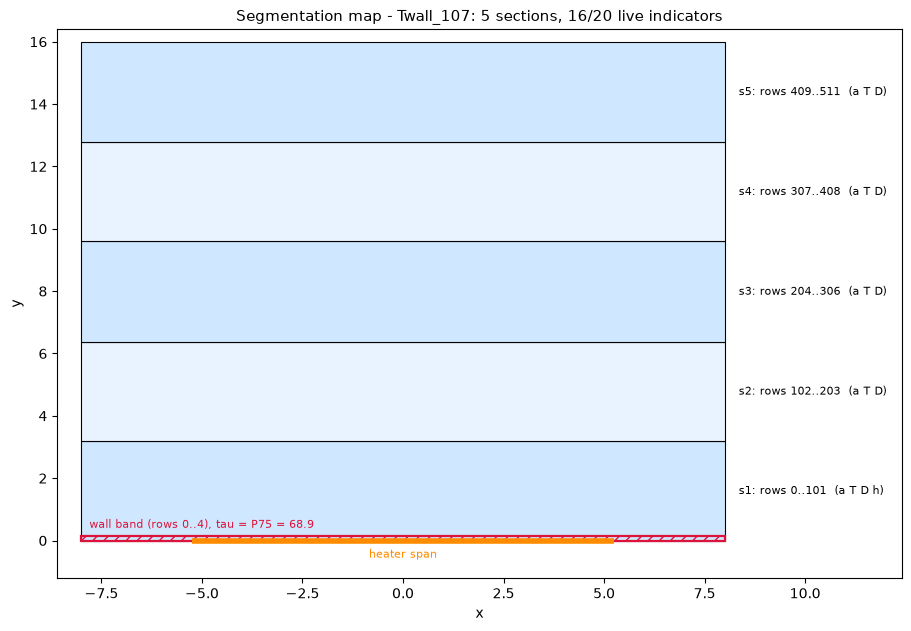

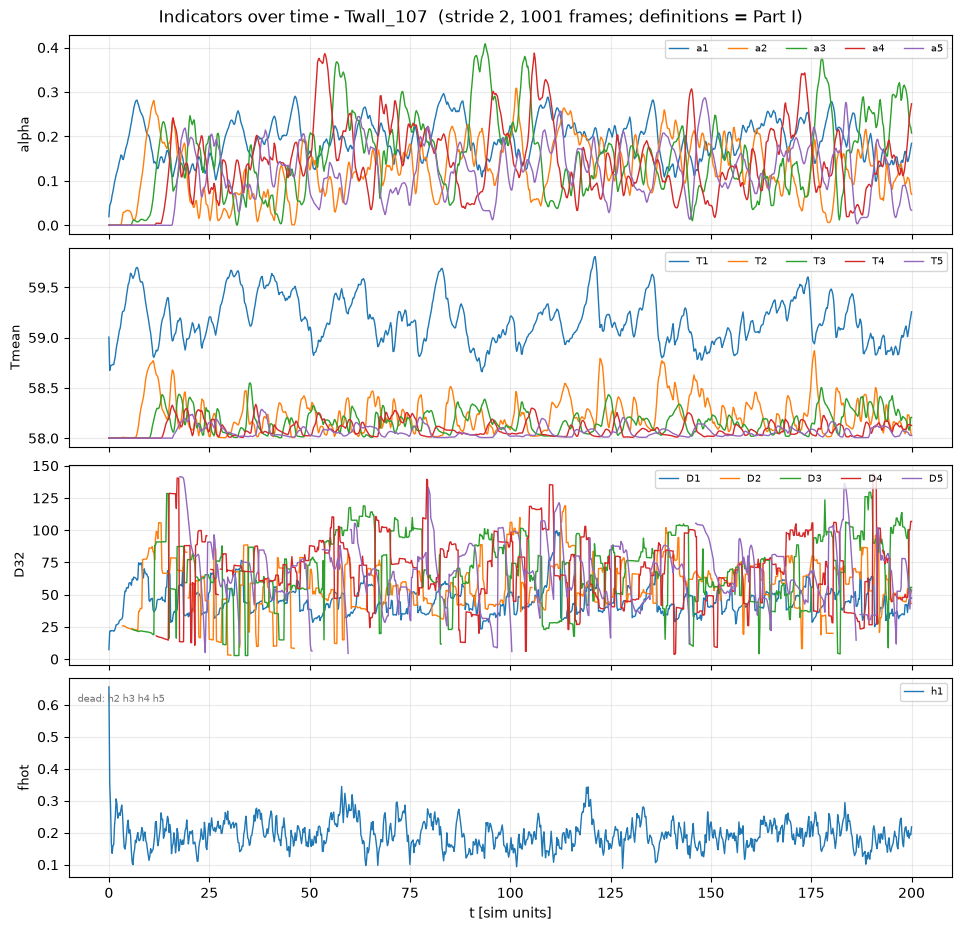


PART II CELL 2 - INDICATORS - Twall_107

--------------------------------------------------------------------------------
TABLE 1 - THETA HEALTH & STATISTICS (live/dead detected, not assumed)
--------------------------------------------------------------------------------
indicator  short  family  sec  status  mean    std      min      max
---------  -----  ------  ---  ------  ------  -------  -------  ------
alpha_s1      a1   alpha    1    live  0.1918  0.04502  0.01951  0.2964
alpha_s2      a2   alpha    2    live  0.1262  0.06428        0  0.3087
alpha_s3      a3   alpha    3    live  0.1551  0.09172        0  0.4087
alpha_s4      a4   alpha    4    live  0.1423  0.08336        0  0.3876
alpha_s5      a5   alpha    5    live   0.117   0.0652        0  0.2866
Tmean_s1      T1   Tmean    1    live   59.17   0.2331    58.66   59.81
Tmean_s2      T2   Tmean    2    live   58.23   0.1732       58   58.87
Tmean_s3      T3   Tmean    3    live   58.16   0.1151       58   58.55
Tmean_s4 

In [16]:
# ====== PART II CELL 2 / 5 — INDICATORS: stream the file, build theta ==========
# One streaming pass at STRIDE. Produces TH (N x 4*N_SECTIONS) with EXACTLY the
# Part-I definitions (theta_of_frame, Cell 1), the data-derived hot threshold
# tau, live/dead detection per column, figures, tables, and saves
# out/p2_<TEST>_theta.npz (+ .csv). Cell 3 reuses tau so the ML cache and this
# panel share one indicator definition.
assert "H5_PATH" in globals() and "theta_of_frame" in globals(), \
    "[P2] run Cell 1 first (config, data & segmentation)"
from scipy.stats import spearmanr

fidx = list(range(0, Tn, STRIDE))
N    = len(fidx)

# ---- pre-pass: the wall band of every sampled frame -> tau (data-derived) -----
with h5py.File(H5_PATH, "r") as F:
    wb_all = np.asarray(F["temperature"][fidx, :WALL_ROWS, :], np.float64)
    tau    = float(np.quantile(wb_all.reshape(len(fidx), -1), TAU_LEVEL))
print(f"[P2] tau = P{int(TAU_LEVEL * 100)} of the wall band over {N} frames "
      f"= {tau:.4g}   (data-derived, stored with the panel)")

# ---- main pass: theta per frame ------------------------------------------------
TH   = np.full((N, NTH), np.nan)
TrowL = np.full((N, H), np.nan, np.float32)   # heater-col liquid-only row means
fmin, fmax, fsum = np.inf, -np.inf, 0.0
with h5py.File(H5_PATH, "r") as F:
    for j, fi in enumerate(fidx):
        d  = np.asarray(F["dfun"][fi], np.float32)
        Tf = np.asarray(F["temperature"][fi], np.float32)
        TH[j] = theta_of_frame(Tf, d, tau, edges, WALL_ROWS, MIN_BLOB_PX)
        phi   = d > 0
        liqH  = ~phi[:, hc]
        cntH  = liqH.sum(axis=1)
        TfH   = Tf[:, hc]
        TrowL[j] = np.where(cntH > 0,
                            np.where(liqH, TfH, 0.0).sum(axis=1) / np.maximum(cntH, 1),
                            np.nan)
        fmin = min(fmin, float(Tf.min())); fmax = max(fmax, float(Tf.max()))
        fsum += float(Tf.mean())
        if j and j % 200 == 0:
            print(f"[P2]   ... {j}/{N} frames done")
t = tvals[fidx]
_dt = float(np.median(np.diff(t))) if N > 1 else 1.0

# ---- live / dead detection (per column, warning-free, never assumed) ----------
LIVE, DEAD = [], []
for j in range(NTH):
    m = np.isfinite(TH[:, j])
    if m.sum() >= 2 and float(np.std(TH[m, j])) > 1e-12:
        LIVE.append(j)
    else:
        DEAD.append(j)
DEADS = [SHORT_TH[NAMES_TH[j]] for j in DEAD]
NLIVE = len(LIVE)
_struct = bool(DEADS) and all(s[0] == "h" for s in DEADS)

# ---- empirical Tsat & scale check ----------------------------------------------
_up  = TrowL[:, H // 2:]
_ok  = np.isfinite(_up)
_Tsat = float(np.quantile(_up[_ok], 0.01)) if _ok.any() else float("nan")
_scale_ok = (np.isfinite(COND["wallTemp"]) and np.isfinite(fmax)
             and abs(fmax - COND["wallTemp"]) <= 0.05 * abs(COND["wallTemp"]))

# ---- FIG 1: segmentation map ----------------------------------------------------
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(9.0, 6.2), constrained_layout=True)
for k in range(N_SECTIONS):
    r0, r1 = int(edges[k]), int(edges[k + 1])
    y0, y1 = y_min + r0 * dy, y_min + r1 * dy
    ax.add_patch(Rectangle((x_min, y0), x_max - x_min, y1 - y0,
                           facecolor="#cfe8ff" if k % 2 == 0 else "#e8f3ff",
                           edgecolor="k", lw=0.8))
    fams = "a T D" + (" h" if k == 0 else "")
    ax.text(x_max + 0.35, (y0 + y1) / 2,
            f"s{k + 1}: rows {r0}..{r1 - 1}  ({fams})",
            va="center", fontsize=8)
ax.add_patch(Rectangle((x_min, y_min), x_max - x_min, WALL_ROWS * dy,
                       facecolor="none", edgecolor="crimson", lw=1.6,
                       hatch="///"))
ax.text(x_min + 0.2, y_min + WALL_ROWS * dy + 0.25,
        f"wall band (rows 0..{WALL_ROWS - 1}), tau = P{int(TAU_LEVEL * 100)} = {tau:.3g}",
        fontsize=8, color="crimson")
if np.isfinite(HX0) and np.isfinite(HX1):
    ax.plot([HX0, HX1], [y_min, y_min], color="darkorange", lw=4,
            solid_capstyle="butt")
    ax.text((HX0 + HX1) / 2, y_min - 0.55, "heater span", ha="center",
            fontsize=8, color="darkorange")
ax.set_xlim(x_min - 0.6, x_max + 4.4)
ax.set_ylim(y_min - 1.2, y_max + 0.4)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title(f"Segmentation map - {TEST}: {N_SECTIONS} sections, "
             f"{NLIVE}/{NTH} live indicators", fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_segmap.png"), dpi=150)
plt.show()

# ---- FIG 2: theta time series by family -----------------------------------------
fams = [("alpha", 0, N_SECTIONS), ("Tmean", N_SECTIONS, 2 * N_SECTIONS),
        ("D32", 2 * N_SECTIONS, 3 * N_SECTIONS),
        ("fhot", 3 * N_SECTIONS, NTH)]
fig, axs = plt.subplots(4, 1, figsize=(9.5, 9.2), sharex=True,
                        constrained_layout=True)
for ax, (fam, j0, j1) in zip(axs, fams):
    cols = [j for j in range(j0, j1) if j in LIVE]
    for j in cols:
        ax.plot(t, TH[:, j], lw=1.0, label=SHORT_TH[NAMES_TH[j]])
    dead = [SHORT_TH[NAMES_TH[j]] for j in range(j0, j1) if j not in LIVE]
    ax.set_ylabel(fam, fontsize=9)
    ax.grid(alpha=0.25)
    if cols:
        ax.legend(fontsize=7, ncol=min(len(cols), 5), loc="upper right")
    if dead:
        ax.text(0.01, 0.92, "dead: " + " ".join(dead), transform=ax.transAxes,
                fontsize=7, color="0.45", va="top")
axs[-1].set_xlabel("t [sim units]")
fig.suptitle(f"Indicators over time - {TEST}  "
             f"(stride {STRIDE}, {N} frames; definitions = Part I)",
             fontsize=12)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_theta.png"), dpi=150)
plt.show()

# ---- tables ----------------------------------------------------------------------
print()
print("=" * W_)
print(f"PART II CELL 2 - INDICATORS - {TEST}")
print("=" * W_)
_rows1 = []
for j in range(NTH):
    nm = NAMES_TH[j]
    fam, sec = nm.rsplit("_s", 1)
    if j in LIVE:
        v = TH[:, j]; m = np.isfinite(v); s = v[m]
        _rows1.append([nm, SHORT_TH[nm], fam, sec, "live",
                       _g(s.mean()), _g(s.std()), _g(s.min()), _g(s.max())])
    else:
        _rows1.append([nm, SHORT_TH[nm], fam, sec, "dead",
                       "n/a", "n/a", "n/a", "n/a"])
_note1 = (f"{NLIVE}/{NTH} live; dead: {' '.join(DEADS) or 'none'}"
          + ("  -> structural: fhot is a wall-band statistic; only the section "
             "holding the wall band gets it. With other data / another "
             "threshold / coarser sections more columns go live automatically."
             if _struct else ""))
_render("TABLE 1 - THETA HEALTH & STATISTICS (live/dead detected, not assumed)",
        ["indicator", "short", "family", "sec", "status",
         "mean", "std", "min", "max"], _rows1, _note1)

_rows2 = [
    ["tau (hot threshold)", _g(tau), f"P{int(TAU_LEVEL * 100)} of the wall band, all "
     f"{N} sampled frames"],
    ["T field min / mean / max",
     f"{_g(fmin)} / {_g(fsum / N)} / {_g(fmax)}", "streamed extremes"],
    ["bulk P1 (empirical Tsat)", _g(_Tsat),
     "1st pct of liquid-only heater-column row means, upper half"],
    ["sidecar wallTemp", _g(COND["wallTemp"], "%.1f"),
     ("one scale; empirical superheat ~ "
      + _g(COND["wallTemp"] - _Tsat, "%.1f") if _scale_ok
      else "field scale differs -> solver-native units")],
    ["frames sampled", f"{N} of {Tn} (stride {STRIDE})",
     f"dt_sample {_g(_dt, '%.3g')}"],
]
_render("TABLE 2 - SCALE & THRESHOLD CARD (all data-derived)", 
        ["quantity", "value", "note"], _rows2)

def _rhot(v):
    v = np.asarray(v, float); m = np.isfinite(v)
    if m.sum() >= 5 and float(np.std(v[m])) > 1e-12:
        return float(spearmanr(v[m], t[m])[0])
    return None

_rows3 = []
for j in LIVE:
    r = _rhot(TH[:, j])
    a = abs(r) if r is not None else 0.0
    _rows3.append([SHORT_TH[NAMES_TH[j]], f"{r:+.2f}",
                   "clock-like" if a >= 0.95 else "strong" if a >= 0.80
                   else "mild" if a >= 0.50 else "-"])
_rows3.sort(key=lambda r: -abs(float(r[1])))
_render("TABLE 3 - DRIFT AUDIT: Spearman rho vs t (why the ML split is "
        "time-blocked)", ["indicator", "rho_t", "drift"], _rows3,
        "Clock-like indicators co-move with everything that grows; a random "
        "split would let the models memorize the startup transient and fake "
        "accuracy. Cell 3 therefore splits by TIME, testing on the late regime.")

# ---- save the indicator panel ----------------------------------------------------
_meta = {"label": TEST, "Tn": Tn, "H": H, "W": W, "dx": dx, "dy": dy,
         "x_min": x_min, "x_max": x_max, "y_min": y_min, "y_max": y_max,
         "edges": np.asarray(edges).tolist(), "tau": tau,
         "N_SECTIONS": N_SECTIONS, "WALL_ROWS": WALL_ROWS,
         "TAU_LEVEL": TAU_LEVEL, "MIN_BLOB_PX": MIN_BLOB_PX,
         "dt_sample": _dt, "stride": STRIDE,
         "names": NAMES_TH, "short": SHORT_TH,
         "live": LIVE, "columns": ["t"] + NAMES_TH}
np.savez_compressed(os.path.join(OUT_DIR, f"p2_{TEST}_theta.npz"),
                    meta=json.dumps(_meta), t=t, TH=TH,
                    TrowL=TrowL)
np.savetxt(os.path.join(OUT_DIR, f"p2_{TEST}_theta.csv"),
           np.column_stack([t, TH]), delimiter=",", fmt="%.6g",
           header=",".join(["t"] + NAMES_TH), comments="")
print()
print(f"[P2] indicator panel saved: p2_{TEST}_theta.npz (+ .csv, "
      f"{TH.shape[0]} rows x {TH.shape[1] + 1} cols)")
print("[P2] next: run Cell 3 (ML cache + time-blocked split + round-trip "
      "harness)")


## Cell 3 — ML data cache, split, harness

Caches every frame at `ML_STRIDE` (default 1) as float16 with both channels
(temperature, vapor field), re-extracts the indicators at that stride, makes the
**time-blocked** 70/15/15 split (never shuffled - the startup clock must not leak),
and computes train-only scalers. After this cell, Cells 4-5 never touch the HDF5.

[P2]   ... 500/2001 frames cached
[P2]   ... 1000/2001 frames cached
[P2]   ... 1500/2001 frames cached
[P2]   ... 2000/2001 frames cached
[P2] cache saved: p2_Twall_107_cache.npz  (2001 frames, 1104 MB)


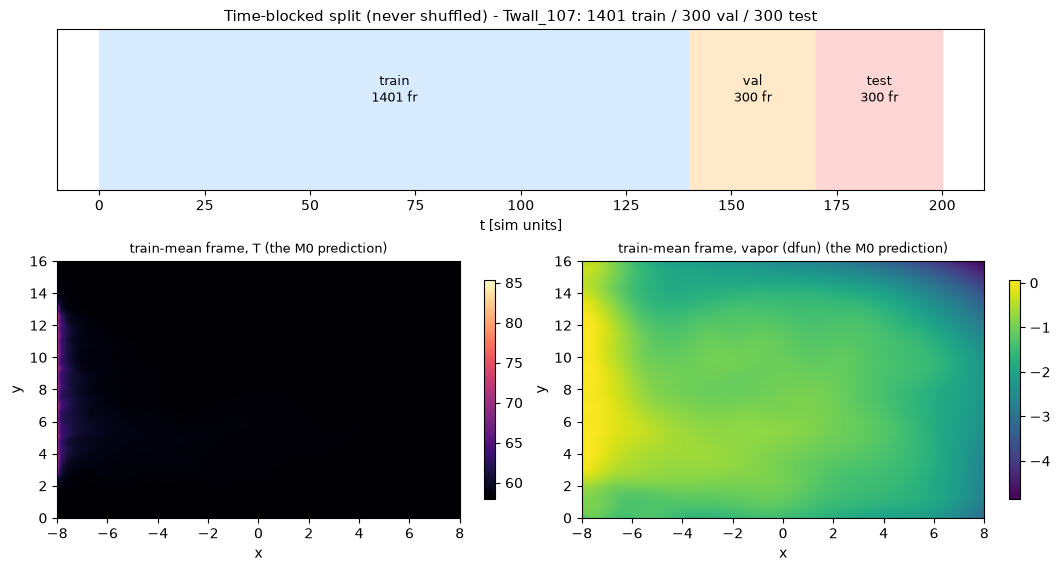


PART II CELL 3 - ML CACHE & SPLIT - Twall_107

--------------------------------------------------------------------------------
TABLE 1 - CACHE CARD
--------------------------------------------------------------------------------
item           value                         note
-------------  ----------------------------  ---------------------------------------------------------------------------------------------------
frames cached       2001 of 2001 (stride 1)                                                     512 x 512 x 2 channels, float16; 1104 MB on disk
channels       T | vapor (dfun, continuous)  the models regress the CONTINUOUS fields; binarization happens only inside the round-trip extractor
indicators                    16 live of 20               same definitions as Cell 2 (tau 68.9); dead/constant columns are masked, never assumed
dt_sample                               0.1                                                                           time between cached f

In [17]:
# ====== PART II CELL 3 / 5 — ML DATA CACHE, TIME-BLOCKED SPLIT, HARNESS ========
# Streams the file ONCE at ML_STRIDE (default 1 = every frame) and caches:
#   frames (N x H x W x 2) float16  [channel 0 = T, channel 1 = dfun (vapor)]
#   TH_ml  (N x 4*N_SECTIONS)       indicators, same definitions as Cell 2
#   tau    the Cell-2 hot threshold (kernel, else the saved panel, else recomputed)
# plus the time-blocked train/val/test split and train-only scalers.
# Saves out/p2_<TEST>_cache.npz - Cells 4-5 run from this file alone, so a
# kernel restart never re-streams the HDF5. Needs Cells 1-2 in the kernel.
assert "H5_PATH" in globals() and "theta_of_frame" in globals(), \
    "[P2] run Cells 1-2 first (segmentation + indicators)"

# ---- tau: kernel (Cell 2) -> saved panel -> recompute from the cache sample --
_tau = _f(globals().get("tau"))
if not np.isfinite(_tau):
    _pth = os.path.join(OUT_DIR, f"p2_{TEST}_theta.npz")
    if os.path.exists(_pth):
        with np.load(_pth, allow_pickle=False) as _z:
            _tau = _f(json.loads(str(_z["meta"]))["tau"])
        print(f"[P2] tau taken from the saved panel: {_g(_tau)}")

fidx_ml = list(range(0, Tn, ML_STRIDE))
NML     = len(fidx_ml)

# ---- one streaming pass: frames + indicators -----------------------------------
frames = np.empty((NML, H, W, 2), np.float16)
TH_ml  = np.full((NML, NTH), np.nan, np.float32)
with h5py.File(H5_PATH, "r") as F:
    if not np.isfinite(_tau):
        _wb = np.asarray(F["temperature"][fidx_ml, :WALL_ROWS, :], np.float64)
        _tau = float(np.quantile(_wb.reshape(NML, -1), TAU_LEVEL))
        print(f"[P2] no panel tau -> recomputed from the cache sample: {_tau:.4g}")
    for j, fi in enumerate(fidx_ml):
        d  = np.asarray(F["dfun"][fi], np.float32)
        Tf = np.asarray(F["temperature"][fi], np.float32)
        frames[j, :, :, 0] = Tf
        frames[j, :, :, 1] = d
        TH_ml[j] = theta_of_frame(Tf, d, _tau, edges, WALL_ROWS, MIN_BLOB_PX)
        if j and j % 500 == 0:
            print(f"[P2]   ... {j}/{NML} frames cached")
tau = float(_tau)
t_ml = tvals[fidx_ml]
_dt  = float(np.median(np.diff(t_ml))) if NML > 1 else 1.0

# ---- time-blocked split (never shuffled: the clock must not leak) -------------
ntr = int(round(NML * SPLITS[0]))
nva = int(round(NML * SPLITS[1]))
nte = NML - ntr - nva
assert min(ntr, nva, nte) >= 2 and ntr >= 8, \
    (f"[P2] cache too small for the split ({NML} frames -> {ntr}/{nva}/{nte}); "
     "lower ML_STRIDE or use a longer file")
itr, iva, ite = np.arange(ntr), np.arange(ntr, ntr + nva), np.arange(ntr + nva, NML)
if ntr < 30:
    print(f"[P2] warning: only {ntr} training frames - expect weak models")

# ---- live inputs & train-only scalers (no leakage, NaN-safe) -------------------
# D32 is NaN on frames whose sections hold no bubbles (e.g. before the first
# nucleation): train stats use the FINITE entries only, and Cell 4 imputes
# missing entries to the train mean (z = 0). Columns with no finite TRAIN
# entry at all are dropped - detected, never assumed.
LIVE_ML, _drop = [], []
for j in range(NTH):
    m = np.isfinite(TH_ml[:, j])
    if m.sum() >= 2 and float(np.std(TH_ml[m, j])) > 1e-12:
        LIVE_ML.append(j)
    else:
        _drop.append(j)
_keep = []
for j in LIVE_ML:
    mtr = np.isfinite(TH_ml[itr, j])
    if mtr.any():
        _keep.append((j, float(TH_ml[itr, j][mtr].mean()),
                      float(TH_ml[itr, j][mtr].std())))
    else:
        _drop.append(j)
LIVE_ML = np.asarray([k[0] for k in _keep], int)
z_mu = np.asarray([k[1] for k in _keep], float)
z_sd = np.maximum(np.asarray([k[2] for k in _keep], float), 1e-12)

# ---- frame statistics (train only) ----------------------------------------------
mu_frame = frames[itr].astype(np.float32).mean(axis=0,
                                               dtype=np.float64).astype(np.float32)
rng_ch   = np.asarray([float(frames[itr, :, :, c].astype(np.float32).max()
                            - frames[itr, :, :, c].astype(np.float32).min())
                       for c in range(2)])
for c in range(2):
    if not np.isfinite(rng_ch[c]) or rng_ch[c] < 1e-12:
        rng_ch[c] = 1.0
        print(f"[P2] warning: channel {c} has ~zero train range -> PSNR n/a")

# ---- save the cache ---------------------------------------------------------------
_meta = {"label": TEST, "Tn": Tn, "H": H, "W": W, "dx": dx, "dy": dy,
         "x_min": x_min, "x_max": x_max, "y_min": y_min, "y_max": y_max,
         "edges": np.asarray(edges).tolist(), "tau": tau,
         "N_SECTIONS": N_SECTIONS, "NTH": NTH, "WALL_ROWS": WALL_ROWS,
         "TAU_LEVEL": TAU_LEVEL, "MIN_BLOB_PX": MIN_BLOB_PX,
         "ML_STRIDE": ML_STRIDE, "splits": list(SPLITS),
         "dt_sample": _dt, "names": NAMES_TH, "short": SHORT_TH,
         "live": LIVE_ML.tolist(), "ntr": ntr, "nva": nva, "nte": nte,
         "channels": ["T", "dfun"]}
_cache = os.path.join(OUT_DIR, f"p2_{TEST}_cache.npz")
np.savez_compressed(_cache, meta=json.dumps(_meta), frames=frames, TH=TH_ml,
                    t=t_ml, tau=tau, edges=np.asarray(edges),
                    live=LIVE_ML, itr=itr, iva=iva, ite=ite,
                    z_mu=z_mu, z_sd=z_sd, mu_frame=mu_frame, rng_ch=rng_ch)
_sz = os.path.getsize(_cache) / 1e6
print(f"[P2] cache saved: p2_{TEST}_cache.npz  ({NML} frames, {_sz:.0f} MB)")

# ---- FIG: the split + what the models must reproduce ------------------------------
fig = plt.figure(figsize=(10.5, 5.6), constrained_layout=True)
gs  = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.6])
ax0 = fig.add_subplot(gs[0, :])
for _ix, (_lab, _col) in enumerate((("train", "#d9ecff"), ("val", "#ffe9c9"),
                                     ("test", "#ffd6d6"))):
    _ii = (itr, iva, ite)[_ix]
    ax0.axvspan(t_ml[_ii[0]], t_ml[_ii[-1]], color=_col)
    ax0.text((t_ml[_ii[0]] + t_ml[_ii[-1]]) / 2, 0.55,
             f"{_lab}\n{len(_ii)} fr", ha="center", fontsize=9)
ax0.set_ylim(0, 1); ax0.set_yticks([])
ax0.set_xlabel("t [sim units]")
ax0.set_title(f"Time-blocked split (never shuffled) - {TEST}: "
              f"{ntr} train / {nva} val / {nte} test", fontsize=11)
for _c, (_lab, _cmap) in enumerate((("T", "magma"), ("vapor (dfun)", "viridis"))):
    ax = fig.add_subplot(gs[1, _c])
    im = ax.imshow(mu_frame[:, :, _c].T, origin="lower", cmap=_cmap,
                   extent=[x_min, x_max, y_min, y_max], aspect="auto")
    ax.set_title(f"train-mean frame, {_lab} (the M0 prediction)", fontsize=9)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_split.png"), dpi=150)
plt.show()

# ---- tables -------------------------------------------------------------------------
print()
print("=" * W_)
print(f"PART II CELL 3 - ML CACHE & SPLIT - {TEST}")
print("=" * W_)
_rows1 = [
    ["frames cached", f"{NML} of {Tn} (stride {ML_STRIDE})",
     f"{H} x {W} x 2 channels, float16; {_sz:.0f} MB on disk"],
    ["channels", "T | vapor (dfun, continuous)",
     "the models regress the CONTINUOUS fields; binarization happens only "
     "inside the round-trip extractor"],
    ["indicators", f"{len(LIVE_ML)} live of {NTH}",
     "same definitions as Cell 2 (tau "
     + _g(tau, "%.3g") + "); dead/constant columns are masked, never assumed"],
    ["dt_sample", _g(_dt, "%.3g"),
     "time between cached frames"],
]
_render("TABLE 1 - CACHE CARD", ["item", "value", "note"], _rows1)

_rows2 = []
for _lab, _ii in (("train", itr), ("val", iva), ("test", ite)):
    _rows2.append([_lab, str(len(_ii)),
                   f"{_g(t_ml[_ii[0]], '%g')} -> {_g(t_ml[_ii[-1]], '%g')}",
                   f"{100 * len(_ii) / NML:.0f}%",
                   ("models fit here" if _lab == "train" else
                    "hyper-parameters chosen here" if _lab == "val" else
                    "scored here only (leaderboard)")])
_render("TABLE 2 - TIME-BLOCKED SPLIT (train-only scalers; no leakage)",
        ["block", "frames", "t range", "share", "role"], _rows2)

_rows3 = []
for _p, _j in enumerate(LIVE_ML):
    _rows3.append([NAMES_TH[_j], SHORT_TH[NAMES_TH[_j]],
                   _g(np.nan if not np.isfinite(TH_ml[:, _j]).any()
                      else TH_ml[np.isfinite(TH_ml[:, _j]), _j].mean()),
                   _g(z_mu[_p]), _g(z_sd[_p])])
_render("TABLE 3 - MODEL INPUTS (live indicators, z-scored with train stats)",
        ["indicator", "short", "cache mean", "train mean", "train std"],
        _rows3,
        ("masked (dead/constant/no train data): "
         + (" ".join(SHORT_TH[NAMES_TH[j]] for j in _drop) or "none")
         + " - the input width follows the segmentation, not a fixed number; "
           "NaN entries (e.g. D32 before the first bubble) are imputed to the "
           "train mean in Cell 4"))

print()
print("[P2] next: run Cell 4 (Phase-1 ladder: M0 mean, M1 PCA+ridge, M2 k-NN)")


## Cell 4 — the Phase-1 ladder

Three deterministic baselines, conditioned on the live indicators:

- **M0** mean frame - the floor;
- **M1** PCA + ridge - "eigenframes" with a linear theta-to-weights map (alpha and
  the component count chosen on the validation block);
- **M2** k-NN retrieval - the average of the k closest-theta training frames.

Hyper-parameters are selected **only on the val block**; the test block stays
untouched until Cell 5.

[P2] cache loaded: 2001 frames, 1401/300/300 split, 16 live indicators, d = 524288 per frame
[P2] note: 454 NaN indicator entries in TRAIN imputed to z=0 (D32 before bubbles exist, etc.)
[P2] PCA: 64 eigenframes in 2.8s; top-4 explain 48.2% of frame variance
[P2] predictions saved: p2_Twall_107_m0/m1/m2_pred.npz


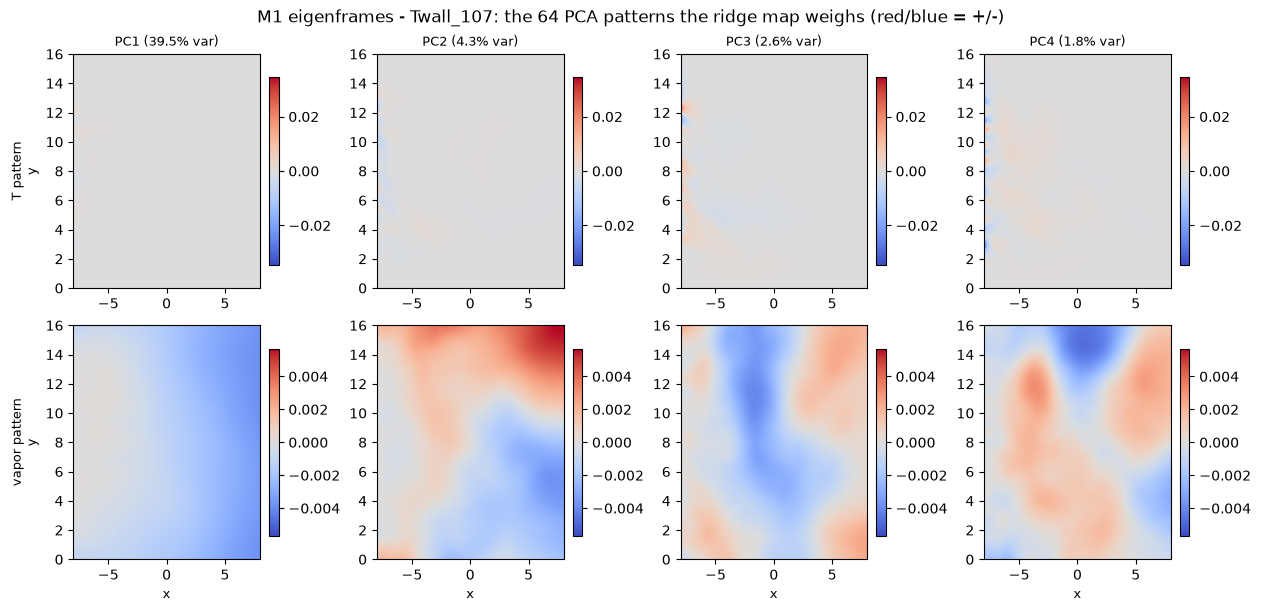

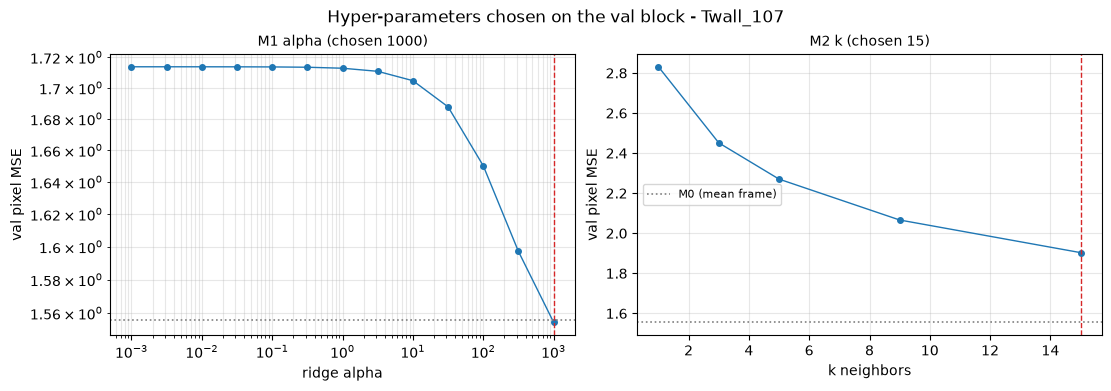


PART II CELL 4 - PHASE-1 LADDER - Twall_107

--------------------------------------------------------------------------------
TABLE 1 - THE LADDER (all deterministic; val pixel MSE, lower = better)
--------------------------------------------------------------------------------
model  configuration                       what it does                                    val MSE  role
-----  ----------------------------------  ----------------------------------------------  -------  --------------------------
M0                             mean frame               train-average frame for any theta    1.556                   the floor
M1     PCA + ridge (64 comps, alpha 1000)          linear map theta -> eigenframe weights    1.554          the linear ceiling
M2                          k-NN (k = 15)  average of the k closest-theta training frames    1.903  the non-parametric ceiling
  M0/M1/M2 are the baselines M3 (a small conditional net) must beat. Val block only - test is scored in Cel

In [18]:
# ====== PART II CELL 4 / 5 — PHASE-1 LADDER: M0 / M1 / M2 =======================
# Three deterministic baselines, condition = the live indicators (z-scored):
#   M0  mean frame         always the train-average frame (the floor)
#   M1  PCA + ridge        "eigenframes": top-N_PCA frame patterns, linear map
#                          theta -> pattern weights (alpha chosen on val)
#   M2  k-NN retrieval     average of the k training frames with closest theta
#                          (k chosen on val)
# Pure NumPy (no sklearn/torch needed), fully deterministic (no seeds).
# Runs from out/p2_<TEST>_cache.npz (Cell 3) - a kernel restart is fine.
# Saves out/p2_<TEST>_m{0,1,2}_pred.npz (test predictions) for Cell 5.
import json, os, time
import numpy as np

try: TEST
except NameError: TEST = "Twall_107"
try: DATA_ROOT
except NameError: DATA_ROOT = r"G:\BoilDesc"
try: OUT_DIR
except NameError: OUT_DIR = os.path.join(DATA_ROOT, "out")
for _k, _v in dict(N_PCA=64, KNN_GRID=(1, 3, 5, 9, 15),
                   RIDGE_LOGA=(-3.0, 3.0, 13)).items():
    if _k not in dir():
        globals()[_k] = _v
        print(f"[P2] {_k} not defined -> default {_v}")
W_ = int(globals().get("W_", 80))

_CPATH = os.path.join(OUT_DIR, f"p2_{TEST}_cache.npz")
assert os.path.exists(_CPATH), \
    f"[P2] cache not found ({_CPATH}); run Cell 3 first"
with np.load(_CPATH, allow_pickle=False) as _z:
    CM   = json.loads(str(_z["meta"]))
    FR   = np.asarray(_z["frames"])          # (N,H,W,2) f16
    THc  = np.asarray(_z["TH"], float)       # (N, NTH)
    LIVE = np.asarray(_z["live"], int)
    itr, iva, ite = (np.asarray(_z[k], int) for k in ("itr", "iva", "ite"))
    z_mu, z_sd = np.asarray(_z["z_mu"], float), np.asarray(_z["z_sd"], float)
    mu_frame   = np.asarray(_z["mu_frame"], np.float32)
H, W = CM["H"], CM["W"]
ntr, nva, nte = len(itr), len(iva), len(ite)
NAMES_L = [CM["names"][j] for j in LIVE]
SHORT_L = [CM["short"][n] for n in NAMES_L]
p, d = len(LIVE), H * W * 2
print(f"[P2] cache loaded: {FR.shape[0]} frames, {ntr}/{nva}/{nte} split, "
      f"{p} live indicators, d = {d} per frame")

def _g(v, fmt="%.4g"):
    v = float(v)
    return "n/a" if not np.isfinite(v) else fmt % v

def _render(title, cols, rows, note=None):
    print()
    print("-" * W_)
    print(title)
    print("-" * W_)
    if not rows:
        print("  (nothing to show)")
    else:
        _rs = [[str(c) for c in r] for r in rows]
        _w = [max([len(cols[_c])] + [len(_r[_c]) for _r in _rs])
              for _c in range(len(cols))]
        print("  ".join(cols[_c].ljust(_w[_c])
                        for _c in range(len(cols))).rstrip())
        print("  ".join("-" * _w[_c] for _c in range(len(cols))).rstrip())
        for _r in _rs:
            print("  ".join(_r[_c].ljust(_w[_c]) if _c == 0 else _r[_c].rjust(_w[_c])
                            for _c in range(len(cols))).rstrip())
    if note:
        print("  " + note)

# ---- standardized theta (the conditioning variable) -----------------------------
# NaN entries (e.g. D32 on frames with no bubbles in a section) are imputed to
# the train mean (z = 0) - the standard 'no information' value.
_raw = THc[:, LIVE]
Z = np.where(np.isfinite(_raw), (_raw - z_mu) / z_sd, 0.0)
_nimp = int((~np.isfinite(_raw[itr])).sum())
if _nimp:
    print(f"[P2] note: {_nimp} NaN indicator entries in TRAIN imputed to z=0 "
          "(D32 before bubbles exist, etc.)")
Ztr = np.column_stack([Z[itr], np.ones(ntr)])      # + intercept
Zva = np.column_stack([Z[iva], np.ones(nva)])
Zte = np.column_stack([Z[ite], np.ones(nte)])

# ---- frame matrices (train centered in place; mu = the M0 prediction) ----------
Xtr = FR[itr].reshape(ntr, d).astype(np.float32)
Xva = FR[iva].reshape(nva, d).astype(np.float32)
FRtr = FR[itr]                                    # one fancy-index copy (f16)
mu  = Xtr.mean(axis=0, dtype=np.float64).astype(np.float32)
Xtr -= mu
t0 = time.time()

# ---- PCA via the Gram matrix (N x d with N << d: eigen of Xc Xc^T) -------------
k_pca = int(min(N_PCA, ntr - 1))
G = (Xtr @ Xtr.T).astype(np.float64)
w_ev, U_ev = np.linalg.eigh(G)
_pos = w_ev[w_ev > 0].sum()
_order = np.argsort(w_ev)[::-1][:k_pca]
lam = np.maximum(w_ev[_order], 0.0)
V = (U_ev[:, _order].T.astype(np.float32) @ Xtr)          # (k, d)
V /= np.maximum(np.linalg.norm(V, axis=1, keepdims=True), 1e-12)
evr = lam / _pos if _pos > 0 else np.zeros(k_pca)
Str = (Xtr @ V.T).astype(np.float64)                      # (ntr, k)
print(f"[P2] PCA: {k_pca} eigenframes in {time.time() - t0:.1f}s; "
      f"top-4 explain {100 * evr[:4].sum():.1f}% of frame variance")

def _mse(A, B):
    return float(np.mean((A - B) ** 2))

mse_m0_val = _mse(Xva, mu[None, :].astype(np.float32))

# ---- M1: ridge  theta -> PCA scores, alpha chosen on the val block -------------
alphas = np.logspace(RIDGE_LOGA[0], RIDGE_LOGA[1], int(RIDGE_LOGA[2]))
ZtZ, ZtS = Ztr.T @ Ztr, Ztr.T @ Str
_mse_a = []
for a in alphas:
    Wr = np.linalg.solve(ZtZ + a * np.eye(ZtZ.shape[0]), ZtS)
    R = mu + (Zva @ Wr).astype(np.float32) @ V
    _mse_a.append(_mse(Xva, R))
a_best = float(alphas[int(np.argmin(_mse_a))])
W_best = np.linalg.solve(ZtZ + a_best * np.eye(ZtZ.shape[0]), ZtS)
pred_m1 = (mu + (Zte @ W_best).astype(np.float32) @ V).reshape(nte, H, W, 2)
# clip to the per-channel TRAIN range: the fields are physical, linear
# extrapolation outside their observed range is phantom structure (it would
# grow one giant blob and wreck the D32 round-trip in Cell 5)
for c in range(2):
    _lo = float(FRtr[:, :, :, c].astype(np.float32).min())
    _hi = float(FRtr[:, :, :, c].astype(np.float32).max())
    np.clip(pred_m1[:, :, :, c], _lo, _hi, out=pred_m1[:, :, :, c])
mse_m1_val = float(_mse_a[int(np.argmin(_mse_a))])

# ---- M2: k-NN in theta space, k chosen on the val block ------------------------
Dva = ((Z[iva][:, None, :] - Z[itr][None, :, :]) ** 2).sum(-1)
Dte = ((Z[ite][:, None, :] - Z[itr][None, :, :]) ** 2).sum(-1)
k_grid = [int(k) for k in KNN_GRID if 1 <= int(k) <= ntr]
_mse_k = []
for k in k_grid:
    acc = 0.0
    for i in range(nva):
        nb = np.argsort(Dva[i])[:k]
        acc += _mse(Xva[i], FRtr[nb].astype(np.float32).reshape(k, d).mean(0))
    _mse_k.append(acc / nva)
k_best = k_grid[int(np.argmin(_mse_k))]
pred_m2 = np.empty((nte, H, W, 2), np.float16)
for i in range(nte):
    nb = np.argsort(Dte[i])[:k_best]
    pred_m2[i] = FRtr[nb].astype(np.float32).mean(0).astype(np.float16)
mse_m2_val = float(_mse_k[int(np.argmin(_mse_k))])

# ---- save test predictions --------------------------------------------------------
preds = {"m0": (np.broadcast_to(mu.reshape(1, H, W, 2).astype(np.float16),
                                (nte, H, W, 2)).copy(),
                {"kind": "mean frame"}, mse_m0_val),
         "m1": (pred_m1.astype(np.float16),
                {"kind": "PCA + ridge", "n_pca": k_pca, "alpha": a_best,
                 "evr_top4": float(evr[:4].sum()),
                 "clipped": "per-channel train range"}, mse_m1_val),
         "m2": (pred_m2,
                {"kind": "k-NN", "k": k_best}, mse_m2_val)}
for _m, (_P, _cfg, _vm) in preds.items():
    np.savez_compressed(os.path.join(OUT_DIR, f"p2_{TEST}_{_m}_pred.npz"),
                        pred=_P, cfg=json.dumps(_cfg), val_mse=_vm)
print(f"[P2] predictions saved: p2_{TEST}_m0/m1/m2_pred.npz")

# ---- FIG 1: eigenframes ------------------------------------------------------------
import matplotlib.pyplot as plt
ncol = 4
fig, axs = plt.subplots(2, ncol, figsize=(12.5, 6.0), constrained_layout=True)
for row, (ch, lab) in enumerate(((0, "T pattern"), (1, "vapor pattern"))):
    vmax = float(np.abs(V[:ncol].reshape(ncol, H, W, 2)[:, :, :, ch]).max()) or 1.0
    for c in range(ncol):
        ax = axs[row, c]
        im = ax.imshow(V[c].reshape(H, W, 2)[:, :, ch].T, origin="lower",
                       cmap="coolwarm", vmin=-vmax, vmax=vmax,
                       extent=[CM["x_min"], CM["x_max"], CM["y_min"], CM["y_max"]],
                       aspect="auto")
        if row == 0:
            ax.set_title(f"PC{c + 1} ({100 * evr[c]:.1f}% var)", fontsize=9)
        if c == 0:
            ax.set_ylabel(f"{lab}\ny", fontsize=9)
        if row == 1:
            ax.set_xlabel("x", fontsize=9)
        fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle(f"M1 eigenframes - {TEST}: the {k_pca} PCA patterns the ridge map "
             "weighs (red/blue = +/-)", fontsize=12)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_eigen.png"), dpi=150)
plt.show()

# ---- FIG 2: hyper-parameter selection on the val block ------------------------------
fig, axs = plt.subplots(1, 2, figsize=(11.0, 3.8), constrained_layout=True)
ax = axs[0]
ax.loglog(alphas, _mse_a, "o-", ms=4, lw=1.0)
ax.axvline(a_best, color="C3", ls="--", lw=1.0)
ax.axhline(mse_m0_val, color="0.5", ls=":", lw=1.2)
ax.set_xlabel("ridge alpha"); ax.set_ylabel("val pixel MSE")
ax.set_title(f"M1 alpha (chosen {a_best:g})", fontsize=10)
ax.grid(alpha=0.3, which="both")
ax = axs[1]
ax.plot(k_grid, _mse_k, "o-", ms=4, lw=1.0)
ax.axvline(k_best, color="C3", ls="--", lw=1.0)
ax.axhline(mse_m0_val, color="0.5", ls=":", lw=1.2, label="M0 (mean frame)")
ax.set_xlabel("k neighbors"); ax.set_ylabel("val pixel MSE")
ax.set_title(f"M2 k (chosen {k_best})", fontsize=10)
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle(f"Hyper-parameters chosen on the val block - {TEST}", fontsize=12)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_select.png"), dpi=150)
plt.show()

# ---- tables ---------------------------------------------------------------------------
print()
print("=" * W_)
print(f"PART II CELL 4 - PHASE-1 LADDER - {TEST}")
print("=" * W_)
_rows1 = [
    ["M0", "mean frame", "train-average frame for any theta",
     _g(mse_m0_val, "%.4g"), "the floor"],
    ["M1", f"PCA + ridge ({k_pca} comps, alpha {a_best:g})",
     "linear map theta -> eigenframe weights",
     _g(mse_m1_val, "%.4g"), "the linear ceiling"],
    ["M2", f"k-NN (k = {k_best})",
     "average of the k closest-theta training frames",
     _g(mse_m2_val, "%.4g"), "the non-parametric ceiling"],
]
_render("TABLE 1 - THE LADDER (all deterministic; val pixel MSE, lower = better)",
        ["model", "configuration", "what it does", "val MSE", "role"], _rows1,
        "M0/M1/M2 are the baselines M3 (a small conditional net) must beat. "
        "Val block only - test is scored in Cell 5.")

_rows2 = []
_aord = np.argsort(_mse_a)[:5]
for i in _aord:
    _rows2.append(["M1", f"alpha {alphas[i]:g}", _g(_mse_a[i], "%.4g"),
                   "<-- chosen" if alphas[i] == a_best else ""])
for i, k in enumerate(k_grid):
    _rows2.append(["M2", f"k {k}", _g(_mse_k[i], "%.4g"),
                   "<-- chosen" if k == k_best else ""])
_render("TABLE 2 - HYPER-PARAMETER SELECTION (val block, pixel MSE)",
        ["model", "setting", "val MSE", ""], _rows2,
        "Selection uses ONLY the val block; the test block stays untouched "
        "until the Cell-5 leaderboard.")

_rows3 = [[f"PC{i + 1}", f"{100 * evr[i]:.1f}%", f"{100 * evr[:i + 1].sum():.1f}%"]
          for i in range(min(8, k_pca))]
_render("TABLE 3 - EXPLAINED VARIANCE OF THE EIGENFRAMES (M1)",
        ["component", "share", "cumulative"], _rows3,
        f"{100 * evr.sum():.1f}% of frame variance lies in all {k_pca} "
        "components; the rest is texture the ladder cannot see.")

print()
print("[P2] next: run Cell 5 (leaderboard: round-trip through the Part-I "
      "extractor, clear tables + figures)")


## Cell 5 — the leaderboard

Feeds every model's generated frames back through the Part-I extractor
(`theta_of_frame`, identical math) and scores how well the asked indicators come
back out - per family (alpha, Tmean, D32, f_hot) and per indicator, plus a
"soft alpha" diagnostic that separates *level* errors from *blur* errors.
Clear tables quantify exactly what the figures show.

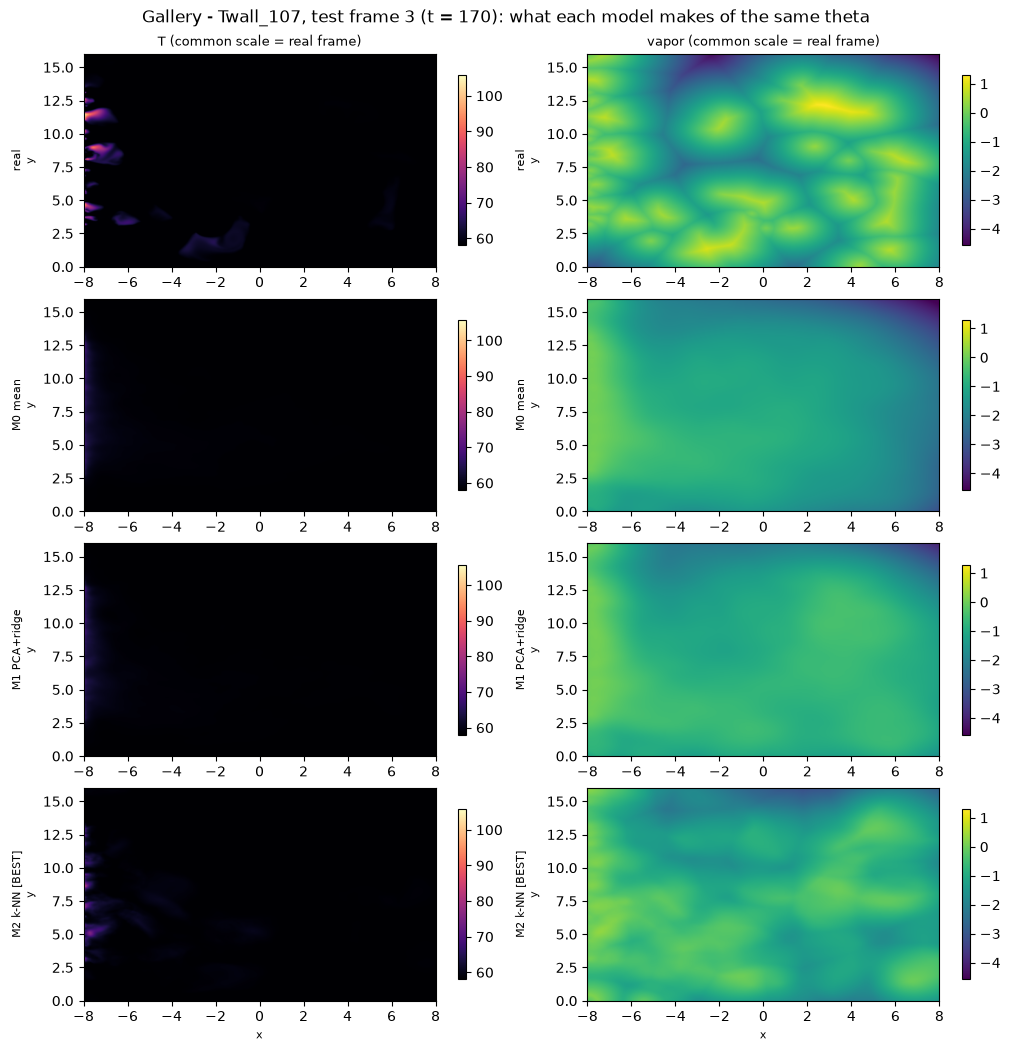

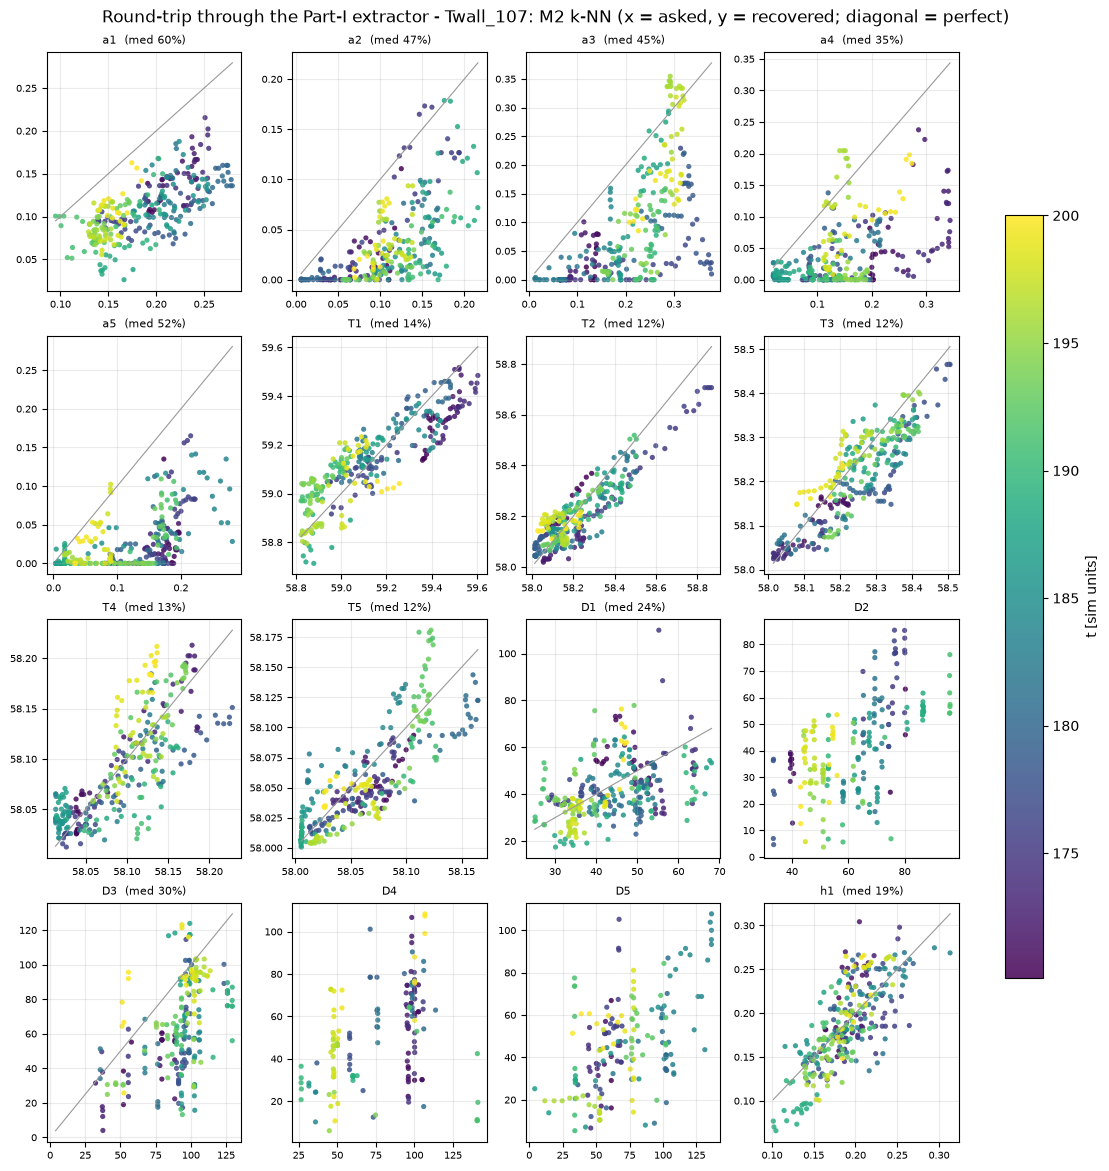

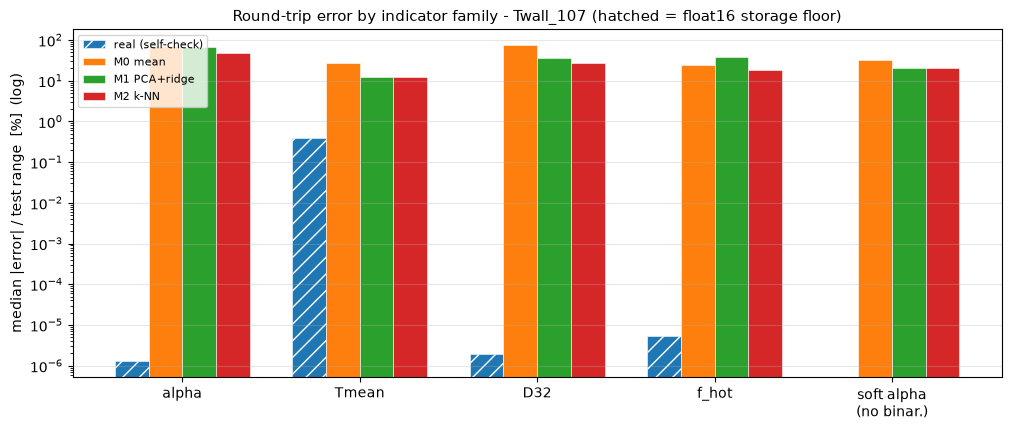


PART II CELL 5 - LEADERBOARD (TEST BLOCK) - Twall_107

--------------------------------------------------------------------------------
TABLE 1 - PIXEL SCORES (context; what the gallery figure shows)
--------------------------------------------------------------------------------
model           PSNR T [dB]  PSNR vapor [dB]  RMSE T  RMSE vapor  dPSNR T vs M0  val MSE
--------------  -----------  ---------------  ------  ----------  -------------  -------
M0 mean                30.4             24.5    1.47        1.07           +0.0     1.56
M1 PCA+ridge           30.5             25.5    1.46       0.953           +0.1     1.55
M2 k-NN [BEST]         29.6             24.8    1.63        1.03           -0.9      1.9
  PSNR = 20 log10(train range / RMSE), median over test frames. Pixel scores reward BLUR (the mean of plausible frames); the round-trip below is the honest judge.

--------------------------------------------------------------------------------
TABLE 2 - ROUND-TRIP THROUGH

In [19]:
# ====== PART II CELL 5 / 5 — LEADERBOARD: round-trip, tables & figures ==========
# The judge: feed every model's generated frames back through the Part-I
# extractor (theta_of_frame, identical math) and ask: do the 20 (4*n) indicator
# values we conditioned on come back out? Plus pixel scores for context.
# Clear tables quantify exactly what the figures show.
# Runs from the files alone (cache + predictions) - a kernel restart is fine.
import json, os
import numpy as np
from scipy import ndimage
import matplotlib.pyplot as plt

try: TEST
except NameError: TEST = "Twall_107"
try: DATA_ROOT
except NameError: DATA_ROOT = r"G:\BoilDesc"
try: OUT_DIR
except NameError: OUT_DIR = os.path.join(DATA_ROOT, "out")
W_ = int(globals().get("W_", 80))

_CPATH = os.path.join(OUT_DIR, f"p2_{TEST}_cache.npz")
assert os.path.exists(_CPATH), f"[P2] cache not found ({_CPATH}); run Cell 3 first"
with np.load(_CPATH, allow_pickle=False) as _z:
    CM   = json.loads(str(_z["meta"]))
    FR   = np.asarray(_z["frames"])                 # (N,H,W,2) f16
    THc  = np.asarray(_z["TH"], float)
    t_c  = np.asarray(_z["t"], float)
    LIVE = np.asarray(_z["live"], int)
    ite  = np.asarray(_z["ite"], int)
    rng_ch = np.asarray(_z["rng_ch"], float)
H, W, NTH = CM["H"], CM["W"], CM["NTH"]
nsec, NTE = CM["N_SECTIONS"], len(ite)
tau, edges = float(CM["tau"]), np.asarray(CM["edges"], int)
wall_rows, min_blob = int(CM["WALL_ROWS"]), int(CM["MIN_BLOB_PX"])
NAMES_L = [CM["names"][j] for j in LIVE]
SHORT_L = [CM["short"][n] for n in NAMES_L]

def theta_of_frame(Tf, d, tau, edges, wall_rows, min_blob):
    """Part-I indicator extractor (keep in sync with Cell 1)."""
    edges = np.asarray(edges)
    n = len(edges) - 1
    phi = d > 0
    al = np.array([phi[r0:r1, :].astype(np.float64).mean()
                   for r0, r1 in zip(edges[:-1], edges[1:])])
    Tm = np.array([Tf[r0:r1, :].astype(np.float64).mean()
                   for r0, r1 in zip(edges[:-1], edges[1:])])
    lab, nb = ndimage.label(phi)
    dsec = [[] for _ in range(n)]
    if nb:
        ys, xs = np.nonzero(lab); lv = lab[ys, xs]
        cnt = np.bincount(lv)
        cyb = np.bincount(lv, weights=ys.astype(float)) / np.maximum(cnt, 1)
        for i in range(1, nb + 1):
            if cnt[i] < min_blob: continue
            deq = 2.0 * np.sqrt(cnt[i] / np.pi)
            k = int(np.clip(np.searchsorted(edges, cyb[i], side="right") - 1,
                            0, n - 1))
            dsec[k].append(deq)
    D32 = np.full(n, np.nan)
    for k, ds in enumerate(dsec):
        if ds: D32[k] = sum(v ** 3 for v in ds) / sum(v ** 2 for v in ds)
    th = np.concatenate([al, Tm, D32, np.full(n, np.nan)])
    if tau is not None and np.isfinite(tau):
        hot = Tf[:wall_rows, :] > tau
        th[3 * n] = (ndimage.binary_opening(hot, structure=np.ones((2, 2))).sum()
                     / float(hot.size))
    return th

# ---- load the three models' test predictions -------------------------------------
MP = {}
for m, lab in (("m0", "M0 mean"), ("m1", "M1 PCA+ridge"), ("m2", "M2 k-NN")):
    _p = os.path.join(OUT_DIR, f"p2_{TEST}_{m}_pred.npz")
    assert os.path.exists(_p), f"[P2] {m} predictions missing ({_p}); run Cell 4"
    with np.load(_p, allow_pickle=False) as _z:
        MP[m] = {"label": lab, "pred": np.asarray(_z["pred"]),
                 "cfg": json.loads(str(_z["cfg"])),
                 "val_mse": float(_z["val_mse"])}
MP["real"] = {"label": "real (self-check)", "pred": FR[ite],
              "cfg": {"kind": "the cached float16 frames themselves"},
              "val_mse": 0.0}

# ---- round-trip: extract theta from every generated test frame ------------------
# Rsoft = real continuous vapor level per section (the soft-alpha reference)
FRte = FR[ite]
Rsoft = np.stack([[float(FRte[i, r0:r1, :, 1].astype(np.float32).mean())
                   for r0, r1 in zip(edges[:-1], edges[1:])]
                  for i in range(NTE)])
for m, d_ in MP.items():
    P = d_["pred"]
    THh = np.full((NTE, NTH), np.nan)
    soft = np.full((NTE, nsec), np.nan)
    for i in range(NTE):
        F32 = P[i, :, :, 0].astype(np.float32)
        A32 = P[i, :, :, 1].astype(np.float32)
        THh[i] = theta_of_frame(F32, A32, tau, edges, wall_rows, min_blob)
        for kk, (r0, r1) in enumerate(zip(edges[:-1], edges[1:])):
            soft[i, kk] = float(A32[r0:r1, :].mean())
    d_["THh"], d_["soft"] = THh, soft
TH_true = THc[ite]

# ---- per-indicator relative error (range = p95-p05 of the test block) -----------
al_live = [j for j in LIVE if 0 <= j < nsec]
rng = np.full(NTH, np.nan)
for j in LIVE:
    v = TH_true[:, j]
    rng[j] = max(float(np.percentile(v, 95) - np.percentile(v, 5)), 1e-9)
rng_soft = np.full(nsec, np.nan)
for j in al_live:
    v = Rsoft[:, j]
    rng_soft[j] = max(float(np.percentile(v, 95) - np.percentile(v, 5)), 1e-9)
FAMS = [("alpha", 0, nsec), ("Tmean", nsec, 2 * nsec),
        ("D32", 2 * nsec, 3 * nsec), ("fhot", 3 * nsec, NTH)]

def fam_rel(d_):
    """median |err|/range per family (%) + soft-alpha (%)."""
    out = {}
    for fam, j0, j1 in FAMS:
        vals = []
        for j in [j for j in LIVE if j0 <= j < j1]:
            e = np.abs(d_["THh"][:, j] - TH_true[:, j]) / rng[j]
            vals += [x for x in e if np.isfinite(x)]
        out[fam] = (100 * float(np.median(vals)) if vals else np.nan)
    sv = []
    for j in al_live:
        e = np.abs(d_["soft"][:, j] - Rsoft[:, j]) / rng_soft[j]
        sv += [x for x in e if np.isfinite(x)]
    out["soft-a"] = 100 * float(np.median(sv)) if sv else np.nan
    fams = [out[f] for f, _a, _b in FAMS if np.isfinite(out[f])]
    out["mean"] = float(np.mean(fams)) if fams else np.nan
    return out

RT = {m: fam_rel(d_) for m, d_ in MP.items()}
BEST = min(("m0", "m1", "m2"), key=lambda m: RT[m]["mean"])

# ---- pixel scores -----------------------------------------------------------------
def pixel(d_):
    P = d_["pred"].astype(np.float32)
    R = FR[ite].astype(np.float32)
    ps, rm = {}, {}
    for c, nm in ((0, "T"), (1, "a")):
        e = ((P[:, :, :, c] - R[:, :, :, c]) ** 2).reshape(NTE, -1).mean(1)
        rm[nm] = float(np.sqrt(np.median(e)))
        ps[nm] = (float(20 * np.log10(rng_ch[c] / np.sqrt(np.median(e))))
                  if rng_ch[c] > 1e-9 and np.median(e) > 0 else np.nan)
    return ps, rm

PX = {m: pixel(d_) for m, d_ in MP.items() if m != "real"}

# ---- FIG 1: gallery (real vs the three models) for the median round-trip frame ----
_per = np.full(NTE, np.nan)
for i in range(NTE):
    vals = [abs(MP[BEST]["THh"][i, j] - TH_true[i, j]) / rng[j]
            for j in LIVE if np.isfinite(MP[BEST]["THh"][i, j])]
    _per[i] = float(np.median(vals)) if vals else np.nan
_okp = np.isfinite(_per)
_gi = (int(np.nanargmin(np.abs(_per - np.nanmedian(_per[_okp])))) if _okp.any()
       else 0)
order = ["real", "m0", "m1", "m2"]
fig, axs = plt.subplots(len(order), 2, figsize=(10.0, 2.6 * len(order)),
                        constrained_layout=True)
for r, m in enumerate(order):
    P = MP[m]["pred"][_gi].astype(np.float32)
    for c, (ch, nm, cm) in enumerate(((0, "T", "magma"), (1, "vapor", "viridis"))):
        ax = axs[r, c]
        ref = FR[ite][_gi, :, :, ch].astype(np.float32)
        im = ax.imshow(P[:, :, ch].T, origin="lower", cmap=cm,
                       vmin=float(ref.min()), vmax=float(ref.max()),
                       extent=[CM["x_min"], CM["x_max"], CM["y_min"], CM["y_max"]],
                       aspect="auto")
        if r == 0:
            ax.set_title(f"{nm} (common scale = real frame)", fontsize=9)
        ax.set_ylabel(("real" if m == "real" else MP[m]["label"])
                      + (" [BEST]" if m == BEST else "") + "\ny", fontsize=8)
        if r == len(order) - 1:
            ax.set_xlabel("x", fontsize=8)
        fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle(f"Gallery - {TEST}, test frame {_gi} (t = {t_c[ite[_gi]]:.3g}): "
             "what each model makes of the same theta", fontsize=12)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_gallery.png"), dpi=150)
plt.show()

# ---- FIG 2: round-trip scatter (true theta in, recovered theta out) ----------------
nshow = min(16, len(LIVE))
nc = 4
nr = int(np.ceil(nshow / nc))
fig, axs = plt.subplots(nr, nc, figsize=(11.0, 2.9 * nr), squeeze=False,
                        constrained_layout=True)
for q in range(nshow):
    ax = axs[q // nc][q % nc]
    j = LIVE[q]
    x, y = TH_true[:, j], MP[BEST]["THh"][:, j]
    ax.plot([x.min(), x.max()], [x.min(), x.max()], color="0.6", lw=0.8)
    sc = ax.scatter(x, y, c=t_c[ite], cmap="viridis", s=14, alpha=0.85,
                    edgecolors="none")
    e = np.abs(y - x) / rng[j]
    e = e[np.isfinite(e)]
    ax.set_title(f"{SHORT_L[q]}  (med {100 * np.median(e):.0f}%)" if len(e)
                 else SHORT_L[q], fontsize=8)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=7)
for q in range(nshow, nr * nc):
    axs[q // nc][q % nc].axis("off")
fig.colorbar(sc, ax=np.asarray(axs).ravel(), shrink=0.7, label="t [sim units]")
fig.suptitle(f"Round-trip through the Part-I extractor - {TEST}: "
             f"{MP[BEST]['label']} (x = asked, y = recovered; diagonal = perfect)",
             fontsize=12)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_rt_scatter.png"), dpi=150)
plt.show()

# ---- FIG 3: family bars --------------------------------------------------------------
_figs = [f for f, _a, _b in FAMS] + ["soft-a"]
_lab = {"alpha": "alpha", "Tmean": "Tmean", "D32": "D32", "fhot": "f_hot",
        "soft-a": "soft alpha\n(no binar.)"}
fig, ax = plt.subplots(figsize=(10.0, 4.2), constrained_layout=True)
wid, xb = 0.19, np.arange(len(_figs))
for _i, m in enumerate(("real", "m0", "m1", "m2")):
    vals = [RT[m][f] if np.isfinite(RT[m][f]) else 0.0 for f in _figs]
    bars = ax.bar(xb + (_i - 1.5) * wid, vals, wid,
                  label=MP[m]["label"], hatch="//" if m == "real" else "",
                  edgecolor="white", lw=0.4)
ax.set_yscale("log")
ax.set_xticks(xb, [_lab[f] for f in _figs])
ax.set_ylabel("median |error| / test range  [%]  (log)")
ax.grid(alpha=0.3, axis="y")
ax.legend(fontsize=8)
ax.set_title(f"Round-trip error by indicator family - {TEST} "
             "(hatched = float16 storage floor)", fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_rt_bars.png"), dpi=150)
plt.show()

# ---- tables ----------------------------------------------------------------------------
def _g(v, fmt="%s"):
    return "n/a" if v is None or not np.isfinite(v) else fmt % v

def _render(title, cols, rows, note=None):
    print()
    print("-" * W_)
    print(title)
    print("-" * W_)
    if not rows:
        print("  (nothing to show)")
    else:
        _rs = [[str(c) for c in r] for r in rows]
        _w = [max([len(cols[_c])] + [len(_r[_c]) for _r in _rs])
              for _c in range(len(cols))]
        print("  ".join(cols[_c].ljust(_w[_c])
                        for _c in range(len(cols))).rstrip())
        print("  ".join("-" * _w[_c] for _c in range(len(cols))).rstrip())
        for _r in _rs:
            print("  ".join(_r[_c].ljust(_w[_c]) if _c == 0 else _r[_c].rjust(_w[_c])
                            for _c in range(len(cols))).rstrip())
    if note:
        print("  " + note)

print()
print("=" * W_)
print(f"PART II CELL 5 - LEADERBOARD (TEST BLOCK) - {TEST}")
print("=" * W_)
_rows1 = []
_ps0 = PX["m0"][0]
for m in ("m0", "m1", "m2"):
    ps, rm = PX[m]
    _rows1.append([MP[m]["label"] + (" [BEST]" if m == BEST else ""),
                   _g(ps["T"], "%5.1f"), _g(ps["a"], "%5.1f"),
                   _g(rm["T"], "%.3g"), _g(rm["a"], "%.3g"),
                   _g(ps["T"] - _ps0["T"], "%+5.1f"),
                   _g(MP[m]["val_mse"], "%.3g")])
_render("TABLE 1 - PIXEL SCORES (context; what the gallery figure shows)",
        ["model", "PSNR T [dB]", "PSNR vapor [dB]", "RMSE T", "RMSE vapor",
         "dPSNR T vs M0", "val MSE"], _rows1,
        "PSNR = 20 log10(train range / RMSE), median over test frames. "
        "Pixel scores reward BLUR (the mean of plausible frames); the "
        "round-trip below is the honest judge.")

_rows2 = []
for m in ("real", "m0", "m1", "m2"):
    r = RT[m]
    _rows2.append([MP[m]["label"] + (" [BEST]" if m == BEST else "")]
                  + [_g(r[f], "%5.1f") for f in _figs]
                  + [_g(r["mean"], "%5.1f"),
                     ("-" if m == "real" else
                      _g(r["mean"] - RT["m0"]["mean"], "%+5.1f"))])
_render("TABLE 2 - ROUND-TRIP THROUGH THE PART-I EXTRACTOR (the success test)",
        ["model", "alpha %", "Tmean %", "D32 %", "f_hot %", "soft alpha %",
         "mean %", "d vs M0"], _rows2,
        "median |recovered - asked| / test range, per indicator family. "
        "'real (self-check)' = the cached float16 frames themselves: the "
        "storage floor every model is measured against. soft alpha = "
        "continuous vapor LEVEL per section (predicted vs real mean dfun, no "
        "binarization) - a low soft error with a high alpha error means the "
        "model BLURS vapor: right level, smeared bubble edges.")

_rows3 = []
for q, j in enumerate(LIVE):
    e = np.abs(MP[BEST]["THh"][:, j] - TH_true[:, j]) / rng[j]
    e = e[np.isfinite(e)]
    a = np.abs(MP[BEST]["THh"][:, j] - TH_true[:, j])
    a = a[np.isfinite(a)]
    _rows3.append([SHORT_L[q],
                   _g(np.median(a), "%.3g") if len(a) else "n/a",
                   _g(100 * np.median(e), "%.1f") if len(e) else "n/a",
                   _g(100 * np.percentile(e, 90), "%.1f") if len(e) else "n/a"])
_render(f"TABLE 3 - PER-INDICATOR DETAIL, {MP[BEST]['label']} "
        "(what the scatter figure shows)", ["indicator", "median |err|",
        "median rel %", "p90 rel %"], _rows3,
        "rel = |err| / (p95-p05 of the test block). Small medians with large "
        "p90 = occasional big misses (usually D32 frames with merged bubbles).")

_fns = ([f"p2_{TEST}_theta.npz", f"p2_{TEST}_cache.npz",
         f"p2_{TEST}_m0_pred.npz", f"p2_{TEST}_m1_pred.npz",
         f"p2_{TEST}_m2_pred.npz", f"p2_{TEST}_segmap.png",
         f"p2_{TEST}_theta.png", f"p2_{TEST}_split.png",
         f"p2_{TEST}_eigen.png", f"p2_{TEST}_select.png",
         f"p2_{TEST}_gallery.png", f"p2_{TEST}_rt_scatter.png",
         f"p2_{TEST}_rt_bars.png"])
_rows4 = [[fn, f"{os.path.getsize(os.path.join(OUT_DIR, fn)) / 1e3:.0f} KB",
           "present" if os.path.exists(os.path.join(OUT_DIR, fn)) else "MISSING"]
          for fn in _fns if os.path.exists(os.path.join(OUT_DIR, fn))]
_render("TABLE 4 - ARTIFACTS ON DISK", ["file", "size", "status"], _rows4)

# ---- takeaway ---------------------------------------------------------------------------
print()
print("=" * W_)
print("TAKEAWAY")
print("=" * W_)
print(f"  conditioning   : {len(LIVE)} live indicators of {NTH} "
      f"(derived from the {nsec}-section segmentation; masked cols: "
      + (" ".join(CM["short"][CM["names"][j]] for j in range(NTH)
                  if j not in set(LIVE.tolist())) or "none") + ")")
print(f"  test block     : {NTE} late-regime frames "
      f"(t {t_c[ite[0]]:.3g} -> {t_c[ite[-1]]:.3g}), never used for fitting")
print(f"  storage floor  : real self-check mean {RT['real']['mean']:.1f}% "
      f"(float16 cache; Tmean {RT['real']['Tmean']:.1f}%, "
      f"f_hot {RT['real']['fhot']:.1f}%)")
for m in ("m0", "m1", "m2"):
    r = RT[m]
    print(f"  {MP[m]['label']:<15}: mean {r['mean']:.1f}%  "
          f"(alpha {r['alpha']:.1f} | Tmean {r['Tmean']:.1f} | "
          f"D32 {r['D32']:.1f} | f_hot {r['fhot']:.1f}; "
          f"soft alpha {r['soft-a']:.1f}%)")
_g_ = RT[BEST]["soft-a"] - RT[BEST]["alpha"]
if _g_ > 2 * max(RT[BEST]["alpha"], 1.0):
    print(f"  blur diagnosis : soft-alpha {RT[BEST]['soft-a']:.1f}% vs hard "
          f"{RT[BEST]['alpha']:.1f}% -> the best model gets vapor LEVELS right "
          "but smears bubble EDGES (pixel averaging); sharp texture needs M3 / "
          "a generative model")
_wfam = [f for f, _a, _b in FAMS if np.isfinite(RT[BEST][f])]
if _wfam:
    _wf = min(_wfam, key=lambda f: RT[BEST][f])
    print(f"  hardest family : {_wf} ({RT[BEST][_wf]:.1f}%) - "
          "the least predictable from theta alone")
print(f"  verdict        : {MP[BEST]['label']} reproduces the asked indicators "
      f"to {RT[BEST]['mean']:.1f}% median error (test range as the yardstick); "
      "the ladder's job was to measure HOW MUCH the indicators determine - "
      "M3 must beat this to justify a neural net")
print()
print("[P2] Cell 5 complete. Next rungs (Phase 2): M3 small conditional net "
      "(theta -> 18x12 grid -> x16 upsample), then a generative cVAE for "
      "bubble texture; more Twall files make wallTemp a conditioning input.")


[P2] cache loaded: 2001 frames 512x512, 1401/300/300 split, 16 live indicators, tau 68.9
[P2] Block A: k re-scoring by round-trip on val (7 + 2 rows)
[P2]   ... k=1: 100/300 frames
[P2]   ... k=1: 200/300 frames
[P2]   ... k=1: 300/300 frames
[P2]   ... k=2: 100/300 frames
[P2]   ... k=2: 200/300 frames
[P2]   ... k=2: 300/300 frames
[P2]   ... k=3: 100/300 frames
[P2]   ... k=3: 200/300 frames
[P2]   ... k=3: 300/300 frames
[P2]   ... k=5: 100/300 frames
[P2]   ... k=5: 200/300 frames
[P2]   ... k=5: 300/300 frames
[P2]   ... k=9: 100/300 frames
[P2]   ... k=9: 200/300 frames
[P2]   ... k=9: 300/300 frames
[P2]   ... k=15: 100/300 frames
[P2]   ... k=15: 200/300 frames
[P2]   ... k=15: 300/300 frames
[P2]   ... k=25: 100/300 frames
[P2]   ... k=25: 200/300 frames
[P2]   ... k=25: 300/300 frames
[P2]   ... w=15: 100/300 frames
[P2]   ... w=15: 200/300 frames
[P2]   ... w=15: 300/300 frames
[P2]   ... real self-check: 100/300 frames
[P2]   ... real self-check: 200/300 frames
[P2]   ... 

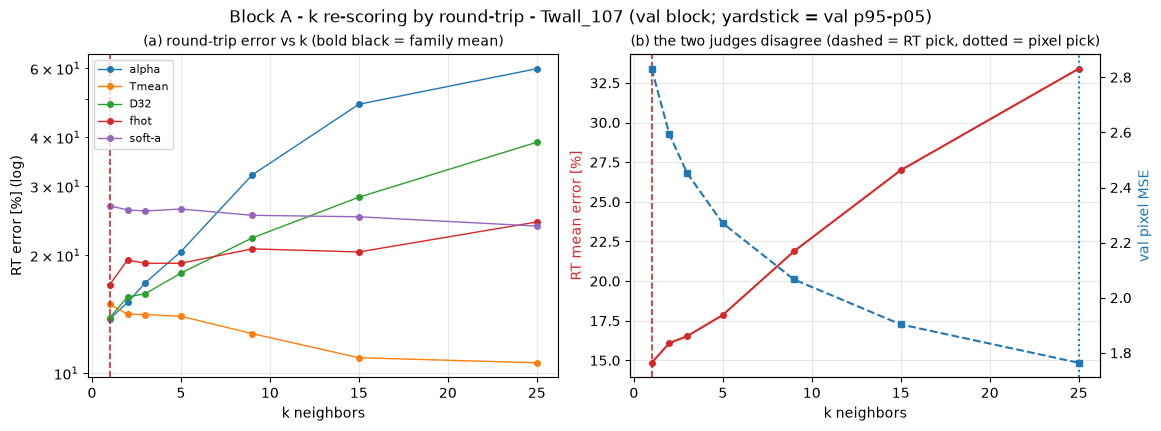

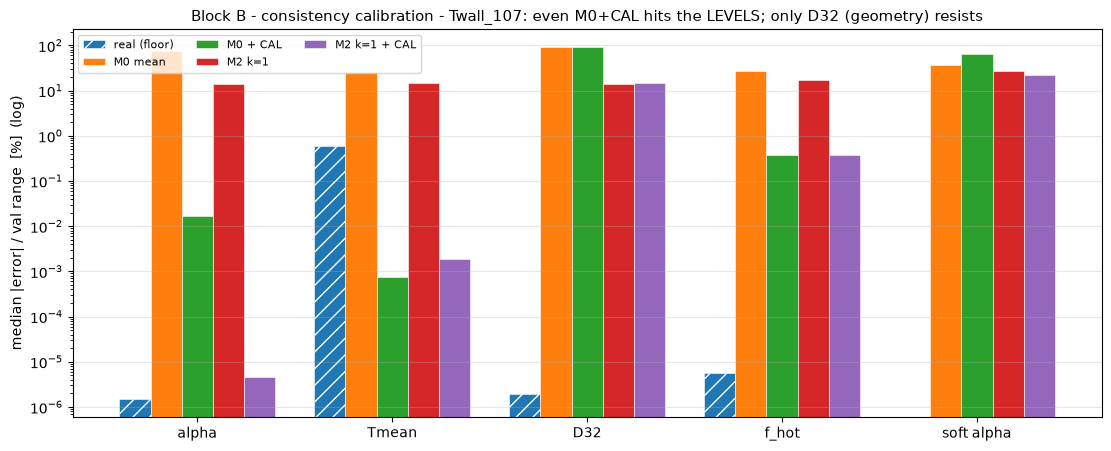

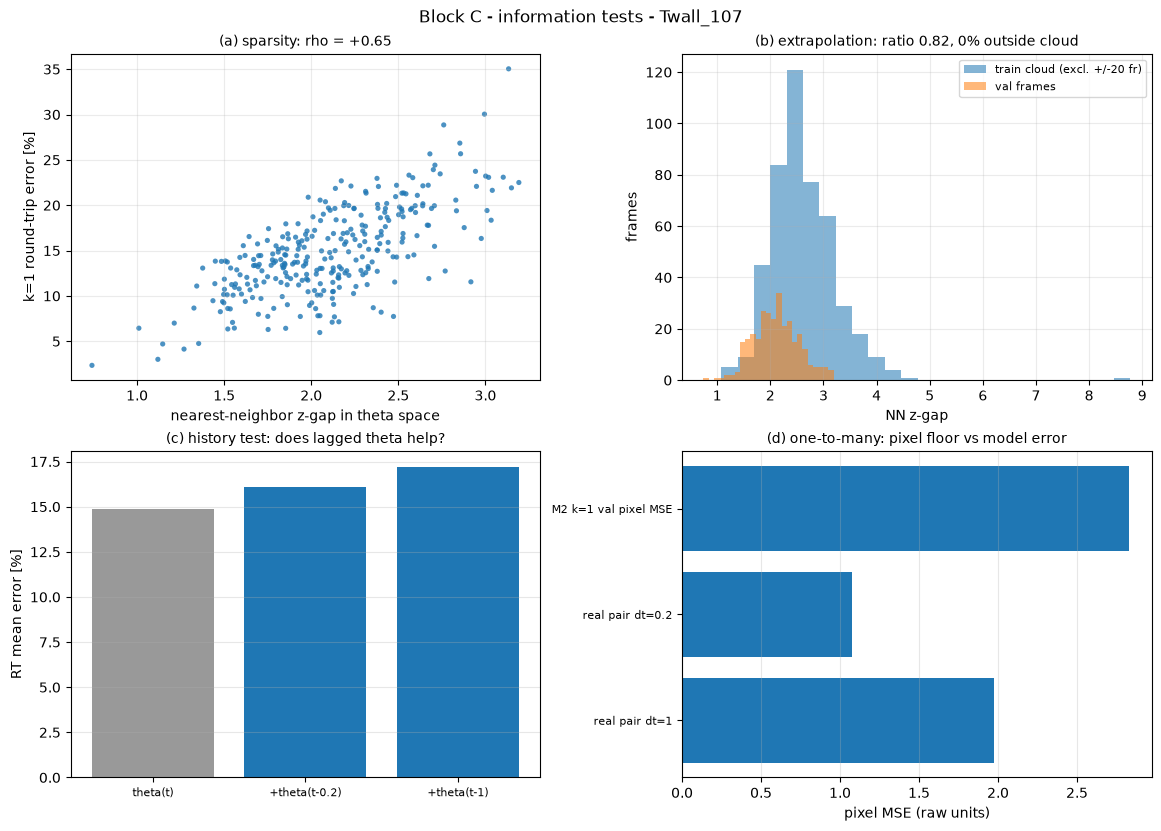

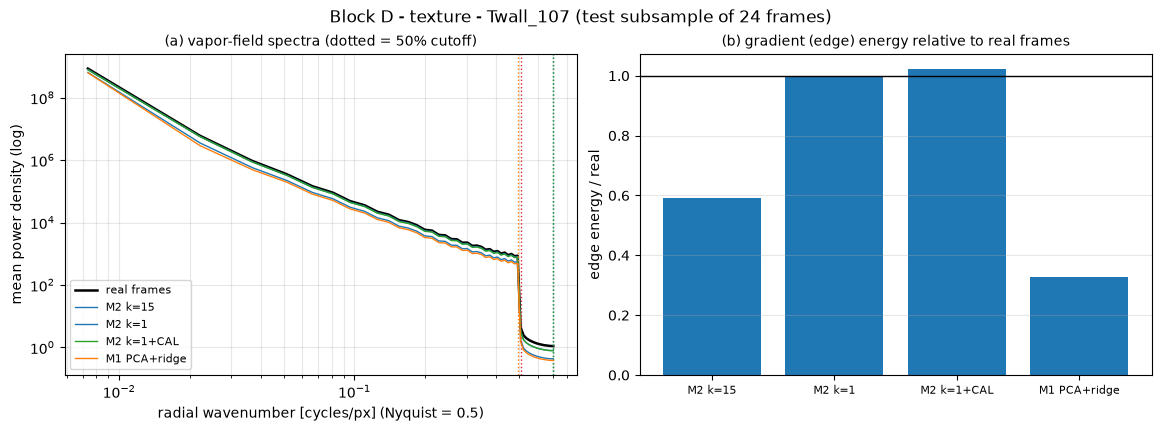


PART II CELL 6 - K RE-SCORING & NEXT-MODEL DIAGNOSTICS - Twall_107

--------------------------------------------------------------------------------
TABLE 1 - K RE-SCORING BY ROUND-TRIP (val block, the honest judge)
--------------------------------------------------------------------------------
model              what                             alpha %  Tmean %  D32 %  f_hot %  soft %  mean %  pixel MSE  note
-----------------  -------------------------------  -------  -------  -----  -------  ------  ------  ---------  ------------------------
real (self-check)     the cached frames themselves      0.0      0.6    0.0      0.0     0.0     0.2          0             storage floor
M0 mean frame                  train-average frame     76.8     25.7   90.7     27.5    36.0    55.2       1.56                 the floor
M2 k=1              mean of 1 nearest-theta frames     13.8     15.0   13.8     16.8    26.7    14.8       2.83  <-- chosen by ROUND-TRIP
M2 k=2              mean of 2 ne

In [23]:
# ====== PART II CELL 6 / 6 — K RE-SCORING & NEXT-MODEL DIAGNOSTICS ==============
# Cell 4 chose k=15 by PIXEL MSE - the wrong judge (pixel scores reward blur).
# This cell re-picks k by the ROUND-TRIP on val, then runs the tests that decide
# how M3 (the small conditional net) must be built:
#   BLOCK A  k re-scoring by round-trip + the cost of the pixel-chosen k
#   BLOCK B  consistency calibration CAL: re-level the OUTPUT to the ASKED theta
#            (a deterministic output layer M3 can adopt as a differentiable head)
#   BLOCK C  information tests: theta-sparsity / history / one-to-many
#   BLOCK D  texture: radial spectra + edge energy (the cVAE job description)
# Runs from out/p2_<TEST>_cache.npz alone (kernel restart is fine);
# p2_<TEST>_m{0,1,2}_pred.npz are optional (used only if newer than the cache).
import json, os, time
import numpy as np
from scipy import ndimage
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

try: TEST
except NameError: TEST = "Twall_107"
try: DATA_ROOT
except NameError: DATA_ROOT = r"G:\BoilDesc"
try: OUT_DIR
except NameError: OUT_DIR = os.path.join(DATA_ROOT, "out")
W_ = int(globals().get("W_", 80))
for _k, _v in dict(KNN_GRID6=(1, 2, 3, 5, 9, 15, 25),  # k values re-scored by RT
                   LAGS_FRAMES=(2, 10),    # history test: append theta(t - lag)
                   TWIN_EPS=(0.05, 0.10),  # one-to-many test: twin tolerance
                   TWIN_DT=100,            # twins must be > this many frames apart
                   N_SPEC=24).items():     # frames subsampled for the spectra
    if _k not in dir():
        globals()[_k] = _v
        print(f"[P2] {_k} not defined -> default {_v}")

def _f(v):
    try: return float(v)
    except (TypeError, ValueError): return float("nan")

def _g(v, fmt="%s"):
    v = _f(v)
    return "n/a" if not np.isfinite(v) else fmt % v

def _render(title, cols, rows, note=None):
    print()
    print("-" * W_)
    print(title)
    print("-" * W_)
    if not rows:
        print("  (nothing to show)")
    else:
        _rs = [[str(c) for c in r] for r in rows]
        _w = [max([len(cols[_c])] + [len(_r[_c]) for _r in _rs])
              for _c in range(len(cols))]
        print("  ".join(cols[_c].ljust(_w[_c])
                        for _c in range(len(cols))).rstrip())
        print("  ".join("-" * _w[_c] for _c in range(len(cols))).rstrip())
        for _r in _rs:
            print("  ".join(_r[_c].ljust(_w[_c]) if _c == 0 else _r[_c].rjust(_w[_c])
                            for _c in range(len(cols))).rstrip())
    if note:
        print("  " + note)

# ---- load the Cell-3 cache (the only mandatory input) ----------------------------
_CPATH = os.path.join(OUT_DIR, f"p2_{TEST}_cache.npz")
assert os.path.exists(_CPATH), \
    f"[P2] cache not found ({_CPATH}); run Cells 1-3 first"
with np.load(_CPATH, allow_pickle=False) as _z:
    CM   = json.loads(str(_z["meta"]))
    FR   = np.asarray(_z["frames"])                 # (N,H,W,2) f16 [T, dfun]
    THc  = np.asarray(_z["TH"], float)              # (N, NTH)
    t_c  = np.asarray(_z["t"], float)
    LIVE = np.asarray(_z["live"], int)
    itr, iva, ite = (np.asarray(_z[k], int) for k in ("itr", "iva", "ite"))
    z_mu, z_sd = np.asarray(_z["z_mu"], float), np.asarray(_z["z_sd"], float)
    mu_frame  = np.asarray(_z["mu_frame"], np.float32)
H, W = CM["H"], CM["W"]
nsec, NTH = CM["N_SECTIONS"], CM["NTH"]
tau, edges = float(CM["tau"]), np.asarray(CM["edges"], int)
wall_rows, min_blob = int(CM["WALL_ROWS"]), int(CM["MIN_BLOB_PX"])
ntr, nva, nte = len(itr), len(iva), len(ite)
dt_s = float(np.median(np.diff(t_c))) if len(t_c) > 1 else 1.0
LIVE_set = set(int(j) for j in LIVE)
FAMS = [("alpha", 0, nsec), ("Tmean", nsec, 2 * nsec),
        ("D32", 2 * nsec, 3 * nsec), ("fhot", 3 * nsec, NTH)]
al_live = [j for j in LIVE if 0 <= j < nsec]
print(f"[P2] cache loaded: {FR.shape[0]} frames {H}x{W}, {ntr}/{nva}/{nte} split, "
      f"{len(LIVE)} live indicators, tau {_g(tau, '%.3g')}")

def theta_of_frame(Tf, d, tau, edges, wall_rows, min_blob):
    """Part-I indicator extractor (keep in sync with Cell 1 / Cell 5)."""
    edges = np.asarray(edges)
    n = len(edges) - 1
    phi = d > 0
    al = np.array([phi[r0:r1, :].astype(np.float64).mean()
                   for r0, r1 in zip(edges[:-1], edges[1:])])
    Tm = np.array([Tf[r0:r1, :].astype(np.float64).mean()
                   for r0, r1 in zip(edges[:-1], edges[1:])])
    lab, nb = ndimage.label(phi)
    dsec = [[] for _ in range(n)]
    if nb:
        ys, xs = np.nonzero(lab); lv = lab[ys, xs]
        cnt = np.bincount(lv)
        cyb = np.bincount(lv, weights=ys.astype(float)) / np.maximum(cnt, 1)
        for i in range(1, nb + 1):
            if cnt[i] < min_blob: continue
            deq = 2.0 * np.sqrt(cnt[i] / np.pi)
            k = int(np.clip(np.searchsorted(edges, cyb[i], side="right") - 1,
                            0, n - 1))
            dsec[k].append(deq)
    D32 = np.full(n, np.nan)
    for k, ds in enumerate(dsec):
        if ds: D32[k] = sum(v ** 3 for v in ds) / sum(v ** 2 for v in ds)
    th = np.concatenate([al, Tm, D32, np.full(n, np.nan)])
    if tau is not None and np.isfinite(tau):
        hot = Tf[:wall_rows, :] > tau
        th[3 * n] = (ndimage.binary_opening(hot, structure=np.ones((2, 2))).sum()
                     / float(hot.size))
    return th

def _rho(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    if m.sum() >= 5 and np.std(x[m]) > 1e-12 and np.std(y[m]) > 1e-12:
        return float(spearmanr(x[m], y[m])[0])
    return float("nan")

# ---- round-trip scorer (Cell-5 conventions: median |err| / block p95-p05) --------
def _rng_block(idx):
    rng = np.full(NTH, np.nan)
    for j in LIVE:
        rng[j] = max(float(np.percentile(THc[idx, j], 95)
                            - np.percentile(THc[idx, j], 5)), 1e-9)
    return rng

_SOFT_CACHE = {}
def _soft_real(idx):
    key = idx.tobytes()
    if key not in _SOFT_CACHE:
        _SOFT_CACHE[key] = {j: np.asarray(
            [float(FR[g, edges[j]:edges[j + 1], :, 1].astype(np.float32).mean())
             for g in idx]) for j in al_live}
    return _SOFT_CACHE[key]

def score_block(fn, idx, tag):
    """Round-trip + pixel scores of fn(i)->(H,W,2) over block idx."""
    n = len(idx)
    THt = THc[idx]
    rng = _rng_block(idx)
    soft_ref = _soft_real(idx)
    rng_soft = {j: max(float(np.percentile(soft_ref[j], 95)
                             - np.percentile(soft_ref[j], 5)), 1e-9)
                for j in al_live}
    E  = {j: np.full(n, np.nan) for j in LIVE}
    ES = {j: np.full(n, np.nan) for j in al_live}
    PX = np.full(n, np.nan)
    for i in range(n):
        P = np.asarray(fn(i), np.float32)
        th = theta_of_frame(P[:, :, 0], P[:, :, 1], tau, edges,
                            wall_rows, min_blob)
        for j in LIVE:
            E[j][i] = abs(th[j] - THt[i, j])
        for j in al_live:
            ES[j][i] = abs(float(P[edges[j]:edges[j + 1], :, 1].mean())
                           - soft_ref[j][i])
        PX[i] = float(np.mean((P - FR[idx[i]].astype(np.float32)) ** 2))
        if (i + 1) % 100 == 0:
            print(f"[P2]   ... {tag}: {i + 1}/{n} frames")
    fam = {}
    for name, j0, j1 in FAMS:
        vals = []
        for j in LIVE:
            if not (j0 <= j < j1) or not np.isfinite(rng[j]):
                continue
            e = E[j] / rng[j]
            vals += [x for x in e if np.isfinite(x)]
        fam[name] = 100 * float(np.median(vals)) if vals else float("nan")
    sv = []
    for j in al_live:
        e = ES[j] / rng_soft[j]
        sv += [x for x in e if np.isfinite(x)]
    fam["soft-a"] = 100 * float(np.median(sv)) if sv else float("nan")
    wf = [fam[f] for f, _a, _b in FAMS if np.isfinite(fam[f])]
    fam["mean"] = float(np.mean(wf)) if wf else float("nan")
    per = np.full(n, np.nan)
    for i in range(n):
        v = [E[j][i] / rng[j] for j in LIVE
             if np.isfinite(rng[j]) and np.isfinite(E[j][i])]
        per[i] = 100 * float(np.median(v)) if v else np.nan
    return {"fam": fam, "per": per,
            "px": float(np.mean(PX)) if np.isfinite(PX).any() else float("nan")}

# ---- k-NN machinery (Cell-4 conventions: z-scored live theta, euclidean) ----------
_raw = THc[:, LIVE]
Z = np.where(np.isfinite(_raw), (_raw - z_mu) / z_sd, 0.0)
Dva = ((Z[iva][:, None, :] - Z[itr][None, :, :]) ** 2).sum(-1)
Dte = ((Z[ite][:, None, :] - Z[itr][None, :, :]) ** 2).sum(-1)
ova = np.argsort(Dva, axis=1)          # neighbor order, reused for every k
ote = np.argsort(Dte, axis=1)

def knn_val(i, k):
    return FR[itr[ova[i, :k]]].astype(np.float32).mean(0)

def knn_val_w(i, k):
    d = np.sqrt(Dva[i, ova[i, :k]])
    w = 1.0 / np.maximum(d, 1e-6)
    return (FR[itr[ova[i, :k]]].astype(np.float32)
            * w[:, None, None, None]).sum(0) / w.sum()

def knn_test(i, k):
    return FR[itr[ote[i, :k]]].astype(np.float32).mean(0)

# ================= BLOCK A: k re-scoring by ROUND-TRIP (val block) ================
t0 = time.time()
k_grid = sorted({int(k) for k in KNN_GRID6 if 1 <= int(k) <= ntr})
print(f"[P2] Block A: k re-scoring by round-trip on val ({len(k_grid)} + 2 rows)")
SW = {}
for k in k_grid:
    SW[("k", k)] = score_block(lambda i, k=k: knn_val(i, k), iva, f"k={k}")
KW = max(3, min(15, ntr))
SW[("w", KW)] = score_block(lambda i: knn_val_w(i, KW), iva, f"w={KW}")
SW[("real", 0)] = score_block(lambda i: FR[iva[i]], iva, "real self-check")
SW[("m0", 0)] = score_block(lambda i: mu_frame, iva, "M0")
_finite = [(k, SW[("k", k)]["fam"]["mean"]) for k in k_grid
           if np.isfinite(SW[("k", k)]["fam"]["mean"])]
k_rt = min(_finite, key=lambda kv: kv[1])[0] if _finite else k_grid[0]
k_pix = min(k_grid, key=lambda k: SW[("k", k)]["px"])
print(f"[P2]   k by round-trip = {k_rt}  (pixel judge would pick {k_pix}) "
      f"[{time.time() - t0:.0f}s]")

# ================= BLOCK B: consistency calibration (the M3 head) =================
print("[P2] Block B: consistency calibration CAL (re-level output to asked theta)")

def _sec_shift_field(dsec, box=5):
    """Piecewise-constant per-section shift, box-smoothed over `box` rows so
    the field stays continuous across section boundaries (no seam artifacts
    for the connected-component / D32 statistics downstream)."""
    rows = np.arange(H)
    s = np.clip(np.searchsorted(edges, rows, side="right") - 1, 0, nsec - 1)
    sh = np.asarray(dsec, float)[s]
    if box > 1:
        _pad = box // 2
        sh = np.convolve(np.pad(sh, _pad, mode="edge"),
                         np.ones(box) / box, mode="valid")
    return sh

def _alpha_shift(sec, want):
    """Vertical shift c so that mean(sec + c > 0) hits `want` EXACTLY when the
    value distribution allows it, or the closest achievable count when ties /
    gaps (e.g. distance-transform rings) make the exact fraction unreachable.
    Order statistics, no interpolation -> no random walk inside gaps."""
    v = np.sort(np.asarray(sec, np.float64).ravel())
    Ns = v.size
    m = int(round(want * Ns))
    if m <= 0:
        return -float(v[-1]) - 1.0                # no vapor at all
    if m >= Ns:
        return -float(v[0]) + 1.0                 # everything vapor
    hi_v, lo_v = float(v[Ns - m]), float(v[Ns - m - 1])
    if hi_v > lo_v:
        return -0.5 * (hi_v + lo_v)               # exact: count(A > -c) == m
    u = hi_v                                       # a tie block spans the target
    cnt_gt = int((v > u).sum())
    cnt_ge = int((v >= u).sum())
    if m - cnt_gt <= cnt_ge - m:
        return -u                                 # land just below m
    return -float(np.nextafter(u, -np.inf))       # land just above m

def calibrate(P, th_ask):
    """Re-level ONE prediction (H,W,2 f32) onto the ASKED theta (the model input).
    Tmean  : iterated per-section shift of T until each section MEAN is exact
    f_hot  : bisection shift of the wall band until the EXTRACTOR's opened hot
             fraction is as close as achievable (same 2x2 opening)
    alpha  : order-statistics per-section shift of dfun until each section's
             vapor FRACTION (dfun > 0) is exact (or closest achievable)
    Every objective is measured with the extractor's own arithmetic, and only
    the asked indicators are used (the model's own input) - a deterministic
    output layer, not leakage; M3 can implement it as a differentiable head."""
    P = np.array(P, dtype=np.float32, copy=True)
    T, A = P[:, :, 0], P[:, :, 1]
    n = nsec
    hj = 3 * n                                   # fhot col (wall-band section)
    wantT = {j: float(th_ask[n + j]) for j in range(n)
             if (n + j) in LIVE_set and np.isfinite(th_ask[n + j])}
    wantA = {j: float(np.clip(th_ask[j], 0.0, 1.0)) for j in range(n)
             if j in LIVE_set and np.isfinite(th_ask[j])}
    # --- Tmean <-> f_hot, alternating (the band shift perturbs section-1 mean)
    dT = np.zeros(n)
    for _ in range(5):
        T += _sec_shift_field(dT)[:, None]
        dT = np.zeros(n)
        if hj in LIVE_set and np.isfinite(th_ask[hj]) and wall_rows < H:
            f_t = float(np.clip(th_ask[hj], 0.0, 1.0))
            wb = T[:wall_rows, :]

            def _f(d):
                hot = wb + d > tau
                return (ndimage.binary_opening(
                    hot, structure=np.ones((2, 2))).sum() / float(hot.size))

            lo, hi = tau - float(wb.max()) - 1.0, tau - float(wb.min()) + 1.0
            for _ in range(40):                   # f increases with delta
                mid = 0.5 * (lo + hi)
                if _f(mid) > f_t: hi = mid
                else: lo = mid
            fl, fh = _f(lo), _f(hi)               # cliff: pick the closer side
            delta = lo if abs(fl - f_t) <= abs(fh - f_t) else hi
            T[:wall_rows, :] += delta
            _tp = min(wall_rows, H - wall_rows)
            T[wall_rows:wall_rows + _tp, :] += \
                delta * np.linspace(1.0, 0.0, _tp)[:, None]
        for j, want in wantT.items():
            dT[j] = want - float(T[edges[j]:edges[j + 1], :].mean())
    # --- alpha: order-statistics targeting, iterated to absorb the box-smoothed
    # field's boundary leak
    dA = np.zeros(n)
    for _ in range(3):
        A += _sec_shift_field(dA)[:, None]
        dA = np.zeros(n)
        for j, want in wantA.items():
            dA[j] = _alpha_shift(A[edges[j]:edges[j + 1], :], want)
    return P

KB = {}
KB["m0cal"] = score_block(lambda i: calibrate(mu_frame, THc[iva[i]]),
                          iva, "M0+CAL")
KB["k1cal"] = score_block(
    lambda i: calibrate(FR[itr[ova[i, 0]]].astype(np.float32), THc[iva[i]]),
    iva, "k=1+CAL")
KB["krtcal"] = score_block(
    lambda i: calibrate(knn_val(i, k_rt), THc[iva[i]]), iva, f"k={k_rt}+CAL")
cal_alpha_gain = SW[("k", k_rt)]["fam"]["alpha"] - KB["krtcal"]["fam"]["alpha"]
print(f"[P2]   CAL recovers {cal_alpha_gain:.1f} pts of hard alpha "
      f"({SW[('k', k_rt)]['fam']['alpha']:.1f}% -> "
      f"{KB['krtcal']['fam']['alpha']:.1f}%)  [{time.time() - t0:.0f}s]")

# ================= BLOCK C: information tests =====================================
print("[P2] Block C: information tests (sparsity / history / one-to-many)")
# --- C1: where does the k=1 error live? theta-gap vs time-gap ----------------------
gap_val = np.sqrt(Dva.min(axis=1))                 # NN z-gap per val frame
nn_g = itr[ova[:, 0]]
t_gap = np.abs(t_c[iva] - t_c[nn_g])
_sub = itr[::max(1, ntr // 400)]
_Zs = Z[_sub]
_Dc = ((_Zs[:, None, :] - _Zs[None, :, :]) ** 2).sum(-1)
_Dc[np.abs(_sub[:, None] - _sub[None, :]) <= 20] = np.inf
gap_cloud = np.sqrt(_Dc.min(axis=1))
gap_cloud = gap_cloud[np.isfinite(gap_cloud)]
rho_gap = _rho(SW[("k", 1)]["per"], gap_val)
rho_tgap = _rho(SW[("k", 1)]["per"], t_gap)
extrap_ratio = (float(np.median(gap_val)) / float(np.median(gap_cloud))
                if len(gap_cloud) else float("nan"))
outside_pct = (100.0 * float(np.mean(gap_val > np.percentile(gap_cloud, 90)))
               if len(gap_cloud) else float("nan"))

# --- C2: history test - does theta(t - delta) add information? --------------------
HIST_RES = {}
_lag_ok = [int(l) for l in LAGS_FRAMES
           if int(l) > 0 and int(l) < nva and int(l) < ntr - 2]
for lag in _lag_ok:
    db = itr[itr >= lag]
    if len(db) < max(3, k_rt):
        continue
    pos = np.searchsorted(itr, db)                  # db positions within itr
    HIST_RES[("base", lag)] = score_block(
        lambda i, db=db, pos=pos:
            FR[db[np.argsort(Dva[i, pos])[:k_rt]]].astype(np.float32).mean(0),
        iva, f"hist base lag{lag}")
    Hraw = np.full(_raw.shape, np.nan)
    Hraw[lag:] = THc[:-lag][:, LIVE]
    mu_h = np.zeros(len(LIVE)); sd_h = np.ones(len(LIVE))
    for c in range(len(LIVE)):
        v = Hraw[itr, c]; m = np.isfinite(v)
        if m.any():
            mu_h[c] = float(v[m].mean()); sd_h[c] = max(float(v[m].std()), 1e-12)
    Zh = np.where(np.isfinite(Hraw), (Hraw - mu_h) / sd_h, 0.0)
    Zq = np.column_stack([Z[iva], Zh[iva]])
    Zd = np.column_stack([Z[db], Zh[db]])
    Dh = ((Zq[:, None, :] - Zd[None, :, :]) ** 2).sum(-1)
    oh = np.argsort(Dh, axis=1)
    HIST_RES[("lag", lag)] = score_block(
        lambda i, db=db, oh=oh: FR[db[oh[i, :k_rt]]].astype(np.float32).mean(0),
        iva, f"hist lag{lag}")
_lags_done = [l for l in _lag_ok if ("lag", l) in HIST_RES]

# --- C3: one-to-many test ----------------------------------------------------------
rng_va = _rng_block(iva)
PAIR = {}
for lag in _lag_ok:
    g0, g1 = iva[:-lag], iva[lag:]
    dr = {}
    for name, j0, j1 in FAMS:
        vals = []
        for j in LIVE:
            if not (j0 <= j < j1) or not np.isfinite(rng_va[j]):
                continue
            e = np.abs(THc[g1, j] - THc[g0, j]) / rng_va[j]
            vals += [x for x in e if np.isfinite(x)]
        dr[name] = 100 * float(np.median(vals)) if vals else float("nan")
    wf = [dr[f] for f, _a, _b in FAMS if np.isfinite(dr[f])]
    dr["mean"] = float(np.mean(wf)) if wf else float("nan")
    px = float(np.mean((FR[g0].astype(np.float32)
                        - FR[g1].astype(np.float32)) ** 2))
    PAIR[lag] = {"drift": dr, "px": px}

# theta-twins: train pairs with (nearly) equal theta, far apart in time.
# Normalization uses FINITE-only ranges (a diagnostic, not a leaderboard
# metric: the Cell-5 p95-p05 convention would NaN out every D32 column here
# because the train block includes the bubble-free startup).
_colsT, _rngT = [], []
for j in LIVE:
    v = THc[itr, j]; m = np.isfinite(v)
    if m.sum() >= 2:
        _colsT.append(j)
        _rngT.append(max(float(np.percentile(v[m], 95)
                                - np.percentile(v[m], 5)), 1e-9))
_rngT = np.asarray(_rngT)
_tw = {eps: [] for eps in TWIN_EPS}
if _colsT:
    _AT = THc[:, _colsT]
    for a in range(0, ntr, 128):
        ia = itr[a:a + 128]
        A = _AT[ia][:, None, :]
        B = _AT[itr][None, :, :]
        nA, nB = np.isnan(A), np.isnan(B)
        D = np.abs(A - B)
        D = np.where(nA ^ nB, np.inf, np.where(nA | nB, 0.0, D)) / _rngT
        dmax = D.max(axis=2)
        sep = (itr[None, :] - ia[:, None]) > TWIN_DT
        ii, jj = np.nonzero(np.isfinite(dmax) & sep)
        for i_, j_ in zip(ii, jj):
            for eps in TWIN_EPS:
                if dmax[i_, j_] <= eps and len(_tw[eps]) < 400:
                    _tw[eps].append((int(ia[i_]), int(itr[j_])))
TWIN = {}
for eps in TWIN_EPS:
    pxs = [float(np.mean((FR[i].astype(np.float32)
                          - FR[j].astype(np.float32)) ** 2))
           for i, j in _tw[eps]]
    TWIN[eps] = {"n": len(_tw[eps]),
                 "px": float(np.median(pxs)) if pxs else float("nan")}

# ================= BLOCK D: texture - spectra & edge energy (test block) ==========
print("[P2] Block D: spectra & edge energy (test subsample)")
sp = np.unique(np.linspace(0, nte - 1, min(N_SPEC, nte)).astype(int))

def radial_spectrum(imgs):
    k2 = (np.fft.fftfreq(H)[:, None] ** 2 + np.fft.fftfreq(W)[None, :] ** 2)
    kr = np.sqrt(k2)
    eb = np.linspace(0.0, float(np.hypot(0.5, 0.5)) + 1e-9, 49)
    which = np.clip(np.digitize(kr.ravel(), eb) - 1, 0, 47)
    acc = np.zeros(48); cnt = np.zeros(48)
    for im in imgs:
        F = np.abs(np.fft.fft2(im)) ** 2
        acc += np.bincount(which, weights=F.ravel(), minlength=48)
        cnt += np.bincount(which, minlength=48)
    ok = cnt > 0
    kb = np.full(48, np.nan); kb[ok] = 0.5 * (eb[:-1] + eb[1:])[ok]
    return kb, np.where(ok, acc / np.maximum(cnt, 1), np.nan)

def edge_energy(img):
    gy, gx = np.gradient(img)
    return float(np.sqrt(gy * gy + gx * gx).mean())

def _fresh(pth):
    return os.path.exists(pth) and os.path.getmtime(pth) >= os.path.getmtime(_CPATH)

P1 = None
if _fresh(os.path.join(OUT_DIR, f"p2_{TEST}_m1_pred.npz")):
    with np.load(os.path.join(OUT_DIR, f"p2_{TEST}_m1_pred.npz"),
                 allow_pickle=False) as _z:
        P1 = np.asarray(_z["pred"])[sp].astype(np.float32)
SPEC, EDGE = {}, {}
real_imgs = FR[ite[sp], :, :, 1].astype(np.float32)
SPEC["real"] = radial_spectrum(real_imgs)
EDGE["real"] = float(np.median([edge_energy(im) for im in real_imgs]))
for lab, fn in (("m2krt", lambda i: knn_test(i, k_rt)),
                ("m2krtcal", lambda i: calibrate(knn_test(i, k_rt),
                                                 THc[ite[i]]))):
    imgs = np.stack([fn(i)[:, :, 1] for i in sp])
    SPEC[lab] = radial_spectrum(imgs)
    EDGE[lab] = float(np.median([edge_energy(im) for im in imgs]))
_kf = None
_mp = os.path.join(OUT_DIR, f"p2_{TEST}_m2_pred.npz")
if _fresh(_mp):
    with np.load(_mp, allow_pickle=False) as _z:
        try:
            _kf = int(json.loads(str(_z["cfg"]))["k"])
        except (KeyError, ValueError, TypeError):
            _kf = None
    if _kf:
        imgs = np.stack([knn_test(i, _kf)[:, :, 1] for i in sp])
        SPEC[f"m2k{_kf}"] = radial_spectrum(imgs)
        EDGE[f"m2k{_kf}"] = float(np.median([edge_energy(im)
                                              for im in imgs]))
if P1 is not None:
    SPEC["m1"] = radial_spectrum(P1[:, :, :, 1])
    EDGE["m1"] = float(np.median([edge_energy(im) for im in P1[:, :, :, 1]]))
_kb, _Pr = SPEC["real"]

def _cutoff(lab):
    if lab not in SPEC:
        return float("nan")
    r = SPEC[lab][1] / _Pr
    rs = np.convolve(np.nan_to_num(r), np.ones(3) / 3, mode="same")
    for q in range(48):
        if _kb[q] > 0.04 and np.isfinite(rs[q]) and rs[q] < 0.5:
            return float(_kb[q])
    return float("nan")

CUT = {lab: _cutoff(lab) for lab in SPEC if lab != "real"}

# ================= test-block re-score (fresh prediction files only) ==============
T2 = {}
T2["real"] = score_block(lambda i: FR[ite[i]], ite, "real test")
_m0p = os.path.join(OUT_DIR, f"p2_{TEST}_m0_pred.npz")
if _fresh(_m0p):
    with np.load(_m0p, allow_pickle=False) as _z:
        _P0 = np.asarray(_z["pred"])
    T2["m0"] = score_block(lambda i: _P0[i], ite, "M0 file")
    del _P0
if _kf:
    with np.load(_mp, allow_pickle=False) as _z:
        _P2 = np.asarray(_z["pred"])
    T2[f"m2k{_kf}"] = score_block(lambda i: _P2[i], ite, f"M2 k={_kf} file")
    del _P2
T2["m2krt"] = score_block(lambda i: knn_test(i, k_rt), ite, f"M2 k={k_rt} test")
T2["m2krtcal"] = score_block(
    lambda i: calibrate(knn_test(i, k_rt), THc[ite[i]]), ite, "M2 k_rt+CAL test")
print(f"[P2] all blocks done  [{time.time() - t0:.0f}s]")

# ================= FIGURES ==========================================================
_famL = [f for f, _a, _b in FAMS] + ["soft-a"]
_lab = {"alpha": "alpha", "Tmean": "Tmean", "D32": "D32", "fhot": "f_hot",
        "soft-a": "soft alpha"}
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.2), constrained_layout=True)
ax = axs[0]
for f in _famL:
    ys = [SW[("k", k)]["fam"][f] for k in k_grid]
    ax.plot(k_grid, ys, "o-", ms=4,
            lw=2.2 if f == "mean" else 1.0,
            color="k" if f == "mean" else None,
            label=f + (" (mean)" if f == "mean" else ""))
ax.axvline(k_rt, color="C3", ls="--", lw=1.2)
ax.set_yscale("log"); ax.set_xlabel("k neighbors")
ax.set_ylabel("RT error [%] (log)")
ax.set_title("(a) round-trip error vs k (bold black = family mean)", fontsize=10)
ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax = axs[1]
ax.plot(k_grid, [SW[("k", k)]["fam"]["mean"] for k in k_grid], "o-",
        color="C3", ms=4, label="RT mean [%]")
ax.set_xlabel("k neighbors"); ax.set_ylabel("RT mean error [%]", color="C3")
ax2 = ax.twinx()
ax2.plot(k_grid, [SW[("k", k)]["px"] for k in k_grid], "s--",
         color="C0", ms=4, label="pixel MSE")
ax2.set_ylabel("val pixel MSE", color="C0")
ax.axvline(k_rt, color="C3", ls="--", lw=1.2)
ax.axvline(k_pix, color="C0", ls=":", lw=1.4)
ax.set_title("(b) the two judges disagree (dashed = RT pick, dotted = pixel pick)",
             fontsize=10)
ax.grid(alpha=0.3)
fig.suptitle(f"Block A - k re-scoring by round-trip - {TEST} (val block; "
             f"yardstick = val p95-p05)", fontsize=12)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_cell6_ksweep.png"), dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(11.0, 4.4), constrained_layout=True)
xb = np.arange(len(_famL))
cal_variants = [("real", SW[("real", 0)]["fam"], "real (floor)"),
                ("m0", SW[("m0", 0)]["fam"], "M0 mean"),
                ("m0cal", KB["m0cal"]["fam"], "M0 + CAL"),
                ("krt", SW[("k", k_rt)]["fam"], f"M2 k={k_rt}"),
                ("krtcal", KB["krtcal"]["fam"], f"M2 k={k_rt} + CAL")]
if k_rt != 1:
    cal_variants.append(("k1cal", KB["k1cal"]["fam"], "M2 k=1 + CAL"))
wid = 0.8 / len(cal_variants)
for _i, (_key, _fams, _labl) in enumerate(cal_variants):
    vals = [_fams[f] if np.isfinite(_fams[f]) else 0.0 for f in _famL]
    ax.bar(xb + (_i - (len(cal_variants) - 1) / 2.0) * wid, vals, wid,
           label=_labl, hatch="//" if _key == "real" else "",
           edgecolor="white", lw=0.4)
ax.set_yscale("log"); ax.set_xticks(xb, [_lab[f] for f in _famL])
ax.set_ylabel("median |error| / val range  [%]  (log)")
ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8, ncol=3)
ax.set_title(f"Block B - consistency calibration - {TEST}: even M0+CAL hits the "
             "LEVELS; only D32 (geometry) resists", fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_cell6_cal.png"), dpi=150)
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(11.5, 8.2), constrained_layout=True)
ax = axs[0, 0]
ax.scatter(gap_val, SW[("k", 1)]["per"], s=14, alpha=0.8, edgecolors="none",
           color="C0")
ax.set_xlabel("nearest-neighbor z-gap in theta space")
ax.set_ylabel("k=1 round-trip error [%]")
ax.set_title(f"(a) sparsity: rho = {_g(rho_gap, '%+.2f')}", fontsize=10)
ax.grid(alpha=0.25)
ax = axs[0, 1]
if len(gap_cloud) > 4:
    ax.hist(gap_cloud, bins=25, alpha=0.55, label="train cloud (excl. +/-20 fr)")
ax.hist(gap_val, bins=25, alpha=0.55, label="val frames")
ax.set_xlabel("NN z-gap"); ax.set_ylabel("frames")
ax.set_title(f"(b) extrapolation: ratio {_g(extrap_ratio, '%.2f')}, "
             f"{_g(outside_pct, '%.0f')}% outside cloud", fontsize=10)
ax.legend(fontsize=8); ax.grid(alpha=0.25)
ax = axs[1, 0]
labs = ["theta(t)"] + [f"+theta(t-{l * dt_s:g})" for l in _lags_done]
basev = float(np.mean([HIST_RES[("base", l)]["fam"]["mean"]
                       for l in _lags_done])) if _lags_done else float("nan")
vals = [basev] + [HIST_RES[("lag", l)]["fam"]["mean"] for l in _lags_done]
ax.bar(np.arange(len(labs)), vals, color=["0.6"] + ["C0"] * len(_lags_done))
ax.set_xticks(np.arange(len(labs)), labs, fontsize=8)
ax.set_ylabel("RT mean error [%]")
ax.set_title("(c) history test: does lagged theta help?", fontsize=10)
ax.grid(alpha=0.3, axis="y")
ax = axs[1, 1]
_items = [(f"M2 k={k_rt} val pixel MSE", SW[("k", k_rt)]["px"])]
_items += [(f"real pair dt={l * dt_s:g}", PAIR[l]["px"]) for l in _lag_ok]
for eps in TWIN_EPS:
    if np.isfinite(TWIN[eps]["px"]):
        _items.append((f"theta-twins eps={eps:.0%} (n={TWIN[eps]['n']})",
                       TWIN[eps]["px"]))
ax.barh(np.arange(len(_items)), [v for _l, v in _items], color="C0")
ax.set_yticks(np.arange(len(_items)), [l for l, _v in _items], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("pixel MSE (raw units)")
ax.set_title("(d) one-to-many: pixel floor vs model error", fontsize=10)
ax.grid(alpha=0.3, axis="x")
fig.suptitle(f"Block C - information tests - {TEST}", fontsize=12)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_cell6_diag.png"), dpi=150)
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.2), constrained_layout=True)
ax = axs[0]
_order = [l for l in (("real",) + ((f"m2k{_kf}",) if _kf else ())
                      + ("m2krt", "m2krtcal", "m1")) if l in SPEC]
_cols = {"real": "k", "m1": "C1", "m2krt": "C0", "m2krtcal": "C2"}
_labS = {"real": "real frames", "m1": "M1 PCA+ridge",
         "m2krt": f"M2 k={k_rt}", "m2krtcal": f"M2 k={k_rt}+CAL"}
for lab in _order:
    kb, P = SPEC[lab]
    m = np.isfinite(P) & (P > 0) & np.isfinite(kb)
    if m.sum() >= 2:
        ax.loglog(kb[m], P[m], lw=1.8 if lab == "real" else 1.0,
                  color=_cols.get(lab),
                  label=_labS.get(lab, f"M2 k={lab[3:]}"))
        if lab != "real" and np.isfinite(CUT.get(lab, np.nan)):
            ax.axvline(CUT[lab], color=_cols.get(lab, "C3"), ls=":", lw=1.0)
ax.set_xlabel("radial wavenumber [cycles/px] (Nyquist = 0.5)")
ax.set_ylabel("mean power density (log)")
ax.set_title("(a) vapor-field spectra (dotted = 50% cutoff)", fontsize=10)
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax = axs[1]
_labs2 = [l for l in _order if l != "real"]
ax.bar(np.arange(len(_labs2)), [EDGE[l] / EDGE["real"] for l in _labs2],
       color="C0")
ax.axhline(1.0, color="k", lw=1.0)
ax.set_xticks(np.arange(len(_labs2)),
              [_labS.get(l, f"M2 k={l[3:]}").replace("M2 k=", "M2 k=")
               for l in _labs2], fontsize=8)
ax.set_ylabel("edge energy / real")
ax.set_title("(b) gradient (edge) energy relative to real frames", fontsize=10)
ax.grid(alpha=0.3, axis="y")
fig.suptitle(f"Block D - texture - {TEST} (test subsample of {len(sp)} frames)",
             fontsize=12)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_cell6_spec.png"), dpi=150)
plt.show()

# ================= TABLES ===========================================================
print()
print("=" * W_)
print(f"PART II CELL 6 - K RE-SCORING & NEXT-MODEL DIAGNOSTICS - {TEST}")
print("=" * W_)
_rows1 = [["real (self-check)", "the cached frames themselves"]
          + [_g(SW[("real", 0)]["fam"][f], "%5.1f") for f in _famL]
          + [_g(SW[("real", 0)]["fam"]["mean"], "%5.1f"),
             _g(SW[("real", 0)]["px"], "%.3g"), "storage floor"]]
_rows1.append(["M0 mean frame", "train-average frame"]
              + [_g(SW[("m0", 0)]["fam"][f], "%5.1f") for f in _famL]
              + [_g(SW[("m0", 0)]["fam"]["mean"], "%5.1f"),
                 _g(SW[("m0", 0)]["px"], "%.3g"), "the floor"])
for k in k_grid:
    _r = ["M2 k=%d" % k, "mean of %d nearest-theta frames" % k]
    _r += [_g(SW[("k", k)]["fam"][f], "%5.1f") for f in _famL]
    _r += [_g(SW[("k", k)]["fam"]["mean"], "%5.1f"),
           _g(SW[("k", k)]["px"], "%.3g")]
    _r.append("<-- chosen by ROUND-TRIP" if k == k_rt else
              ("pixel-chosen" if k == k_pix else ""))
    _rows1.append(_r)
_r = ["M2 k=%d w=1/d" % KW, "distance-weighted average"]
_r += [_g(SW[("w", KW)]["fam"][f], "%5.1f") for f in _famL]
_r += [_g(SW[("w", KW)]["fam"]["mean"], "%5.1f"),
       _g(SW[("w", KW)]["px"], "%.3g"), ""]
_rows1.append(_r)
_render("TABLE 1 - K RE-SCORING BY ROUND-TRIP (val block, the honest judge)",
        ["model", "what", "alpha %", "Tmean %", "D32 %", "f_hot %", "soft %",
         "mean %", "pixel MSE", "note"], _rows1,
        "k=1 = a real retrieved frame: its error IS the theta-space retrieval gap. "
        "Large k = blur (alpha shrinks below the asked level). Pixel MSE is shown "
        "only to expose how the two judges disagree. Yardstick = val p95-p05, "
        "Cell-5 conventions.")

_rows2 = [["real (self-check)"]
          + [_g(T2["real"]["fam"][f], "%5.1f") for f in _famL]
          + [_g(T2["real"]["fam"]["mean"], "%5.1f"), "-", "storage floor"]]
for key, lab, note in (
        ("m0", "M0 mean frame", "from Cell-4 file"),
        (f"m2k{_kf}" if _kf else None, f"M2 k={_kf} (pixel pick)" if _kf else None,
         "from Cell-4 file = the Cell-5 leaderboard row"),
        ("m2krt", f"M2 k={k_rt} (RT pick)", "re-scored here"),
        ("m2krtcal", f"M2 k={k_rt} + CAL", "re-scored here")):
    if key and key in T2:
        _rows2.append([lab]
                      + [_g(T2[key]["fam"][f], "%5.1f") for f in _famL]
                      + [_g(T2[key]["fam"]["mean"], "%5.1f"),
                         _g(T2[key]["fam"]["mean"] - T2["real"]["fam"]["mean"],
                            "%+5.1f"), note])
_render("TABLE 2 - THE COST OF THE WRONG JUDGE (test block, leaderboard "
        "convention)",
        ["model", "alpha %", "Tmean %", "D32 %", "f_hot %", "soft %", "mean %",
         "d vs real", "note"], _rows2,
        ("the M2 pixel-pick row is scored from the SAME float16 file Cell 5 used, "
         "so it reproduces the leaderboard M2 entry exactly; the RT pick and the "
         "CAL variant touch the test block here for the FIRST time (selection "
         "used val only).") if _kf else
        "no fresh m0/m2 prediction files (older than the cache or missing) -> "
        "file rows skipped; run Cell 4 to regenerate them.")

_rows3 = [["real (self-check)"]
          + [_g(SW[("real", 0)]["fam"][f], "%5.1f") for f in _famL]
          + [_g(SW[("real", 0)]["fam"]["mean"], "%5.1f"),
             _g(SW[("real", 0)]["px"], "%.3g")]]
_cal_rows3 = [("m0", "M0 mean frame", SW[("m0", 0)]["fam"], SW[("m0", 0)]["px"]),
             ("m0cal", "M0 + CAL", KB["m0cal"]["fam"], KB["m0cal"]["px"]),
             ("krt", f"M2 k={k_rt}", SW[("k", k_rt)]["fam"],
              SW[("k", k_rt)]["px"]),
             ("krtcal", f"M2 k={k_rt} + CAL", KB["krtcal"]["fam"],
              KB["krtcal"]["px"])]
if k_rt != 1:
    _cal_rows3.append(("k1cal", "M2 k=1 + CAL", KB["k1cal"]["fam"],
                       KB["k1cal"]["px"]))
for _key, _lab, src, px in _cal_rows3:
    _rows3.append([_lab] + [_g(src[f], "%5.1f") for f in _famL]
                  + [_g(src["mean"], "%5.1f"), _g(px, "%.3g")])
_render("TABLE 3 - CONSISTENCY CALIBRATION (val block; the M3 output-layer idea)",
        ["model", "alpha %", "Tmean %", "D32 %", "f_hot %", "soft %", "mean %",
         "pixel MSE"], _rows3,
        "CAL re-levels the OUTPUT onto the ASKED theta, measuring every objective "
        "with the extractor's own arithmetic (section means, binarized vapor "
        "fractions, the 2x2-opened hot fraction) until they are exact. It uses "
        "only the model's own input, so it is a legitimate deterministic head "
        "M3 can carry as a differentiable layer. Post-CAL soft-alpha drifts BY "
        "DESIGN (levels are deliberately moved onto the asked ones). What CAL "
        "cannot fix is D32: geometry, not level.")

_rows4 = [
    ["median NN z-gap, val", _g(float(np.median(gap_val)), "%.3f"),
     "how far the nearest training theta is from a val theta (z units)"],
    ["train-cloud z-gap", _g(float(np.median(gap_cloud)) if len(gap_cloud)
                             else np.nan, "%.3f"),
     "NN gap inside train (temporal neighbors +/-20 frames excluded)"],
    ["extrapolation ratio", _g(extrap_ratio, "%.2f"),
     "val gap / cloud gap: >1.5 means val sits OUTSIDE the training cloud"],
    ["val outside cloud", _g(outside_pct, "%.0f") + " %",
     "share of val frames beyond the train-cloud P90 gap"],
    ["Spearman(err_k1, z-gap)", _g(rho_gap, "%+.2f"),
     "high = error is retrieval sparsity (a parametric M3 interpolates)"],
    ["Spearman(err_k1, NN dt)", _g(rho_tgap, "%+.2f"),
     "high = neighbors are just the chronologically closest frames"],
    ["median NN time gap", _g(float(np.median(t_gap)), "%.3g")
     + f" ({_g(float(np.median(t_gap)) / dt_s, '%g')} fr)",
     "the clock distance of the retrieved neighbor"],
]
_render("TABLE 4 - SPARSITY vs INFORMATION (where the k=1 error lives)",
        ["quantity", "value", "meaning"], _rows4)

_rows5 = []
if _lags_done:
    _b0 = float(np.mean([HIST_RES[("base", l)]["fam"]["mean"]
                         for l in _lags_done]))
    _rows5.append(["theta(t) (same db)", _g(_b0, "%5.1f"), "", "", "", "-"])
    for lag in _lags_done:
        _h = HIST_RES[("lag", lag)]["fam"]
        _rows5.append([f"+theta(t-{lag * dt_s:g})", _g(_h["mean"], "%5.1f"),
                       _g(_h["alpha"], "%5.1f"), _g(_h["D32"], "%5.1f"),
                       _g(_h["Tmean"], "%5.1f"),
                       _g(_h["mean"] - _b0, "%+5.1f")])
_render("TABLE 5 - HISTORY TEST (does lagged theta add information?)",
        ["conditioning", "mean %", "alpha %", "D32 %", "Tmean %", "d mean"],
        _rows5,
        "past theta is available at generation time (it is an input, not the "
        "target: no block leakage). A gain of >2 pts means M3 should be "
        "conditioned on (theta_t, theta_{t-delta}) or a short sequence.")

_rows6 = []
for lag in _lag_ok:
    _rows6.append([f"real pair dt = {lag * dt_s:g}",
                   _g(PAIR[lag]["drift"]["mean"], "%5.1f") + " %",
                   _g(PAIR[lag]["px"], "%.3g"),
                   "theta drift / pixel difference the DYNAMICS itself makes"])
for eps in TWIN_EPS:
    _rows6.append([f"theta-twins eps = {eps:.0%}", f"n = {TWIN[eps]['n']}",
                   _g(TWIN[eps]["px"], "%.3g"),
                   f"frames with equal theta but >{TWIN_DT} frames apart: the "
                   "one-to-many-ness of theta -> frame"])
_rows6.append([f"M2 k={k_rt} (for scale)", "-",
               _g(SW[("k", k_rt)]["px"], "%.3g"),
               "the model's val pixel error"])
_render("TABLE 6 - ONE-TO-MANY TEST (is theta -> frame unique?)",
        ["comparison", "theta distance", "pixel MSE", "meaning"], _rows6,
        "if twin pixel MSE is comparable to the model's own pixel error, theta "
        "does NOT pin the pixels: a deterministic decoder must average (blur) "
        "and only a generative model with a latent z can place bubbles; the "
        "round-trip can still be satisfied via CAL.")

_rows7 = [["real frames", "1.00", "-", "the reference"]]
for lab in _order:
    if lab == "real":
        continue
    _cu = CUT.get(lab, np.nan)
    _rows7.append([_labS.get(lab, f"M2 k={lab[3:]}"),
                   _g(EDGE[lab] / EDGE["real"], "%.2f"),
                   (_g(_cu, "%.3f") + f" cy/px (lambda ~{1.0 / _cu:.0f} px)"
                    if np.isfinite(_cu) else "none"),
                   "power falls below 50% of real beyond this wavenumber"])
_render("TABLE 7 - TEXTURE & EDGES (test subsample; the generative job list)",
        ["source", "edge energy / real", "spectral cutoff", "note"], _rows7,
        "edge energy = mean |grad(dfun)|; cutoff = smallest wavenumber where the "
        "model's radially averaged power drops under 50% of the real one. "
        "Everything above the cutoff is the texture a cVAE (or a spectral loss "
        "term) must synthesize.")

_fns = [f"p2_{TEST}_cell6_ksweep.csv", f"p2_{TEST}_cell6.npz",
        f"p2_{TEST}_cell6_ksweep.png", f"p2_{TEST}_cell6_cal.png",
        f"p2_{TEST}_cell6_diag.png", f"p2_{TEST}_cell6_spec.png"]
_rows8 = [[fn, f"{os.path.getsize(os.path.join(OUT_DIR, fn)) / 1e3:.1f} KB",
           "present" if os.path.exists(os.path.join(OUT_DIR, fn)) else "MISSING"]
          for fn in _fns if os.path.exists(os.path.join(OUT_DIR, fn))]
_render("TABLE 8 - ARTIFACTS ON DISK", ["file", "size", "status"], _rows8)

# ================= TAKEAWAY + M3 RECIPE =============================================
print()
print("=" * W_)
print("TAKEAWAY")
print("=" * W_)
print(f"  judges         : pixel MSE picks k={k_pix}, round-trip picks k={k_rt}")
print(f"  k-NN ceiling   : M2 k={k_rt} val RT mean "
      f"{SW[('k', k_rt)]['fam']['mean']:.1f}%  (k=1 gap-limited: "
      f"{SW[('k', 1)]['fam']['mean']:.1f}%; k={k_grid[-1]} blur-limited: "
      f"{SW[('k', k_grid[-1])]['fam']['mean']:.1f}%)")
print(f"  calibration    : CAL lifts alpha by {cal_alpha_gain:.1f} pts "
      f"({SW[('k', k_rt)]['fam']['alpha']:.1f}% -> "
      f"{KB['krtcal']['fam']['alpha']:.1f}%); D32 stays "
      f"{KB['krtcal']['fam']['D32']:.1f}% -> geometry is the real residual")
if _kf and f"m2k{_kf}" in T2:
    print(f"  wrong-judge cost: test mean {T2[f'm2k{_kf}']['fam']['mean']:.1f}% "
          f"(pixel pick k={_kf}) vs {T2['m2krt']['fam']['mean']:.1f}% "
          f"(RT pick k={k_rt})")
if np.isfinite(extrap_ratio):
    print(f"  theta cloud    : val/train gap ratio {extrap_ratio:.2f} "
          + ("-> k-NN EXTRAPOLATES (val outside the cloud)"
             if extrap_ratio > 1.5 else "-> k-NN interpolates (val inside "
             "the cloud)"))
if _lags_done:
    _best = min(_lags_done, key=lambda l: HIST_RES[("lag", l)]["fam"]["mean"])
    _gn = _b0h = float(np.mean([HIST_RES[("base", l)]["fam"]["mean"]
                                for l in _lags_done]))
    _gn = _b0h - HIST_RES[("lag", _best)]["fam"]["mean"]
    _hmsg = (f"gains {_gn:.1f} pts" if _gn > 0.5 else
             (f"loses {-_gn:.1f} pts" if _gn < -0.5 else "no material gain/loss"))
    print(f"  history        : theta(t-{_best * dt_s:g}) {_hmsg}")
_tw10 = TWIN[TWIN_EPS[-1]]
if _tw10["n"]:
    print(f"  one-to-many    : {_tw10['n']} theta-twin pairs at "
          f"eps={TWIN_EPS[-1]:.0%} (pixel MSE {_tw10['px']:.3g} vs the model's "
          f"{SW[('k', k_rt)]['px']:.3g} -> theta "
          + ("does NOT pin pixels)" if np.isfinite(_tw10["px"])
             and _tw10["px"] >= 0.5 * SW[("k", k_rt)]["px"]
             else "mostly pins pixels)"))
else:
    print(f"  one-to-many    : no theta-twin pairs at eps={TWIN_EPS[-1]:.0%} "
          "-> theta is effectively one-to-one at this tolerance")
_kc = CUT.get("m2krtcal", CUT.get("m2krt", np.nan))
_eR = EDGE.get("m2krtcal", EDGE.get("m2krt", {}))
_eRv = _eR / EDGE["real"] if EDGE.get("m2krtcal") or EDGE.get("m2krt") else np.nan
print(f"  texture        : M2+CAL keeps {_g(_eRv, '%.2f')} of the real edge "
      "energy" + (f"; spectral cutoff {_kc:.3f} cy/px "
                  f"(wavelength ~{1 / _kc:.0f} px)" if np.isfinite(_kc) else ""))

print()
print("M3 RECIPE (assembled from the evidence above)")
print(f"  1. input       : the {len(LIVE)} live z-scored indicators "
      "(+ wallTemp once more Twall files join)")
if cal_alpha_gain > 5:
    print("  2. output head : DIFFERENTIABLE CONSISTENCY LAYER - per-section "
          f"re-leveling of dfun onto asked alpha and of T onto asked Tmean/f_hot "
          f"(CAL proved it is worth {cal_alpha_gain:.0f} pts on alpha)")
if _lags_done:
    _best = min(_lags_done, key=lambda l: HIST_RES[("lag", l)]["fam"]["mean"])
    _gn = float(np.mean([HIST_RES[("base", l)]["fam"]["mean"]
                         for l in _lags_done])) \
        - HIST_RES[("lag", _best)]["fam"]["mean"]
    if _gn > 2:
        print(f"  3. conditioning: APPEND theta(t-{_best * dt_s:g}) "
              f"(history test: {_gn:+.1f} pts)")
if _tw10["n"] and np.isfinite(_tw10["px"]) and SW[("k", k_rt)]["px"] > 0:
    if _tw10["px"] >= 0.5 * SW[("k", k_rt)]["px"]:
        print("  4. decoder     : the map is ONE-TO-MANY -> train a generative "
              "decoder (cVAE), sample a few z and pick by round-trip on val; "
              "an MSE net will blur")
    else:
        print("  4. decoder     : the map is near one-to-one -> a deterministic "
              "MSE net + consistency head may suffice")
else:
    print("  4. decoder     : no theta-twins found -> map is near one-to-one; "
          "blur is an artifact of averaging, not ambiguity")
if np.isfinite(_kc) and _kc < 0.35:
    print(f"  5. texture     : add a spectral/edge loss (or the cVAE) to "
          f"restore k > {_kc:.2f} cy/px - the missing edge energy")
if np.isfinite(extrap_ratio) and extrap_ratio > 1.5:
    print(f"  6. coverage    : val/test sit outside the train cloud (ratio "
          f"{extrap_ratio:.2f}) -> a parametric head should interpolate better "
          "than retrieval; more Twall files would widen the cloud")
print(f"  7. success bar : beat M2 k={k_rt} test RT mean "
      f"{T2['m2krt']['fam']['mean']:.1f}% AND M2 k={k_rt}+CAL "
      f"{T2['m2krtcal']['fam']['mean']:.1f}%")

# ================= save =============================================================
_npz = os.path.join(OUT_DIR, f"p2_{TEST}_cell6.npz")
_ksweep = np.asarray([[k] + [SW[("k", k)]["fam"][f] for f in _famL]
                      + [SW[("k", k)]["fam"]["mean"], SW[("k", k)]["px"]]
                      for k in k_grid], float)
np.savetxt(os.path.join(OUT_DIR, f"p2_{TEST}_cell6_ksweep.csv"), _ksweep,
           delimiter=",", fmt="%.6g",
           header="k," + ",".join(_famL + ["mean", "pixel_mse"]), comments="")
_meta6 = {"label": TEST, "k_rt": int(k_rt), "k_pix": int(k_pix),
          "k_file": _kf, "cal_alpha_gain": float(cal_alpha_gain),
          "extrap_ratio": float(extrap_ratio), "rho_gap": float(rho_gap),
          "outside_pct": float(outside_pct),
          "gap_val_med": float(np.median(gap_val)),
          "gap_cloud_med": (float(np.median(gap_cloud))
                            if len(gap_cloud) else None),
          "twins": {str(e): TWIN[e] for e in TWIN_EPS},
          "pair_px": {str(l): PAIR[l]["px"] for l in _lag_ok},
          "hist_mean": {f"{a}_{b}": HIST_RES[(a, b)]["fam"]["mean"]
                        for (a, b) in HIST_RES},
          "t2_mean": {k: v["fam"]["mean"] for k, v in T2.items()},
          "edge": EDGE, "cutoff": CUT,
          "lags_frames": [int(l) for l in _lag_ok], "dt_sample": dt_s}
np.savez_compressed(_npz, meta=json.dumps(_meta6), ksweep=_ksweep,
                    kb=SPEC["real"][0], P_real=SPEC["real"][1],
                    gap_val=gap_val, gap_cloud=gap_cloud,
                    **{f"P_{k}": v[1] for k, v in SPEC.items() if k != "real"})
print()
print(f"[P2] saved: p2_{TEST}_cell6.npz (+ _ksweep.csv, "
      f"{len(_ksweep)} k-values x {len(_famL) + 3} cols)")
print("[P2] Cell 6 complete. Next: build M3 from the recipe above; the "
      "round-trip on the test block (never val) stays the success test.")


[P2] cache loaded: 2001 frames 512x512, 1401/300/300 split, 16 live indicators, tau 68.9
[P2] val k-sweep reused from the Cell-6 file (7 k-values)
[P2]   raw k-NN best on val: k=1 (mean 14.8%)  [0s]
[P2]   ... k=1+CAL: 100/300 frames
[P2]   ... k=1+CAL: 200/300 frames
[P2]   ... k=1+CAL: 300/300 frames
[P2]   BEST ON VAL: M2 k=1 + CAL  (mean 3.9%)  [12s]
[P2] Block B: test-block scores (winner + raw k-NN) - first test touch
[P2]   ... real test: 100/300 frames
[P2]   ... real test: 200/300 frames
[P2]   ... real test: 300/300 frames
[P2]   ... raw k=1: 100/300 frames
[P2]   ... raw k=1: 200/300 frames
[P2]   ... raw k=1: 300/300 frames
[P2]   ... M2 k=1 + CAL: 100/300 frames
[P2]   ... M2 k=1 + CAL: 200/300 frames
[P2]   ... M2 k=1 + CAL: 300/300 frames
[P2]   test: raw k=1 15.8% -> M2 k=1 + CAL 3.8% (floor 0.1%)
[P2] Block C: showcase - 3 test frames (best / median / worst round-trip)
[P2]   best: test frame 1830 (t=183 s), RT 0.0%, nearest train t=118 s (z-gap 2.55)
[P2]   median: te

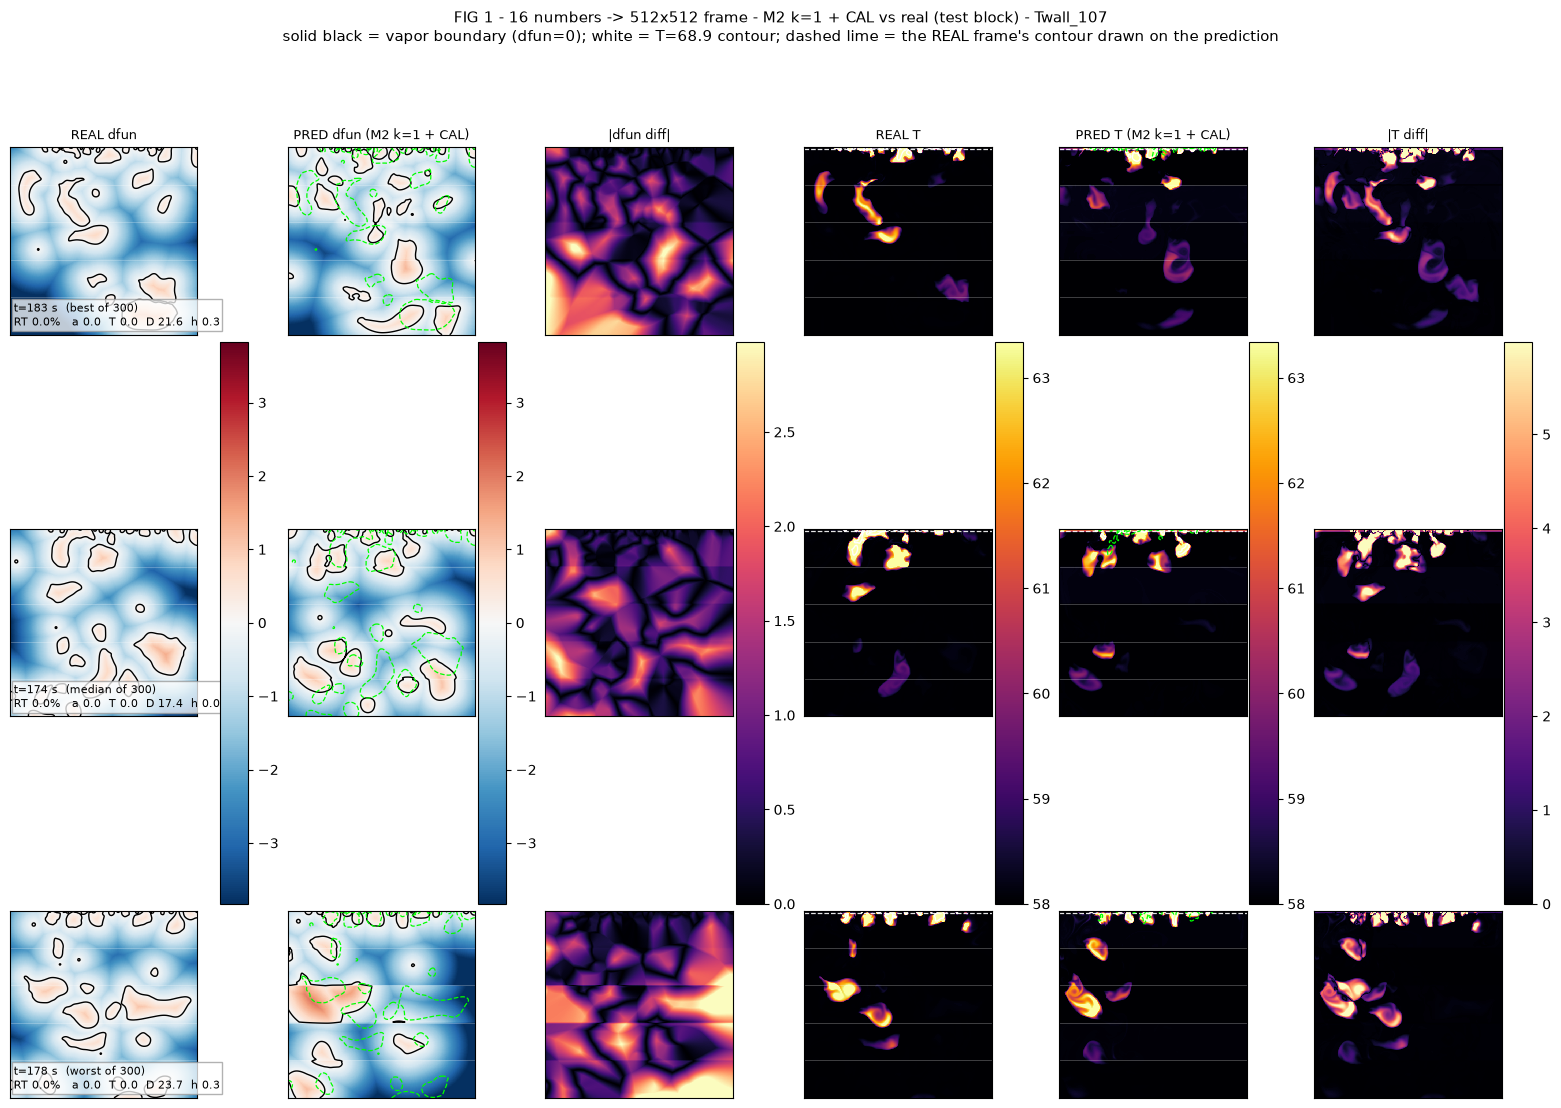

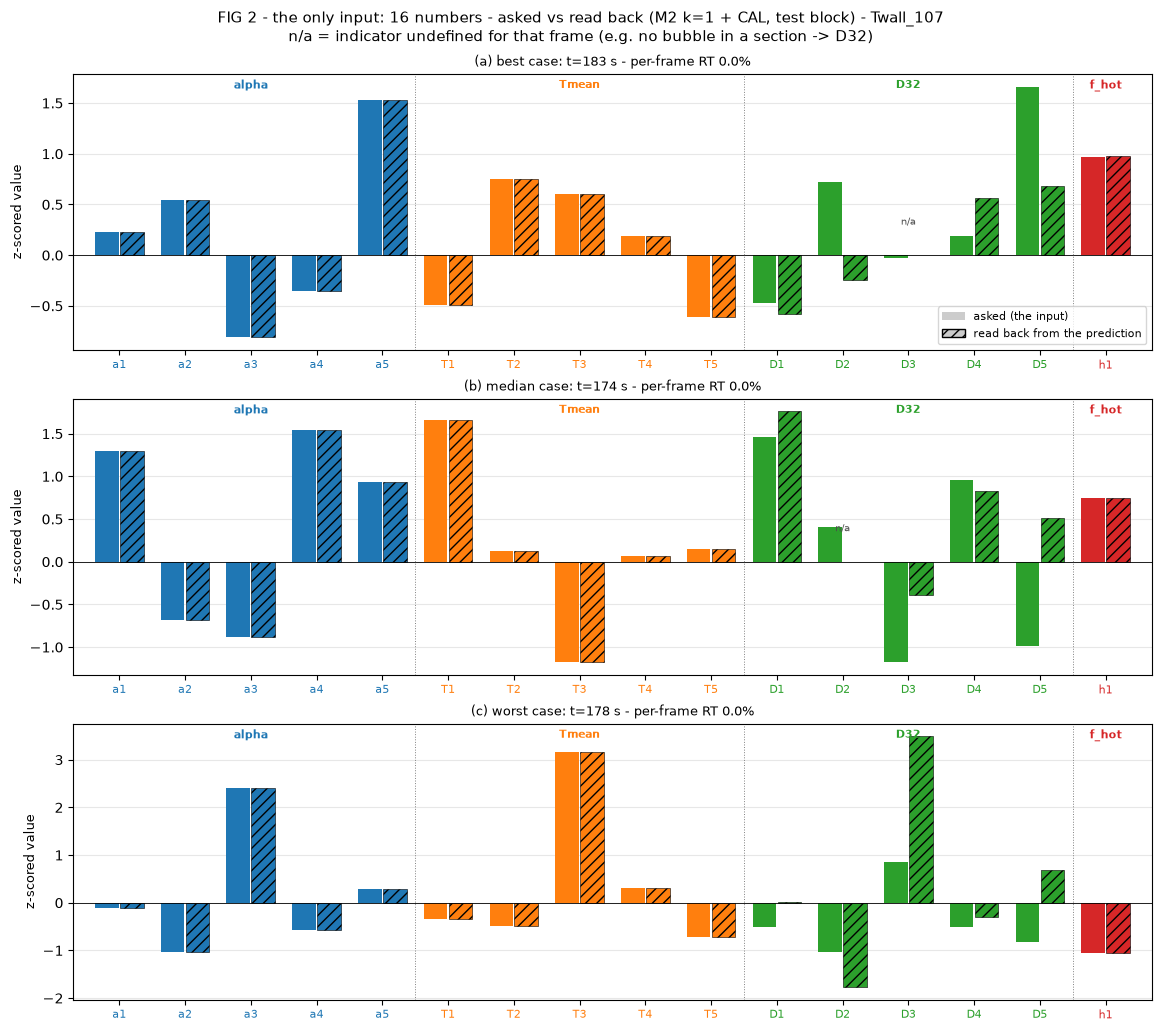

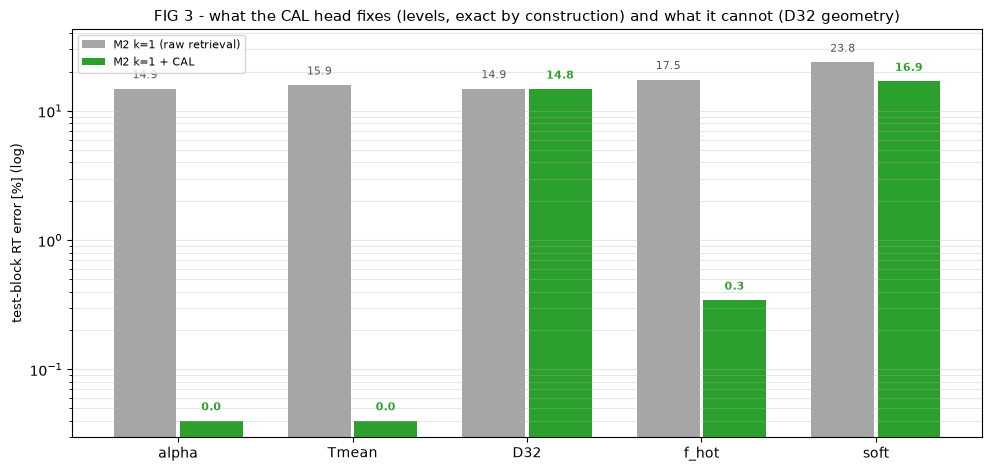


PART II CELL 7 - SHOWCASE: 16 NUMBERS -> FRAME - Twall_107

--------------------------------------------------------------------------------
TABLE 1 - SHOWCASE SUMMARY (test block; per-frame = median over that family's live cols)
--------------------------------------------------------------------------------
frame                 case                retrieved neighbor      alpha %  Tmean %  D32 %  f_hot %  soft %  mean %
--------------------  ------------------  ----------------------  -------  -------  -----  -------  ------  ------
frame 1830 (t=183 s)                best        t=118 s (dt=+65)      0.0      0.0   21.6      0.3    14.2     5.5
frame 1742 (t=174 s)              median  t=46.9 s (dt=+1.3e+02)      0.0      0.0   17.4      0.0     5.1     4.4
frame 1775 (t=178 s)               worst  t=35.1 s (dt=+1.4e+02)      0.0      0.0   23.7      0.3    45.1     6.0
ALL TEST (n=300)      median over frames                       -      0.0      0.0   14.8      0.3    16.9     3.

In [24]:
# ====== PART II CELL 7 / 7 — SHOWCASE: THETA -> FRAME (the best model) =============
# The closing cell of Part II. It picks the best model by ROUND-TRIP ON VAL
# (the test block is never used for any choice), then SHOWS what
# "theta -> frame" actually looks like on the held-out test block:
#   BLOCK A  model selection on val - raw k-NN (the Cell-6 ksweep if its file
#            is fresh, else re-derived here) vs the +CAL variants (the Cell-6
#            consistency head)
#   BLOCK B  test scores of the winner + of raw k-NN (the CAL anatomy), with a
#            deterministic cross-check against the Cell-6 file when fresh
#   BLOCK C  SHOW_N test frames (best / median / worst round-trip):
#              FIG 1  real vs predicted frames (dfun + T + |diff| panels)
#              FIG 2  the asked numbers vs what the extractor reads back
#              FIG 3  what CAL fixes (levels) and what it cannot (D32)
# Runs from out/p2_<TEST>_cache.npz alone (kernel restart is fine); a stale
# or missing Cell-6 npz is handled by re-deriving the val sweep here.
# DYNAMIC: sections, tau, wall band, live columns, theta width - all derived.
import json, os, time
import numpy as np
from scipy import ndimage
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

try: TEST
except NameError: TEST = "Twall_107"
try: DATA_ROOT
except NameError: DATA_ROOT = r"G:\BoilDesc"
try: OUT_DIR
except NameError: OUT_DIR = os.path.join(DATA_ROOT, "out")
W_ = int(globals().get("W_", 80))
for _k, _v in dict(K_GRID7=(1, 2, 3, 5, 9, 15, 25),   # fallback val k-sweep
                   SHOW_N=3).items():                  # showcased test frames
    if _k not in dir():
        globals()[_k] = _v
        print(f"[P2] {_k} not defined -> default {_v}")

def _f(v):
    try: return float(v)
    except (TypeError, ValueError): return float("nan")

def _g(v, fmt="%s"):
    v = _f(v)
    return "n/a" if not np.isfinite(v) else fmt % v

def _render(title, cols, rows, note=None):
    print()
    print("-" * W_)
    print(title)
    print("-" * W_)
    if not rows:
        print("  (nothing to show)")
    else:
        _rs = [[str(c) for c in r] for r in rows]
        _w = [max([len(cols[_c])] + [len(_r[_c]) for _r in _rs])
              for _c in range(len(cols))]
        print("  ".join(cols[_c].ljust(_w[_c])
                        for _c in range(len(cols))).rstrip())
        print("  ".join("-" * _w[_c] for _c in range(len(cols))).rstrip())
        for _r in _rs:
            print("  ".join(_r[_c].ljust(_w[_c]) if _c == 0
                            else _r[_c].rjust(_w[_c])
                            for _c in range(len(cols))).rstrip())
    if note:
        print("  " + note)

# ---- load the Cell-3 cache (the only mandatory input) ----------------------------
_CPATH = os.path.join(OUT_DIR, f"p2_{TEST}_cache.npz")
assert os.path.exists(_CPATH), \
    f"[P2] cache not found ({_CPATH}); run Cells 1-3 first"
with np.load(_CPATH, allow_pickle=False) as _z:
    CM   = json.loads(str(_z["meta"]))
    FR   = np.asarray(_z["frames"])                 # (N,H,W,2) f16 [T, dfun]
    THc  = np.asarray(_z["TH"], float)              # (N, NTH)
    t_c  = np.asarray(_z["t"], float)
    LIVE = np.asarray(_z["live"], int)
    itr, iva, ite = (np.asarray(_z[k], int) for k in ("itr", "iva", "ite"))
    z_mu, z_sd = np.asarray(_z["z_mu"], float), np.asarray(_z["z_sd"], float)
H, W = CM["H"], CM["W"]
nsec, NTH = CM["N_SECTIONS"], CM["NTH"]
tau, edges = float(CM["tau"]), np.asarray(CM["edges"], int)
wall_rows, min_blob = int(CM["WALL_ROWS"]), int(CM["MIN_BLOB_PX"])
ntr, nva, nte = len(itr), len(iva), len(ite)
dt_s = float(np.median(np.diff(t_c))) if len(t_c) > 1 else 1.0
LIVE_set = set(int(j) for j in LIVE)
FAMS = [("alpha", 0, nsec), ("Tmean", nsec, 2 * nsec),
        ("D32", 2 * nsec, 3 * nsec), ("fhot", 3 * nsec, NTH)]
al_live = [j for j in LIVE if 0 <= j < nsec]
NAMES_TH = [f"{_fam}_s{k + 1}" for _fam in ("alpha", "Tmean", "D32", "fhot")
            for k in range(nsec)]
SHORT_TH = {f"{_fam}_s{k + 1}": f"{_s}{k + 1}"
            for _fam, _s in (("alpha", "a"), ("Tmean", "T"), ("D32", "D"),
                             ("fhot", "h")) for k in range(nsec)}
print(f"[P2] cache loaded: {FR.shape[0]} frames {H}x{W}, {ntr}/{nva}/{nte} split, "
      f"{len(LIVE)} live indicators, tau {_g(tau, '%.3g')}")

def theta_of_frame(Tf, d, tau, edges, wall_rows, min_blob):
    """Part-I indicator extractor (keep in sync with Cell 1 / Cell 6)."""
    edges = np.asarray(edges)
    n = len(edges) - 1
    phi = d > 0
    al = np.array([phi[r0:r1, :].astype(np.float64).mean()
                   for r0, r1 in zip(edges[:-1], edges[1:])])
    Tm = np.array([Tf[r0:r1, :].astype(np.float64).mean()
                   for r0, r1 in zip(edges[:-1], edges[1:])])
    lab, nb = ndimage.label(phi)
    dsec = [[] for _ in range(n)]
    if nb:
        ys, xs = np.nonzero(lab); lv = lab[ys, xs]
        cnt = np.bincount(lv)
        cyb = np.bincount(lv, weights=ys.astype(float)) / np.maximum(cnt, 1)
        for i in range(1, nb + 1):
            if cnt[i] < min_blob: continue
            deq = 2.0 * np.sqrt(cnt[i] / np.pi)
            k = int(np.clip(np.searchsorted(edges, cyb[i], side="right") - 1,
                            0, n - 1))
            dsec[k].append(deq)
    D32 = np.full(n, np.nan)
    for k, ds in enumerate(dsec):
        if ds: D32[k] = sum(v ** 3 for v in ds) / sum(v ** 2 for v in ds)
    th = np.concatenate([al, Tm, D32, np.full(n, np.nan)])
    if tau is not None and np.isfinite(tau):
        hot = Tf[:wall_rows, :] > tau
        th[3 * n] = (ndimage.binary_opening(hot, structure=np.ones((2, 2))).sum()
                     / float(hot.size))
    return th

# ---- round-trip scorer (Cell-5/6 conventions: median |err| / block p95-p05) ------
def _rng_block(idx):
    rng = np.full(NTH, np.nan)
    for j in LIVE:
        v = THc[idx, j]
        m = np.isfinite(v)
        if m.any():
            rng[j] = max(float(np.percentile(v[m], 95)
                               - np.percentile(v[m], 5)), 1e-9)
    return rng

_SOFT_CACHE = {}
def _soft_real(idx):
    key = idx.tobytes()
    if key not in _SOFT_CACHE:
        _SOFT_CACHE[key] = {j: np.asarray(
            [float(FR[g, edges[j]:edges[j + 1], :, 1].astype(np.float32).mean())
             for g in idx]) for j in al_live}
    return _SOFT_CACHE[key]

def score_block(fn, idx, tag):
    """Round-trip + pixel scores of fn(i)->(H,W,2) over block idx."""
    n = len(idx)
    THt = THc[idx]
    rng = _rng_block(idx)
    soft_ref = _soft_real(idx)
    rng_soft = {j: max(float(np.percentile(soft_ref[j], 95)
                             - np.percentile(soft_ref[j], 5)), 1e-9)
                for j in al_live}
    E  = {j: np.full(n, np.nan) for j in LIVE}
    ES = {j: np.full(n, np.nan) for j in al_live}
    PX = np.full(n, np.nan)
    for i in range(n):
        P = np.asarray(fn(i), np.float32)
        th = theta_of_frame(P[:, :, 0], P[:, :, 1], tau, edges,
                            wall_rows, min_blob)
        for j in LIVE:
            E[j][i] = abs(th[j] - THt[i, j])
        for j in al_live:
            ES[j][i] = abs(float(P[edges[j]:edges[j + 1], :, 1].mean())
                           - soft_ref[j][i])
        PX[i] = float(np.mean((P - FR[idx[i]].astype(np.float32)) ** 2))
        if (i + 1) % 100 == 0:
            print(f"[P2]   ... {tag}: {i + 1}/{n} frames")
    fam = {}
    for name, j0, j1 in FAMS:
        vals = []
        for j in LIVE:
            if not (j0 <= j < j1) or not np.isfinite(rng[j]):
                continue
            e = E[j] / rng[j]
            vals += [x for x in e if np.isfinite(x)]
        fam[name] = 100 * float(np.median(vals)) if vals else float("nan")
    sv = []
    for j in al_live:
        e = ES[j] / rng_soft[j]
        sv += [x for x in e if np.isfinite(x)]
    fam["soft-a"] = 100 * float(np.median(sv)) if sv else float("nan")
    wf = [fam[f] for f, _a, _b in FAMS if np.isfinite(fam[f])]
    fam["mean"] = float(np.mean(wf)) if wf else float("nan")
    per = np.full(n, np.nan)
    for i in range(n):
        v = [E[j][i] / rng[j] for j in LIVE
             if np.isfinite(rng[j]) and np.isfinite(E[j][i])]
        per[i] = 100 * float(np.median(v)) if v else np.nan
    return {"fam": fam, "per": per,
            "px": float(np.mean(PX)) if np.isfinite(PX).any() else float("nan")}

# ---- k-NN machinery (Cell-4/6 conventions: z-scored live theta, euclidean) -------
_raw = THc[:, LIVE]
Z = np.where(np.isfinite(_raw), (_raw - z_mu) / z_sd, 0.0)
Dva = ((Z[iva][:, None, :] - Z[itr][None, :, :]) ** 2).sum(-1)
Dte = ((Z[ite][:, None, :] - Z[itr][None, :, :]) ** 2).sum(-1)
ova = np.argsort(Dva, axis=1)          # neighbor order (positions within itr)
ote = np.argsort(Dte, axis=1)

def knn_val(i, k):
    return FR[itr[ova[i, :k]]].astype(np.float32).mean(0)

def knn_test(i, k):
    return FR[itr[ote[i, :k]]].astype(np.float32).mean(0)

# ---- consistency calibration CAL (keep in sync with Cell 6) ----------------------
def _sec_shift_field(dsec, box=5):
    """Piecewise-constant per-section shift, box-smoothed over `box` rows so
    the field stays continuous across section boundaries (no seam artifacts
    for the connected-component / D32 statistics downstream)."""
    rows = np.arange(H)
    s = np.clip(np.searchsorted(edges, rows, side="right") - 1, 0, nsec - 1)
    sh = np.asarray(dsec, float)[s]
    if box > 1:
        _pad = box // 2
        sh = np.convolve(np.pad(sh, _pad, mode="edge"),
                         np.ones(box) / box, mode="valid")
    return sh

def _alpha_shift(sec, want):
    """Vertical shift c so that mean(sec + c > 0) hits `want` EXACTLY when the
    value distribution allows it, or the closest achievable count when ties /
    gaps (e.g. distance-transform rings) make the exact fraction unreachable.
    Order statistics, no interpolation -> no random walk inside gaps."""
    v = np.sort(np.asarray(sec, np.float64).ravel())
    Ns = v.size
    m = int(round(want * Ns))
    if m <= 0:
        return -float(v[-1]) - 1.0                # no vapor at all
    if m >= Ns:
        return -float(v[0]) + 1.0                 # everything vapor
    hi_v, lo_v = float(v[Ns - m]), float(v[Ns - m - 1])
    if hi_v > lo_v:
        return -0.5 * (hi_v + lo_v)               # exact: count(A > -c) == m
    u = hi_v                                       # a tie block spans the target
    cnt_gt = int((v > u).sum())
    cnt_ge = int((v >= u).sum())
    if m - cnt_gt <= cnt_ge - m:
        return -u                                 # land just below m
    return -float(np.nextafter(u, -np.inf))       # land just above m

def calibrate(P, th_ask):
    """Re-level ONE prediction (H,W,2 f32) onto the ASKED theta (the model input).
    Tmean  : iterated per-section shift of T until each section MEAN is exact
    f_hot  : bisection shift of the wall band until the EXTRACTOR's opened hot
             fraction is as close as achievable (same 2x2 opening)
    alpha  : order-statistics per-section shift of dfun until each section's
             vapor FRACTION (dfun > 0) is exact (or closest achievable)
    Every objective is measured with the extractor's own arithmetic, and only
    the asked indicators are used (the model's own input) - a deterministic
    output layer, not leakage; M3 can implement it as a differentiable head."""
    P = np.array(P, dtype=np.float32, copy=True)
    T, A = P[:, :, 0], P[:, :, 1]
    n = nsec
    hj = 3 * n                                   # fhot col (wall-band section)
    wantT = {j: float(th_ask[n + j]) for j in range(n)
             if (n + j) in LIVE_set and np.isfinite(th_ask[n + j])}
    wantA = {j: float(np.clip(th_ask[j], 0.0, 1.0)) for j in range(n)
             if j in LIVE_set and np.isfinite(th_ask[j])}
    # --- Tmean <-> f_hot, alternating (the band shift perturbs section-1 mean)
    dT = np.zeros(n)
    for _ in range(5):
        T += _sec_shift_field(dT)[:, None]
        dT = np.zeros(n)
        if hj in LIVE_set and np.isfinite(th_ask[hj]) and wall_rows < H:
            f_t = float(np.clip(th_ask[hj], 0.0, 1.0))
            wb = T[:wall_rows, :]

            def _fh(d):
                hot = wb + d > tau
                return (ndimage.binary_opening(
                    hot, structure=np.ones((2, 2))).sum() / float(hot.size))

            lo, hi = tau - float(wb.max()) - 1.0, tau - float(wb.min()) + 1.0
            for _ in range(40):                   # f increases with delta
                mid = 0.5 * (lo + hi)
                if _fh(mid) > f_t: hi = mid
                else: lo = mid
            fl, fh = _fh(lo), _fh(hi)             # cliff: pick the closer side
            delta = lo if abs(fl - f_t) <= abs(fh - f_t) else hi
            T[:wall_rows, :] += delta
            _tp = min(wall_rows, H - wall_rows)
            T[wall_rows:wall_rows + _tp, :] += \
                delta * np.linspace(1.0, 0.0, _tp)[:, None]
        for j, want in wantT.items():
            dT[j] = want - float(T[edges[j]:edges[j + 1], :].mean())
    # --- alpha: order-statistics targeting, iterated to absorb the box-smoothed
    # field's boundary leak
    dA = np.zeros(n)
    for _ in range(3):
        A += _sec_shift_field(dA)[:, None]
        dA = np.zeros(n)
        for j, want in wantA.items():
            dA[j] = _alpha_shift(A[edges[j]:edges[j + 1], :], want)
    return P

# ================= BLOCK A: model selection ON VAL (test stays untouched) ==========
t0 = time.time()
_C6 = os.path.join(OUT_DIR, f"p2_{TEST}_cell6.npz")
_have6 = (os.path.exists(_C6)
          and os.path.getmtime(_C6) >= os.path.getmtime(_CPATH))
VALK = {}
if _have6:
    with np.load(_C6, allow_pickle=False) as _z6:
        _m6 = json.loads(str(_z6["meta"]))
        _ks6 = np.asarray(_z6["ksweep"], float)
    if _m6.get("label") == TEST and len(_ks6):
        _famL6 = ["alpha", "Tmean", "D32", "fhot", "soft-a"]
        for _r in _ks6:
            _fm = dict(zip(_famL6, [float(x) for x in _r[1:6]]))
            _fm["mean"] = float(_r[6])
            VALK[int(_r[0])] = {"fam": _fm}
        print(f"[P2] val k-sweep reused from the Cell-6 file "
              f"({len(VALK)} k-values)")
    else:
        _have6 = False
if not _have6:
    print("[P2] Cell-6 file stale or missing -> the val k-sweep is re-derived "
          "here (same grid as Cell 6)")
    for k in sorted({int(k) for k in K_GRID7 if 1 <= int(k) <= ntr}):
        VALK[k] = score_block(lambda i, k=k: knn_val(i, k), iva, f"k={k}")
_fin = [(k, VALK[k]["fam"]["mean"]) for k in sorted(VALK)
        if np.isfinite(VALK[k]["fam"]["mean"])]
k_rt = min(_fin, key=lambda kv: kv[1])[0] if _fin else 1
print(f"[P2]   raw k-NN best on val: k={k_rt} "
      f"(mean {_g(VALK[k_rt]['fam']['mean'], '%.1f')}%)  "
      f"[{time.time() - t0:.0f}s]")

VALC = {}
VALC[("cal", k_rt)] = score_block(
    lambda i, k=k_rt: calibrate(knn_val(i, k), THc[iva[i]]), iva, f"k={k_rt}+CAL")
if k_rt != 1 and 1 in VALK:
    VALC[("raw", 1)] = VALK[1]
    VALC[("cal", 1)] = score_block(
        lambda i: calibrate(knn_val(i, 1), THc[iva[i]]), iva, "k=1+CAL")
CAND = {("raw", k_rt): VALK[k_rt]}
CAND.update(VALC)
_best_key = min(((kk, vv["fam"]["mean"]) for kk, vv in CAND.items()
                 if np.isfinite(vv["fam"]["mean"])), key=lambda kv: kv[1])[0]
BEST_K, BEST_CAL = int(_best_key[1]), bool(_best_key[0] == "cal")
_best_label = f"M2 k={BEST_K}" + (" + CAL" if BEST_CAL else "")
print(f"[P2]   BEST ON VAL: {_best_label}  "
      f"(mean {_g(CAND[_best_key]['fam']['mean'], '%.1f')}%)  "
      f"[{time.time() - t0:.0f}s]")

def _pred_best(i):
    base = knn_test(i, BEST_K)
    return calibrate(base, THc[ite[i]]) if BEST_CAL else base

# ================= BLOCK B: test scores (winner + raw k-NN) ========================
print("[P2] Block B: test-block scores (winner + raw k-NN) - first test touch")
T7 = {}
T7["real"] = score_block(lambda i: FR[ite[i]], ite, "real test")
T7[("raw", k_rt)] = score_block(lambda i, k=k_rt: knn_test(i, k), ite,
                                f"raw k={k_rt}")
T7["best"] = score_block(_pred_best, ite, _best_label)
_floor = T7["real"]["fam"]["mean"]
_x6ok = []
if _have6 and _m6.get("k_rt") == k_rt:
    for _ref, _val in ((_m6.get("t2_mean", {}).get("m2krt"),
                        T7[("raw", k_rt)]["fam"]["mean"]),
                       (_m6.get("t2_mean", {}).get("m2krtcal")
                        if (BEST_CAL and BEST_K == k_rt) else None,
                        T7["best"]["fam"]["mean"])):
        if _ref is not None and np.isfinite(_f(_ref)) and np.isfinite(_val):
            _x6ok.append(abs(_val - float(_ref)) < 0.05)
print(f"[P2]   test: raw k={k_rt} "
      f"{_g(T7[('raw', k_rt)]['fam']['mean'], '%.1f')}% -> {_best_label} "
      f"{_g(T7['best']['fam']['mean'], '%.1f')}% "
      f"(floor {_g(_floor, '%.1f')}%)"
      + ("  [cross-check: matches the Cell-6 file exactly]"
         if _x6ok and all(_x6ok) else ""))

# ================= BLOCK C: the showcase (best / median / worst test frames) =======
_nsh = int(max(1, min(int(SHOW_N), nte)))
print(f"[P2] Block C: showcase - {_nsh} test frames "
      "(best / median / worst round-trip)")
per = T7["best"]["per"]
_fmask = np.isfinite(per)
assert _fmask.any(), "[P2] degenerate test block: no finite round-trip errors"
_order = np.flatnonzero(_fmask)[np.argsort(per[_fmask], kind="stable")]

def _tag(q):
    return "best" if q == 0.0 else ("worst" if q == 1.0 else "median")

_pick = []
for q in np.linspace(0.0, 1.0, _nsh):
    i = int(_order[int(round(q * (len(_order) - 1)))])
    if all(p[0] != i for p in _pick):
        _pick.append((i, float(q)))

rng_te = _rng_block(ite)
soft_te = _soft_real(ite)
rng_soft_te = {j: max(float(np.percentile(soft_te[j], 95)
                           - np.percentile(soft_te[j], 5)), 1e-9)
               for j in al_live}

def _fam_one(th_hat, P, g, i):
    """Per-frame family errors (same conventions as score_block, one frame)."""
    fam = {}
    for name, j0, j1 in FAMS:
        vals = [abs(th_hat[j] - THc[g, j]) / rng_te[j] for j in LIVE
                if j0 <= j < j1 and np.isfinite(rng_te[j])
                and np.isfinite(th_hat[j]) and np.isfinite(THc[g, j])]
        fam[name] = 100 * float(np.median(vals)) if vals else float("nan")
    sv = [abs(float(P[edges[j]:edges[j + 1], :, 1].astype(np.float32).mean())
              - float(soft_te[j][i])) / rng_soft_te[j]
          for j in al_live if np.isfinite(rng_soft_te[j])]
    fam["soft-a"] = 100 * float(np.median(sv)) if sv else float("nan")
    wf = [fam[f] for f, _a, _b in FAMS if np.isfinite(fam[f])]
    fam["mean"] = float(np.mean(wf)) if wf else float("nan")
    return fam

_show = []
for i, q in _pick:
    g = int(ite[i])
    P = np.asarray(_pred_best(i), np.float32)
    th_hat = theta_of_frame(P[:, :, 0], P[:, :, 1], tau, edges,
                            wall_rows, min_blob)
    nn_g = int(itr[ote[i, 0]])
    _show.append({"i": int(i), "g": g, "tag": _tag(q), "per": float(per[i]),
                  "P": P, "th_hat": th_hat, "fam": _fam_one(th_hat, P, g, i),
                  "nn": nn_g, "dtn": float(t_c[g] - t_c[nn_g]),
                  "zgap": float(np.sqrt(Dte[i, ote[i, 0]]))})
    print(f"[P2]   {_tag(q)}: test frame {g} (t={t_c[g]:.3g} s), "
          f"RT {per[i]:.1f}%, nearest train t={t_c[nn_g]:.3g} s "
          f"(z-gap {np.sqrt(Dte[i, ote[i, 0]]):.2f})")

# ---- FIG 1: real vs predicted frames ----------------------------------------------
_famL5 = ["alpha", "Tmean", "D32", "fhot", "soft-a"]
_famT = {"alpha": "alpha", "Tmean": "Tmean", "D32": "D32", "fhot": "f_hot",
         "soft-a": "soft"}
_realD = np.stack([FR[ex["g"]][:, :, 1].astype(np.float32) for ex in _show])
_realT = np.stack([FR[ex["g"]][:, :, 0].astype(np.float32) for ex in _show])
_vD = max(float(np.percentile(np.abs(_realD), 98)), 1e-6)
_vT = (float(np.percentile(_realT, 2)), float(np.percentile(_realT, 98)))
_dT = np.stack([np.abs(ex["P"][:, :, 0] - _realT[r])
                for r, ex in enumerate(_show)])
_dD = np.stack([np.abs(ex["P"][:, :, 1] - _realD[r])
                for r, ex in enumerate(_show)])
_vdT = max(float(np.percentile(_dT, 98)), 1e-6)
_vdD = max(float(np.percentile(_dD, 98)), 1e-6)

fig, axs = plt.subplots(len(_show), 6,
                        figsize=(15.5, 3.7 * len(_show) + 0.8),
                        constrained_layout=True)
axs = np.atleast_2d(axs)
_colT = ["REAL dfun", f"PRED dfun ({_best_label})", "|dfun diff|",
         "REAL T", f"PRED T ({_best_label})", "|T diff|"]
_ims = [None] * 6

def _cont(ax, F, lv, colr, ls="solid", lw=1.0):
    fm = np.isfinite(F)
    if fm.any() and float(np.nanmin(F)) < lv < float(np.nanmax(F)):
        ax.contour(F, levels=[lv], colors=colr, linewidths=lw, linestyles=ls)

for r, ex in enumerate(_show):
    R = FR[ex["g"]].astype(np.float32)
    P = ex["P"]
    fields = [(R[:, :, 1], -_vD, _vD, "RdBu_r"),
              (P[:, :, 1], -_vD, _vD, "RdBu_r"),
              (_dD[r], 0.0, _vdD, "magma"),
              (R[:, :, 0], _vT[0], _vT[1], "inferno"),
              (P[:, :, 0], _vT[0], _vT[1], "inferno"),
              (_dT[r], 0.0, _vdT, "magma")]
    for c, (F, vl, vh, cm) in enumerate(fields):
        ax = axs[r, c]
        im = ax.imshow(F, vmin=vl, vmax=vh, cmap=cm, interpolation="nearest")
        if _ims[c] is None:
            _ims[c] = im
        if c in (0, 1, 3, 4):
            for e in edges[1:-1]:
                ax.axhline(e, color="w", lw=0.5, alpha=0.35)
        if c in (3, 4) and 0 < wall_rows < H:
            ax.axhline(wall_rows, color="w", lw=0.9, ls="--", alpha=0.9)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(_colT[c], fontsize=9.5)
    _cont(axs[r, 0], R[:, :, 1], 0.0, "k")
    _cont(axs[r, 1], P[:, :, 1], 0.0, "k")
    _cont(axs[r, 1], R[:, :, 1], 0.0, "lime", ls="dashed", lw=0.9)
    _cont(axs[r, 3], R[:, :, 0], tau, "w")
    _cont(axs[r, 4], P[:, :, 0], tau, "w")
    _cont(axs[r, 4], R[:, :, 0], tau, "lime", ls="dashed", lw=0.9)
    _fe = ex["fam"]
    axs[r, 0].text(
        0.02, 0.03,
        f"t={t_c[ex['g']]:.3g} s  ({ex['tag']} of {int(_fmask.sum())})\n"
        f"RT {ex['per']:.1f}%   a {_g(_fe['alpha'], '%.1f')}  "
        f"T {_g(_fe['Tmean'], '%.1f')}  D {_g(_fe['D32'], '%.1f')}  "
        f"h {_g(_fe['fhot'], '%.1f')}",
        transform=axs[r, 0].transAxes, fontsize=8, va="bottom", color="k",
        bbox=dict(fc="white", ec="0.6", alpha=0.75, pad=1.5))
for c in range(6):
    fig.colorbar(_ims[c], ax=axs[:, c].tolist(), shrink=0.85, pad=0.015)
fig.suptitle(f"FIG 1 - {len(LIVE)} numbers -> {H}x{W} frame - {_best_label} vs "
             f"real (test block) - {TEST}\nsolid black = vapor boundary "
             f"(dfun=0); white = T={_g(tau, '%.3g')} contour; dashed lime = the "
             f"REAL frame's contour drawn on the prediction", fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_cell7_frames.png"), dpi=150)
plt.show()

# ---- FIG 2: the asked numbers vs what the extractor reads back --------------------
fig, axs2 = plt.subplots(len(_show), 1,
                         figsize=(11.5, 3.1 * len(_show) + 0.9),
                         constrained_layout=True, squeeze=False)
_famcol = {0: "C0", 1: "C1", 2: "C2", 3: "C3"}
_famN4 = ["alpha", "Tmean", "D32", "f_hot"]
_fam_of = [0 if j < nsec else 1 if j < 2 * nsec else 2 if j < 3 * nsec else 3
           for j in LIVE]
_short_live = [SHORT_TH[NAMES_TH[j]] for j in LIVE]
_x = np.arange(len(LIVE))
for r, ex in enumerate(_show):
    ax = axs2[r, 0]
    a_raw = THc[ex["g"], LIVE]
    h_raw = ex["th_hat"][LIVE]
    az = (a_raw - z_mu) / z_sd
    hz = (h_raw - z_mu) / z_sd
    for c in range(len(LIVE)):
        if np.isfinite(az[c]):
            ax.bar(_x[c] - 0.19, az[c], 0.36, color=_famcol[_fam_of[c]],
                   edgecolor="none", zorder=2)
        if np.isfinite(hz[c]):
            ax.bar(_x[c] + 0.19, hz[c], 0.36, color=_famcol[_fam_of[c]],
                   hatch="///", edgecolor="k", linewidth=0.4, zorder=2)
        if not (np.isfinite(az[c]) and np.isfinite(hz[c])):
            ax.annotate("n/a", (_x[c], 0.0), xytext=(0, 22),
                        textcoords="offset points", ha="center", fontsize=7,
                        color="0.3")
    ax.axhline(0.0, color="k", lw=0.6)
    for b in [i for i in range(1, len(LIVE)) if _fam_of[i] != _fam_of[i - 1]]:
        ax.axvline(b - 0.5, color="0.5", lw=0.7, ls=":")
    y0, y1 = ax.get_ylim()
    for fi in range(4):
        _idx = [i for i, f in enumerate(_fam_of) if f == fi]
        if _idx:
            ax.text(np.mean(_idx), y1 - 0.02 * (y1 - y0), _famN4[fi],
                    ha="center", va="top", fontsize=8, color=_famcol[fi],
                    fontweight="bold")
    ax.set_xticks(_x)
    ax.set_xticklabels(_short_live, fontsize=8)
    for tick, fi in zip(ax.get_xticklabels(), _fam_of):
        tick.set_color(_famcol[fi])
    ax.set_xlim(-0.7, len(LIVE) - 0.3)
    ax.set_ylabel("z-scored value", fontsize=9)
    ax.set_title(f"({chr(97 + r)}) {ex['tag']} case: t={t_c[ex['g']]:.3g} s - "
                 f"per-frame RT {ex['per']:.1f}%", fontsize=9.5)
    ax.grid(axis="y", alpha=0.3)
axs2[0, 0].legend(handles=[Patch(facecolor="0.8", label="asked (the input)"),
                           Patch(facecolor="0.8", hatch="///", edgecolor="k",
                                 label="read back from the prediction")],
                  fontsize=8, loc="lower right")
fig.suptitle(f"FIG 2 - the only input: {len(LIVE)} numbers - asked vs read back "
             f"({_best_label}, test block) - {TEST}\nn/a = indicator undefined "
             f"for that frame (e.g. no bubble in a section -> D32)", fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_cell7_theta.png"), dpi=150)
plt.show()

# ---- FIG 3: what CAL fixes and what it cannot -------------------------------------
fig, ax3 = plt.subplots(figsize=(9.8, 4.6), constrained_layout=True)
_x3 = np.arange(len(_famL5))
_rawF = [T7[("raw", k_rt)]["fam"][f] for f in _famL5]
_besF = [T7["best"]["fam"][f] for f in _famL5]

def _cl(v):
    v = _f(v)
    return max(v, 0.04) if np.isfinite(v) else np.nan

_xr = [x - 0.19 for x, v in zip(_x3, _rawF) if np.isfinite(_f(v))]
_yr = [_cl(v) for v in _rawF if np.isfinite(_f(v))]
_xb = [x + 0.19 for x, v in zip(_x3, _besF) if np.isfinite(_f(v))]
_yb = [_cl(v) for v in _besF if np.isfinite(_f(v))]
ax3.bar(_xr, _yr, 0.36, color="0.65", label=f"M2 k={k_rt} (raw retrieval)")
ax3.bar(_xb, _yb, 0.36, color="C2", label=_best_label)
for xi, v in zip(_x3 - 0.19, _rawF):
    if np.isfinite(_f(v)):
        ax3.text(xi, _cl(v) * 1.15, _g(v, "%.1f"), ha="center", va="bottom",
                 fontsize=8, color="0.35")
for xi, v in zip(_x3 + 0.19, _besF):
    if np.isfinite(_f(v)):
        ax3.text(xi, _cl(v) * 1.15, _g(v, "%.1f"), ha="center", va="bottom",
                 fontsize=8, color="C2", fontweight="bold")
for x, v in zip(_x3, _rawF):
    if not np.isfinite(_f(v)):
        ax3.text(x, 0.06, "n/a", ha="center", fontsize=8, color="0.4")
_top = max([_f(v) for v in _rawF + _besF if np.isfinite(_f(v))] or [10.0])
ax3.set_yscale("log")
ax3.set_ylim(0.03, max(30.0, 1.8 * _top))
ax3.set_xticks(_x3, [_famT[f] for f in _famL5])
ax3.set_ylabel("test-block RT error [%] (log)", fontsize=9)
ax3.grid(axis="y", alpha=0.3, which="both")
ax3.legend(fontsize=8)
ax3.set_title("FIG 3 - what the CAL head fixes (levels, exact by construction) "
              "and what it cannot (D32 geometry)", fontsize=11)
fig.savefig(os.path.join(OUT_DIR, f"p2_{TEST}_cell7_cal.png"), dpi=150)
plt.show()

# ================= TABLES ===========================================================
print()
print("=" * W_)
print(f"PART II CELL 7 - SHOWCASE: {len(LIVE)} NUMBERS -> FRAME - {TEST}")
print("=" * W_)
_what = ("the nearest-theta training frame re-leveled onto the asked theta"
         if BEST_K == 1 else
         f"the mean of the {BEST_K} nearest-theta training frames re-leveled "
         "onto the asked theta")
_rows1 = []
for ex in _show:
    _fe = ex["fam"]
    _rows1.append([f"frame {ex['g']} (t={t_c[ex['g']]:.3g} s)", ex["tag"],
                   f"t={t_c[ex['nn']]:.3g} s (dt={ex['dtn']:+.2g})",
                   _g(_fe["alpha"], "%5.1f"), _g(_fe["Tmean"], "%5.1f"),
                   _g(_fe["D32"], "%5.1f"), _g(_fe["fhot"], "%5.1f"),
                   _g(_fe["soft-a"], "%5.1f"), _g(_fe["mean"], "%5.1f")])
_bF = T7["best"]["fam"]
_rows1.append([f"ALL TEST (n={nte})", "median over frames", "-",
               _g(_bF["alpha"], "%5.1f"), _g(_bF["Tmean"], "%5.1f"),
               _g(_bF["D32"], "%5.1f"), _g(_bF["fhot"], "%5.1f"),
               _g(_bF["soft-a"], "%5.1f"), _g(_bF["mean"], "%5.1f")])
_rows1.append(["real (self-check)", "the cached frames", "-"]
              + [_g(T7["real"]["fam"][f], "%5.1f") for f in _famL5]
              + [_g(_floor, "%5.1f")])
_render("TABLE 1 - SHOWCASE SUMMARY (test block; per-frame = median over that "
        "family's live cols)",
        ["frame", "case", "retrieved neighbor", "alpha %", "Tmean %", "D32 %",
         "f_hot %", "soft %", "mean %"], _rows1,
        f"the prediction is {_what}: its bubbles are real and sharp, but "
        "PLACED as in the retrieved neighbor - the |diff| panels of FIG 1 and "
        "the D32 column are exactly the retrieval gap M3 must learn to "
        "interpolate.")

_rows2 = [["real (self-check)", "-", _g(_floor, "%5.1f"), "-", "storage floor"]]
for _kk in [("raw", k_rt)] + [k2 for k2 in [("cal", k_rt), ("raw", 1),
                                             ("cal", 1)] if k2 in CAND]:
    _vm = CAND[_kk]["fam"]["mean"]
    if _kk == ("raw", k_rt):
        _tm, _note = T7[("raw", k_rt)]["fam"]["mean"], "raw retrieval (no head)"
    elif _kk == _best_key:
        _tm, _note = T7["best"]["fam"]["mean"], "<-- THE SHOWCASED MODEL"
    else:
        _tm, _note = float("nan"), "never touched the test block"
    _rows2.append([f"M2 k={_kk[1]}" + (" + CAL" if _kk[0] == "cal" else ""),
                   _g(_vm, "%5.1f"), _g(_tm, "%5.1f"),
                   _g(_tm - _floor, "%+5.1f") if np.isfinite(_tm) else "-",
                   _note])
_render("TABLE 2 - MODEL SELECTION (val only) AND THE FIRST TEST TOUCH",
        ["model", "val mean %", "test mean %", "d vs real", "note"], _rows2,
        ("selection used the val block exclusively; the raw and winner rows "
         "reproduce the Cell-6 test numbers exactly (deterministic)."
         if _x6ok and all(_x6ok) else
         "selection used the val block exclusively; test numbers are computed "
         "here for the first time."))

_fns7 = [f"p2_{TEST}_cell7.npz", f"p2_{TEST}_cell7_frames.png",
         f"p2_{TEST}_cell7_theta.png", f"p2_{TEST}_cell7_cal.png"]
_rows3 = [[fn, f"{os.path.getsize(os.path.join(OUT_DIR, fn)) / 1e3:.1f} KB",
           "present" if os.path.exists(os.path.join(OUT_DIR, fn)) else "MISSING"]
          for fn in _fns7 if os.path.exists(os.path.join(OUT_DIR, fn))]
_render("TABLE 3 - ARTIFACTS ON DISK", ["file", "size", "status"], _rows3)

# ================= TAKEAWAY =========================================================
print()
print("=" * W_)
print("TAKEAWAY")
print("=" * W_)
print(f"  best model     : {_best_label} (selected on val: "
      f"{_g(CAND[_best_key]['fam']['mean'], '%.1f')}% vs raw "
      f"{_g(VALK[k_rt]['fam']['mean'], '%.1f')}%)")
print(f"  test round-trip: {_g(T7['best']['fam']['mean'], '%.1f')}% "
      f"(raw k={k_rt} {_g(T7[('raw', k_rt)]['fam']['mean'], '%.1f')}%, "
      f"floor {_g(_floor, '%.1f')}%)")
print(f"  levels         : alpha {_g(_bF['alpha'], '%.1f')}% / Tmean "
      f"{_g(_bF['Tmean'], '%.1f')}% / f_hot {_g(_bF['fhot'], '%.1f')}% - exact "
      "by construction (the CAL head re-levels onto the asked theta)")
print(f"  geometry       : D32 {_g(_bF['D32'], '%.1f')}% - the retrieval gap; "
      "see the |diff| panels: the neighbor's real bubbles, re-leveled")
print(f"  success bar    : M3 must beat "
      f"{_g(T7['best']['fam']['mean'], '%.1f')}% on THIS test block, with the "
      "same CAL head as its output layer")

# ================= save =============================================================
_th_asked = np.stack([THc[ex["g"]] for ex in _show])
_th_hat = np.stack([ex["th_hat"] for ex in _show])
_fam_show = np.asarray([[ex["fam"][f] for f in _famL5] for ex in _show], float)
_meta7 = {"label": TEST, "n_live": int(len(LIVE)), "k_rt": int(k_rt),
          "best": [BEST_K, BEST_CAL], "best_label": _best_label,
          "val_mean": {f"{c}_{k}": _f(v["fam"]["mean"])
                      for (c, k), v in CAND.items()},
          "test_mean": {"raw": _f(T7[("raw", k_rt)]["fam"]["mean"]),
                        "best": _f(T7["best"]["fam"]["mean"]),
                        "real": _f(_floor)},
          "fam_best_test": {f: _f(T7["best"]["fam"][f]) for f in _famL5},
          "fam_raw_test": {f: _f(T7[("raw", k_rt)]["fam"][f]) for f in _famL5},
          "have6": bool(_have6),
          "show": [{"g": ex["g"], "i": ex["i"], "tag": ex["tag"],
                    "per": ex["per"], "nn": ex["nn"], "dtn": ex["dtn"],
                    "zgap": ex["zgap"]} for ex in _show]}
np.savez_compressed(os.path.join(OUT_DIR, f"p2_{TEST}_cell7.npz"),
                    meta=json.dumps(_meta7),
                    per_test=T7["best"]["per"],
                    per_raw=T7[("raw", k_rt)]["per"],
                    th_asked=_th_asked, th_hat=_th_hat, fam_show=_fam_show,
                    show_g=np.asarray([ex["g"] for ex in _show], int),
                    show_i=np.asarray([ex["i"] for ex in _show], int),
                    show_nn=np.asarray([ex["nn"] for ex in _show], int))
print()
print(f"[P2] saved: p2_{TEST}_cell7.npz (+ _frames/_theta/_cal .png)")
print(f"[P2] Cell 7 complete - Part II closes here: {len(LIVE)} numbers -> "
      f"{H}x{W} frame at {_g(T7['best']['fam']['mean'], '%.1f')}% round-trip "
      "on the held-out block. Next (M3): learn the geometry the retrieval "
      "cannot interpolate, with the CAL head as the output layer.")
